# Geometry-Aware Quantum Cloud Challenge submission

**Team:** QCCR  
**Members:** Clement Wright, Raymond Zhang  
**Repository / base commit:** https://github.com/Clement-Wright/Geometry-Aware-Quantum-Cloud-Challenge-QCCR.git / e7d5ad8 (Levels 4 and 5 branch) 

Complete Levels 1 to 3 for all three official processor models. Read the challenge brief and practice tutorial first. Load the shared inputs from `challenge_config.py`; keep the official benchmark separate from optional studies. All solution code and results are yours to supply.

Success means a reproducible comparison of routing and protection tradeoffs across all nine cases. Protection need not improve fidelity, and the hyperbolic model need not win. Explain negative results using your measured costs, uncertainty and yield. All required runs are local simulations; no IBM account or QPU access is needed.


## Setup and reproducibility

Record package versions, simulator and transpiler seeds, shots **per basis**, bootstrap settings, optimization level, layout and routing settings. Use independent simulator seeds for XX, YY and ZZ. Explain any differences in compilation between models. Start Jupyter from this repository with `uv run jupyter lab challenge_submission.ipynb`.


In [1]:
import platform
from importlib.metadata import version

import importlib.metadata as md
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, partial_trace, state_fidelity
from qiskit.transpiler.passes import RemoveBarriers
from qiskit_aer import AerSimulator

import challenge_config as cfg
from challenge_config import (
    BOOTSTRAP_RESAMPLES, CASES, CONFIDENCE_LEVEL, CONFIG_VERSION, PROCESSORS,
    SEED, SHOTS_PER_BASIS, SYNTHETIC_BASIS_GATES, get_ibm_backend, make_noise_model,
)

from simulation_seeds import aer_seed

BASES = ("ZZ", "XX", "YY")
TRANSPILE_OPT_LEVEL = 1

CASE_NUMBER = 1
BASIS_ORDER = ("XX", "YY", "ZZ")
SIMULATOR_METHOD = "matrix_product_state"
OPTIMIZATION_LEVEL = 0
processor_id = "reference_2016"
spec = PROCESSORS[processor_id]
case1_simulator_seeds = {basis: aer_seed(SEED + 100 * CASE_NUMBER, basis)
                         for basis in BASIS_ORDER}
case1_bootstrap_seeds = {
    basis: SEED + 100 * CASE_NUMBER + 10 + BASES.index(basis) for basis in BASIS_ORDER
}
case1_settings = {
    "Case": CASE_NUMBER,
    "Processor": processor_id,
    "Configuration version": CONFIG_VERSION,
    "Physical ports": spec.ports,
    "Noise": "off",
    "Native basis": SYNTHETIC_BASIS_GATES,
    "Simulator method": "automatic",
    "Shots per basis": SHOTS_PER_BASIS,
    "Simulator seeds": case1_simulator_seeds,
    "Transpiler seed": SEED + 100 * CASE_NUMBER + 20,
    "Routed initial layout": nx.shortest_path(nx.Graph(spec.edges), *spec.ports),
    "Native initial layout": list(range(spec.num_qubits)),
    "Routing method": "none (explicit SWAPs already supplied)",
    "Routed optimization level": 0,
    "Native optimization level": TRANSPILE_OPT_LEVEL,
    "Bootstrap resamples": BOOTSTRAP_RESAMPLES,
    "Confidence level": CONFIDENCE_LEVEL,
    "Bootstrap seeds": case1_bootstrap_seeds,
}
display(pd.Series(case1_settings, name="Value").to_frame())
display(pd.DataFrame([
    {"Package": "Python", "Version": platform.python_version()},
    *({"Package": package, "Version": version(package)}
      for package in ("qiskit", "qiskit-aer", "qiskit-ibm-runtime")),
]))

BASIS_ORDER = ("XX", "YY", "ZZ")
LEVEL2_CASES = tuple(case for case in CASES if case[2] == 2)
SIMULATOR_METHOD = "matrix_product_state"
OPTIMIZATION_LEVEL = 0
SIMULATOR_OPTIONS = {
    "reference_2016": {"max_parallel_threads": 1},
    "ibm_today": {"max_parallel_threads": 1, "max_parallel_experiments": 1,
                  "max_memory_mb": 512, "shot_branching_enable": False,
                  "shot_branching_sampling_enable": False},
    "hyperbolic": {"max_parallel_threads": 1},
}
SIMULATOR_METHODS = {pid: "density_matrix" if pid == "ibm_today" else SIMULATOR_METHOD
                     for pid in PROCESSORS}

# MPS stores the 35-qubit state as a chain of smaller tensors.
# Record its sampling options alongside the seeds for repeatability.
run_settings = {
    "Configuration version": CONFIG_VERSION,
    "Cases": [case_number for case_number, _, _ in LEVEL2_CASES],
    "Noise": "official Level 2 model",
    "Simulator methods": SIMULATOR_METHODS, "Simulator options": SIMULATOR_OPTIONS,
    "Shots per basis": SHOTS_PER_BASIS, "Base seed": SEED,
    "Simulator seed rule": "aer_seed(base + 100 * case, basis); audited disjoint shot ranges",
    "Compilation": "reuse Level 1 routed and native circuits",
    "Routed optimization level": 0, "Native optimization level": TRANSPILE_OPT_LEVEL,
    "Transpiler seed rule": "base + 100 * source ideal case + 20",
    "Layout": "Level 1 path placement, then identity native layout", "Routing": "explicit SWAPs; automatic routing off",
    "Bootstrap resamples": BOOTSTRAP_RESAMPLES, "Confidence level": CONFIDENCE_LEVEL,
    "Bootstrap seed rule": "base + 100 * case + 10",
}
display(pd.Series(run_settings, name="Value").to_frame())
display(pd.DataFrame([
    {"Package": "Python", "Version": platform.python_version()},
    *({"Package": package, "Version": version(package)} for package in
      ("qiskit", "qiskit-aer", "qiskit-ibm-runtime", "numpy", "networkx", "pandas", "matplotlib")),
]))

# Load IBM FakeGuadalupeV2 backend
ibm_backend = get_ibm_backend()
ibm_backend_record = {
    "Backend": ibm_backend.name,
    "Class": f"{type(ibm_backend).__module__}.{type(ibm_backend).__name__}",
    "Snapshot update": str(ibm_backend.properties().last_update_date),
    "Target operations": sorted(ibm_backend.operation_names),
}
display(pd.Series(ibm_backend_record, name="Value").to_frame())

,Value
Case,1
Processor,reference_2016
Configuration version,1.0
Physical ports,"(0, 3)"
Noise,off
Native basis,"(u, cx)"
Simulator method,automatic
Shots per basis,8192
Simulator seeds,"{'XX': 2905751833047273, 'YY': 297035962193582..."
Transpiler seed,2146


,Package,Version
0,Python,3.12.15
1,qiskit,2.4.1
2,qiskit-aer,0.17.2
3,qiskit-ibm-runtime,0.51.0


,Value
Configuration version,1.0
Cases,"[2, 5, 8]"
Noise,official Level 2 model
Simulator methods,"{'reference_2016': 'matrix_product_state', 'ib..."
Simulator options,{'reference_2016': {'max_parallel_threads': 1}...
Shots per basis,8192
Base seed,2026
Simulator seed rule,"aer_seed(base + 100 * case, basis); audited di..."
Compilation,reuse Level 1 routed and native circuits
Routed optimization level,0


,Package,Version
0,Python,3.12.15
1,qiskit,2.4.1
2,qiskit-aer,0.17.2
3,qiskit-ibm-runtime,0.51.0
4,numpy,2.5.4
5,networkx,3.7
6,pandas,3.1.0
7,matplotlib,3.11.2


,Value
Backend,fake_guadalupe
Class,qiskit_ibm_runtime.fake_provider.backends.guad...
Snapshot update,2021-04-20 07:26:31+02:00
Target operations,"[cx, delay, id, measure, reset, rz, sx, x]"


## Official graphs and ports

Draw all three coupling graphs, label physical qubits and highlight each fixed port pair. State the noise model and native gates for each processor. For the IBM model, record the exact fake backend and package version. Explain how the final physical locations of the Bell pair will be verified.

Use `challenge_config.PROCESSORS` for the three specs (`edges`, `ports`, `num_qubits`, `coupling_map()`), `CASES` for case numbering, and `get_ibm_backend()` / `make_noise_model(processor_id)` for the fixed backend and noise. See the README for gate bases and sampling defaults. The IBM snapshot is bundled with `qiskit-ibm-runtime==0.51.0`; do not refresh it.


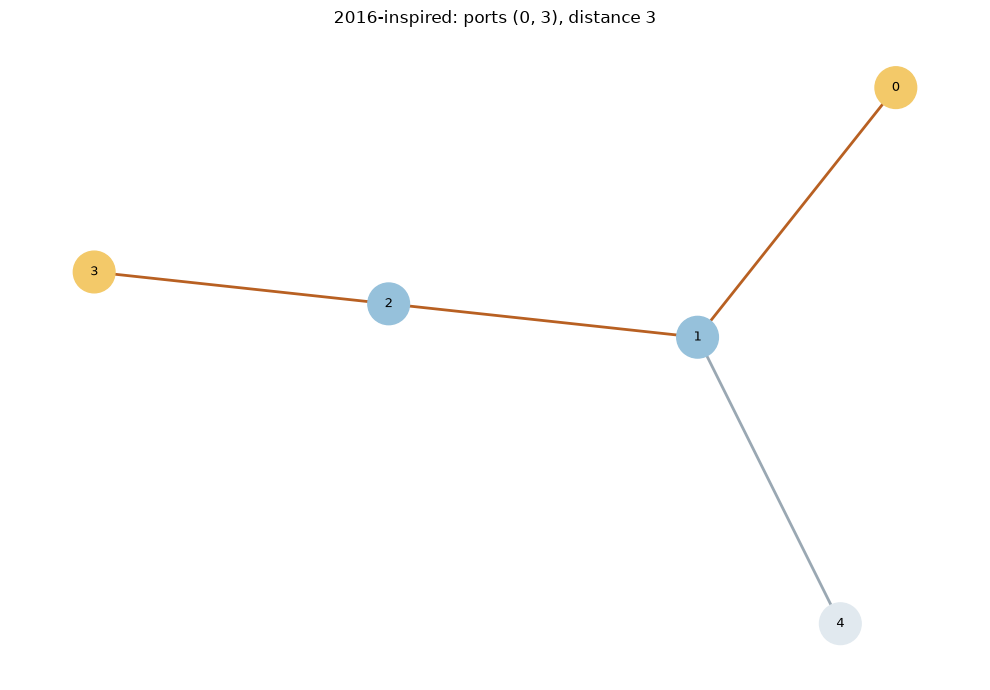

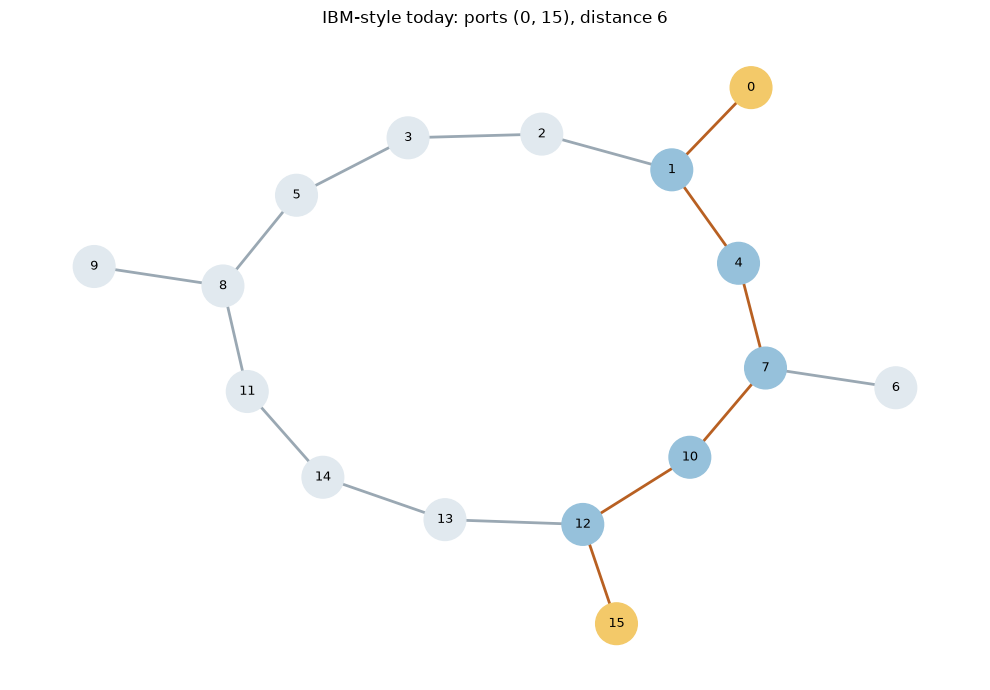

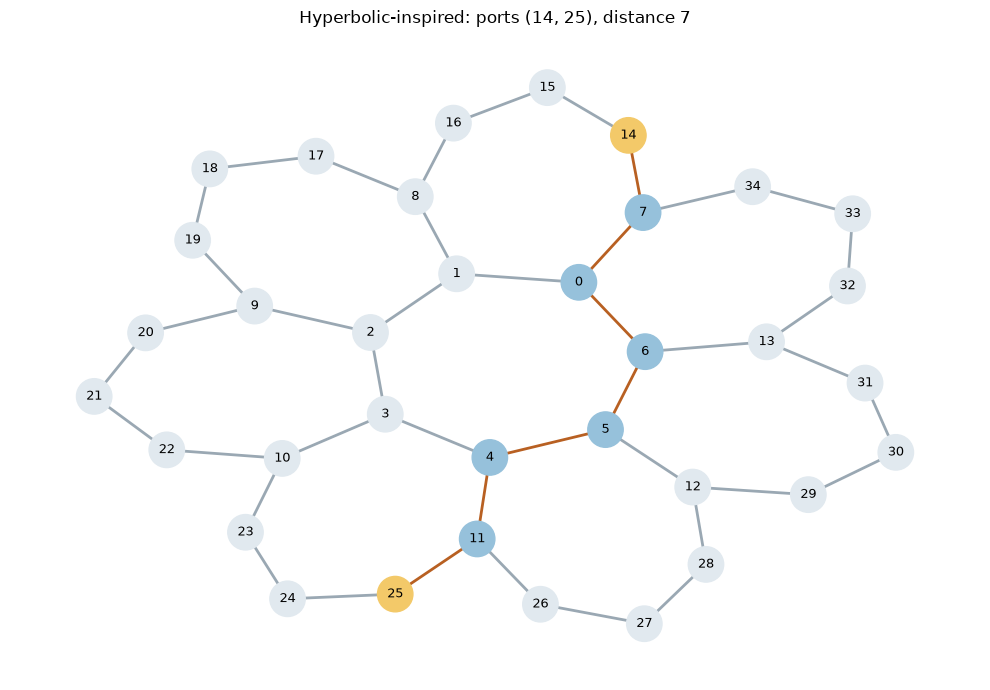

,Processor,Physical ports,Physical qubits,Undirected edges,Route,Port distance
0,reference_2016,"(0, 3)",5,4,"[0, 1, 2, 3]",3
1,ibm_today,"(0, 15)",16,16,"[0, 1, 4, 7, 10, 12, 15]",6
2,hyperbolic,"(14, 25)",35,42,"[14, 7, 0, 6, 5, 4, 11, 25]",7


In [2]:
processor_graphs, processor_routes = {}, {}
graph_rows = []
for model_id, model in PROCESSORS.items():
    graph = nx.Graph()
    graph.add_nodes_from(range(model.num_qubits))
    graph.add_edges_from(model.edges)

    # Draw each bidirectional coupling as one connection between physical qubits.
    # Choose a path with the fewest edges between the fixed ports.
    route = nx.shortest_path(graph, *model.ports)
    processor_graphs[model_id] = graph
    processor_routes[model_id] = route
    graph_rows.append({
        "Processor": model_id, "Physical ports": model.ports,
        "Physical qubits": model.num_qubits, "Undirected edges": graph.number_of_edges(),
        "Route": route, "Port distance": len(route) - 1,
    })
    node_colors = ["#f3c969" if qubit in model.ports else
                   "#96c1db" if qubit in route else "#e1e9ef" for qubit in graph.nodes]
    route_edges = {frozenset(edge) for edge in zip(route, route[1:])}
    edge_colors = ["#b86022" if frozenset(edge) in route_edges else "#9aa8b3"
                   for edge in graph.edges]
    figure, axis = plt.subplots(figsize=(10, 7))
    nx.draw_networkx(
        graph, pos=nx.kamada_kawai_layout(graph), node_color=node_colors,
        edge_color=edge_colors, node_size=650 if model.num_qubits > 20 else 900,
        font_size=9, width=2, ax=axis,
    )
    axis.set_title(f"{model.name}: ports {model.ports}, distance {len(route) - 1}")
    axis.set_axis_off()
    figure.tight_layout()
    display(figure)
    plt.close(figure)

display(pd.DataFrame(graph_rows))

## Level 1 — Make it: an ideal Bell pair

**Cases 1, 4, 7:** 2016-inspired, IBM-style today, hyperbolic-inspired.

Prepare the target Bell state on each model's two fixed ports. Compile for the relevant connectivity and gate set, verify the final physical locations, and draw the transpiled circuits. Measure XX, YY and ZZ without noise and estimate Bell fidelity. Record depth, two-qubit gates, SWAPs before decomposition, and physical qubits actually used. Follow the README common reporting conventions: the table uses the complete ZZ circuit, depth includes measurements with barriers excluded, and two-qubit gates are counted after native-gate decomposition. Preserve the routed circuit to count SWAPs before decomposition. Report XX and YY costs, including their basis rotations, separately.


In [3]:
# ---- Reproducibility record -------------------------------------------------
print("challenge_config", cfg.CONFIG_VERSION, "| IBM backend", cfg.IBM_BACKEND_CLASS)
print({p: md.version(p) for p in ("qiskit", "qiskit-aer", "qiskit-ibm-runtime", "networkx", "numpy")})
print(f"base seed {SEED} | shots per basis {SHOTS_PER_BASIS} | "
      f"bootstrap {BOOTSTRAP_RESAMPLES} resamples, {CONFIDENCE_LEVEL:.0%} interval")


def case_seed(case, basis, kind):
    """Distinct seed per case and basis. kind: 0 = Aer simulator, 1 = bootstrap."""
    if kind == 0:
        return aer_seed(SEED + 100 * case, basis)
    return SEED + 100 * case + 10 * kind + BASES.index(basis)

def transpiler_seed(case):
    return SEED + 100 * case + 20

# ---- Measurement helpers (same conventions as the tutorial) -----------------
def bits(key):
    """Counts key -> string where bits(key)[i] is classical bit i."""
    return key.replace(" ", "")[::-1]

def correlator(counts, i=0, j=1):
    """Mean of (+1 if clbits i and j agree, else -1) over all shots."""
    agree = sum(n for key, n in counts.items() if bits(key)[i] == bits(key)[j])
    return (2 * agree - sum(counts.values())) / sum(counts.values())

def add_basis_rotation(qc, qubits, basis):
    """Append gates so a Z measurement of `qubits` reads the basis named by `basis`
    ("ZZ", "XX", "YY" or a single letter): Z adds nothing, X adds H, Y adds Sdg then H."""
    axis = basis[0]
    if axis not in "XYZ":
        raise ValueError(f"unknown basis {basis!r}")
    for q in qubits:
        if axis == "Y":
            qc.sdg(q)
        if axis in "XY":
            qc.h(q)

def measured_qubits(tqc):
    """{classical bit: physical qubit it measures} for a transpiled circuit."""
    return {tqc.find_bit(i.clbits[0]).index: tqc.find_bit(i.qubits[0]).index
            for i in tqc.data if i.operation.name == "measure"}

# ---- Fidelity with a bootstrap interval -------------------------------------
def fidelity_with_ci(counts_by_basis, case, n_boot=BOOTSTRAP_RESAMPLES, level=CONFIDENCE_LEVEL):
    """F = (1 + <XX> - <YY> + <ZZ>)/4 and its percentile bootstrap interval.

    Each basis is resampled on its own (multinomial resampling of its counts, which is
    equivalent to resampling shots with replacement) with its own seed, and the three
    resampled correlators are combined in every round. Returns (F, lo, hi, correlators).
    """
    point, boot = {}, {}
    for basis in BASES:
        counts = counts_by_basis[basis]
        keys, total = list(counts), sum(counts.values())
        sign = np.array([1 if bits(k)[0] == bits(k)[1] else -1 for k in keys])
        probs = np.array([counts[k] for k in keys]) / total
        rng = np.random.default_rng(case_seed(case, basis, 1))
        boot[basis] = rng.multinomial(total, probs, size=n_boot) @ sign / total
        point[basis] = correlator(counts)
    combine = lambda c: (1 + c["XX"] - c["YY"] + c["ZZ"]) / 4
    tail = 100 * (1 - level) / 2
    lo, hi = np.percentile(combine(boot), [tail, 100 - tail])
    return combine(point), lo, hi, point

# ---- Circuit cost metrics (README reporting conventions) --------------------
def strip_barriers(tqc):
    return RemoveBarriers()(tqc)

def two_qubit_gates(tqc):
    return sum(len(i.qubits) == 2 and i.operation.name != "barrier" for i in tqc.data)

def physical_qubits_used(tqc):
    """Distinct physical qubits touched by non-barrier operations."""
    return {tqc.find_bit(q).index for i in tqc.data if i.operation.name != "barrier" for q in i.qubits}

def circuit_costs(routed, native):
    """Depth incl. measurements (barriers removed), native 2q gates, SWAPs before decomposition."""
    c = strip_barriers(native)
    return {"depth": c.depth(), "two_qubit_gates": two_qubit_gates(c),
            "swaps": routed.count_ops().get("swap", 0), "physical_qubits": len(physical_qubits_used(c))}

# ---- Simulation -------------------------------------------------------------
def run_counts(native, pid, case, basis, noise_model=None):
    """Run one compiled basis circuit on Aer. Use MPS for the 35-qubit graph (README)."""
    method = "matrix_product_state" if pid == "hyperbolic" else "automatic"
    sim = AerSimulator(method=method, noise_model=noise_model, seed_simulator=case_seed(case, basis, 0))
    return sim.run(native, shots=SHOTS_PER_BASIS).result().get_counts()


challenge_config 1.0 | IBM backend qiskit_ibm_runtime.fake_provider.FakeGuadalupeV2
{'qiskit': '2.4.1', 'qiskit-aer': '0.17.2', 'qiskit-ibm-runtime': '0.51.0', 'networkx': '3.7', 'numpy': '2.5.4'}
base seed 2026 | shots per basis 8192 | bootstrap 2000 resamples, 95% interval


In [4]:
# Level 1 compilation: build the Bell circuit on the ports, route by hand, compile to native gates.

def port_path(spec):
    """Deterministic shortest path between the ports (lexicographically first if there are ties)."""
    paths = sorted(nx.all_shortest_paths(nx.Graph(list(spec.edges)), *spec.ports))
    return paths[0], len(paths)

def bell_transport_circuit(path, basis):
    """Virtual qubit i sits on physical qubit path[i]; the circuit is written in that order.

    |Phi+> is made on the middle edge of the path, then each half is walked outward with
    explicit SWAPs until it sits on a port. That is d-1 SWAPs for ports d hops apart, and
    the two halves move in parallel. The qubits left behind on the path return to |0>.
    """
    d = len(path) - 1
    k = (d - 1) // 2                                    # Bell pair on virtual qubits (k, k+1)
    qc = QuantumCircuit(d + 1, 2)
    qc.h(k)
    qc.cx(k, k + 1)
    for j in range(k, 0, -1):                           # left half walks down to path[0]
        qc.swap(j, j - 1)
    for j in range(k + 1, d):                           # right half walks up to path[d]
        qc.swap(j, j + 1)
    add_basis_rotation(qc, [0, d], basis)
    qc.measure([0, d], [0, 1])                          # clbit 0 <- port a, clbit 1 <- port b
    return qc

def native_options(pid):
    """Native gate set and connectivity for the second compile stage."""
    if pid == "ibm_today":
        return {"backend": get_ibm_backend()}           # its own basis gates and full coupling map
    return {"coupling_map": PROCESSORS[pid].coupling_map(), "basis_gates": list(SYNTHETIC_BASIS_GATES)}

def compile_basis(pid, case, basis):
    """Two stages, so SWAPs can be counted before they are expanded into CNOTs.

    1. routed: place the path qubits with initial_layout and keep SWAPs as `swap` gates.
       routing_method="none" forbids the router from adding anything of its own, so any
       gate on a non-adjacent pair would raise an error instead of silently adding SWAPs.
    2. native: translate to the processor's native gates (no layout or routing freedom).
    """
    spec = PROCESSORS[pid]
    path, _ = port_path(spec)
    routed = transpile(bell_transport_circuit(path, basis), coupling_map=spec.coupling_map(),
                       initial_layout=path, routing_method="none", optimization_level=0,
                       seed_transpiler=transpiler_seed(case))
    native = transpile(routed, initial_layout=list(range(spec.num_qubits)), routing_method="none",
                       optimization_level=TRANSPILE_OPT_LEVEL, seed_transpiler=transpiler_seed(case),
                       **native_options(pid))
    # The pair must finish on the ports: clbit 0 reads port a, clbit 1 reads port b.
    for name, circ in (("routed", routed), ("native", native)):
        assert measured_qubits(circ) == dict(enumerate(spec.ports)), (pid, basis, name, measured_qubits(circ))
    return routed, native

def port_state_check(native_zz, ports):
    """Exact check, no sampling: with the measurements removed, the ports must hold |Phi+>
    (fidelity 1) and every other qubit must be back in a product state with them."""
    body = native_zz.remove_final_measurements(inplace=False)
    active = sorted(physical_qubits_used(body) | set(ports))
    where = {q: i for i, q in enumerate(active)}
    small = QuantumCircuit(len(active))
    for inst in body.data:
        small.append(inst.operation, [where[body.find_bit(q).index] for q in inst.qubits])
    rest = [where[q] for q in active if q not in ports]
    rho = partial_trace(Statevector(small), rest)
    return state_fidelity(rho, Statevector(np.array([1, 0, 0, 1]) / np.sqrt(2)))

In [5]:
# Level 1 runs: Cases 1, 4, 7 (noiseless).
LEVEL1 = {}                                             # reused by Levels 2 and 3
for case, pid, level in CASES:
    if level != 1:
        continue
    spec, (path, n_ties) = PROCESSORS[pid], port_path(PROCESSORS[pid])
    runs = {}
    for basis in BASES:
        routed, native = compile_basis(pid, case, basis)
        counts = run_counts(native, pid, case, basis)
        runs[basis] = {"routed": routed, "native": native, "counts": counts,
                       "costs": circuit_costs(routed, native)}
    F, lo, hi, corr = fidelity_with_ci({b: runs[b]["counts"] for b in BASES}, case)
    exact = port_state_check(runs["ZZ"]["native"], spec.ports)

    zz = runs["ZZ"]["costs"]
    assert zz["swaps"] == len(path) - 2                 # d-1 SWAPs for ports d hops apart
    assert zz["two_qubit_gates"] == 1 + 3 * zz["swaps"] # one CNOT + 3 CNOTs per SWAP
    assert np.isclose(F, 1.0), f"noiseless Bell pair should give F = 1, got {F}"
    LEVEL1[pid] = {"case": case, "path": path, "n_shortest_paths": n_ties, "runs": runs, "F": F,
                   "ci": (lo, hi), "correlators": corr, "exact_port_fidelity": exact,
                   "yield": 1.0, "discarded": 0}

# ---- Verification summary ---------------------------------------------------
for pid, r in LEVEL1.items():
    spec = PROCESSORS[pid]
    print(f"Case {r['case']} {spec.name}: ports {spec.ports}, {len(r['path']) - 1} hops via {r['path']} "
          f"({r['n_shortest_paths']} shortest path)")
    print(f"   clbit -> physical qubit (all bases): {measured_qubits(r['runs']['ZZ']['native'])} | "
          f"exact port-state fidelity {r['exact_port_fidelity']:.6f} | "
          f"correlators { {b: round(v, 3) for b, v in r['correlators'].items()} }")

# ---- Level 1 rows of the nine-case table (complete ZZ circuit) --------------
rows = ["| Case | Processor model | Level | F | 95% CI | Depth | Two-qubit gates | SWAPs | Physical qubits | Yield | Discarded shots |",
        "|---|---|---|---|---|---|---|---|---|---|---|"]
for pid, r in LEVEL1.items():
    c = r["runs"]["ZZ"]["costs"]
    rows.append(f"| {r['case']} | {PROCESSORS[pid].name} | 1 | {r['F']:.4f} | [{r['ci'][0]:.4f}, {r['ci'][1]:.4f}] | "
                f"{c['depth']} | {c['two_qubit_gates']} | {c['swaps']} | {c['physical_qubits']} | "
                f"{r['yield']:.1f} | {r['discarded']} |")
display(Markdown("\n".join(rows)))

# ---- XX and YY costs, reported separately (include their basis rotations) ---
rows = ["| Case | Processor model | Basis | Depth | Two-qubit gates | SWAPs | Physical qubits | Attempted | Accepted | Discarded |",
        "|---|---|---|---|---|---|---|---|---|---|"]
for pid, r in LEVEL1.items():
    for basis in ("XX", "YY"):
        c = r["runs"][basis]["costs"]
        rows.append(f"| {r['case']} | {PROCESSORS[pid].name} | {basis} | {c['depth']} | {c['two_qubit_gates']} | "
                    f"{c['swaps']} | {c['physical_qubits']} | {SHOTS_PER_BASIS} | {SHOTS_PER_BASIS} | 0 |")
display(Markdown("\n".join(rows)))
print(f"ZZ in every case: attempted {SHOTS_PER_BASIS}, accepted {SHOTS_PER_BASIS}, discarded 0 "
      f"(no postselection at Level 1).")
print("Seeds (simulator / bootstrap per basis, transpiler per case):")
for pid, r in LEVEL1.items():
    n = r["case"]
    print(f"  Case {n}: sim { {b: case_seed(n, b, 0) for b in BASES} } | "
          f"bootstrap { {b: case_seed(n, b, 1) for b in BASES} } | transpiler {transpiler_seed(n)}")

Case 1 2016-inspired: ports (0, 3), 3 hops via [0, 1, 2, 3] (1 shortest path)
   clbit -> physical qubit (all bases): {0: 0, 1: 3} | exact port-state fidelity 1.000000 | correlators {'ZZ': 1.0, 'XX': 1.0, 'YY': -1.0}
Case 4 IBM-style today: ports (0, 15), 6 hops via [0, 1, 4, 7, 10, 12, 15] (1 shortest path)
   clbit -> physical qubit (all bases): {0: 0, 1: 15} | exact port-state fidelity 1.000000 | correlators {'ZZ': 1.0, 'XX': 1.0, 'YY': -1.0}
Case 7 Hyperbolic-inspired: ports (14, 25), 7 hops via [14, 7, 0, 6, 5, 4, 11, 25] (1 shortest path)
   clbit -> physical qubit (all bases): {0: 14, 1: 25} | exact port-state fidelity 1.000000 | correlators {'ZZ': 1.0, 'XX': 1.0, 'YY': -1.0}


| Case | Processor model | Level | F | 95% CI | Depth | Two-qubit gates | SWAPs | Physical qubits | Yield | Discarded shots |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 2016-inspired | 1 | 1.0000 | [1.0000, 1.0000] | 6 | 7 | 2 | 4 | 1.0 | 0 |
| 4 | IBM-style today | 1 | 1.0000 | [1.0000, 1.0000] | 14 | 16 | 5 | 7 | 1.0 | 0 |
| 7 | Hyperbolic-inspired | 1 | 1.0000 | [1.0000, 1.0000] | 12 | 19 | 6 | 8 | 1.0 | 0 |

| Case | Processor model | Basis | Depth | Two-qubit gates | SWAPs | Physical qubits | Attempted | Accepted | Discarded |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 2016-inspired | XX | 7 | 7 | 2 | 4 | 8192 | 8192 | 0 |
| 1 | 2016-inspired | YY | 7 | 7 | 2 | 4 | 8192 | 8192 | 0 |
| 4 | IBM-style today | XX | 17 | 16 | 5 | 7 | 8192 | 8192 | 0 |
| 4 | IBM-style today | YY | 16 | 16 | 5 | 7 | 8192 | 8192 | 0 |
| 7 | Hyperbolic-inspired | XX | 13 | 19 | 6 | 8 | 8192 | 8192 | 0 |
| 7 | Hyperbolic-inspired | YY | 13 | 19 | 6 | 8 | 8192 | 8192 | 0 |

ZZ in every case: attempted 8192, accepted 8192, discarded 0 (no postselection at Level 1).
Seeds (simulator / bootstrap per basis, transpiler per case):
  Case 1: sim {'ZZ': 3533566539693783, 'XX': 2905751833047273, 'YY': 2970359621935822} | bootstrap {'ZZ': 2136, 'XX': 2137, 'YY': 2138} | transpiler 2146
  Case 4: sim {'ZZ': 2819299542504989, 'XX': 879094290053079, 'YY': 4009215472185993} | bootstrap {'ZZ': 2436, 'XX': 2437, 'YY': 2438} | transpiler 2446
  Case 7: sim {'ZZ': 3402084087002511, 'XX': 46155287932315, 'YY': 838651426713470} | bootstrap {'ZZ': 2736, 'XX': 2737, 'YY': 2738} | transpiler 2746


Case 1 - 2016-inspired: ports (0, 3)
  routed (SWAPs kept as gates)


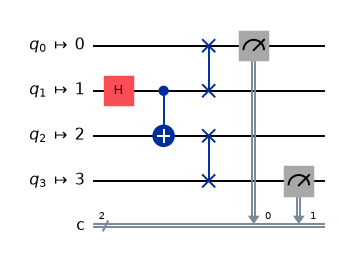

  native gates (what the table counts)


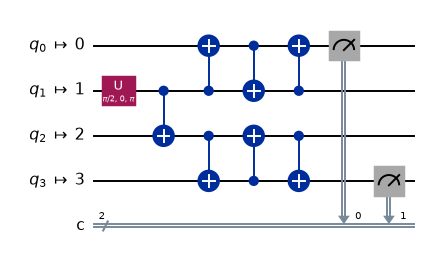

Case 4 - IBM-style today: ports (0, 15)
  routed (SWAPs kept as gates)


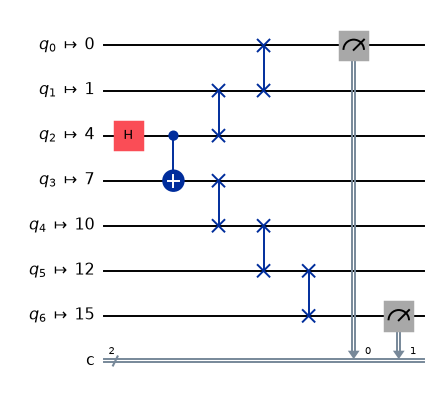

  native gates (what the table counts)


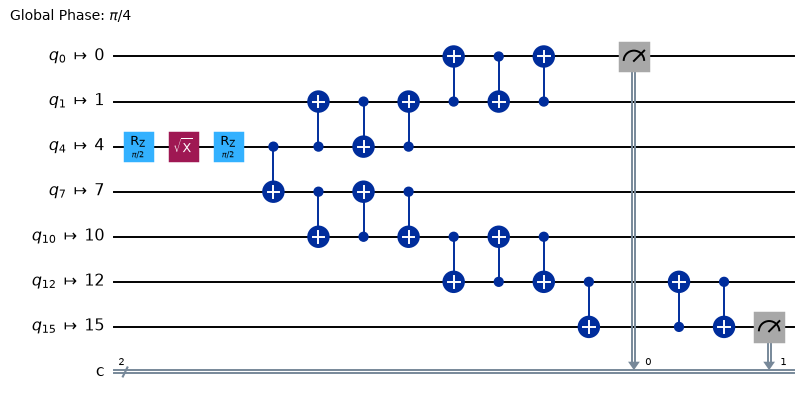

Case 7 - Hyperbolic-inspired: ports (14, 25)
  routed (SWAPs kept as gates)


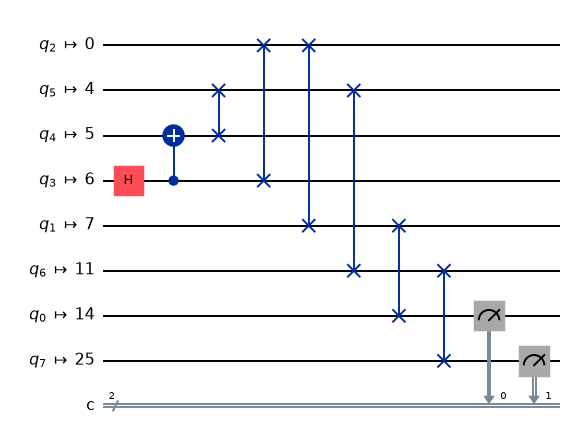

  native gates (what the table counts)


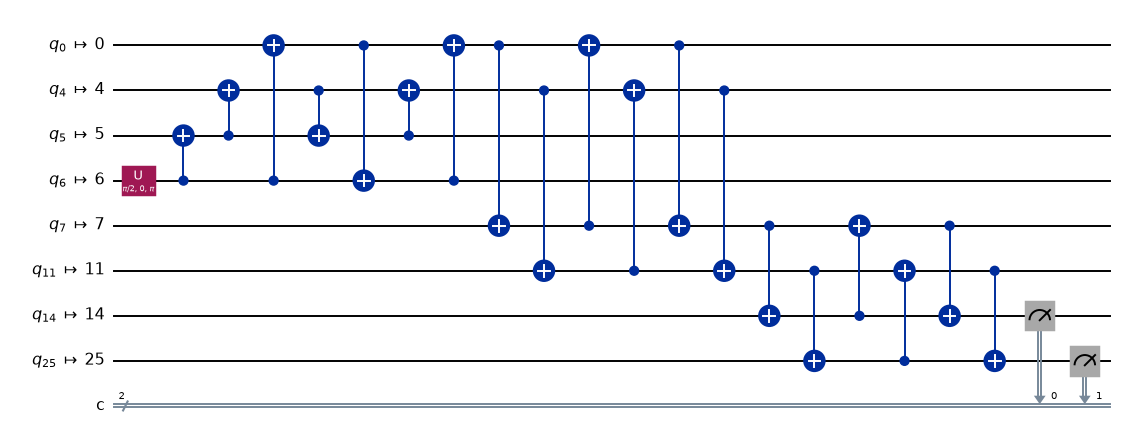

In [6]:
# Draw the compiled ZZ circuits. Idle wires are hidden; wire labels are physical qubit numbers.
for pid, r in LEVEL1.items():
    spec = PROCESSORS[pid]
    print(f"Case {r['case']} - {spec.name}: ports {spec.ports}")
    for label, circ in (("routed (SWAPs kept as gates)", r["runs"]["ZZ"]["routed"]),
                        ("native gates (what the table counts)", r["runs"]["ZZ"]["native"])):
        print("  " + label)
        display(circ.draw("mpl", idle_wires=False, fold=-1, scale=0.7))


## Level 2 — Break it: add noise

**Cases 2, 5, 8:** use each model's official noise assumptions on the Level 1 circuits. Ensure compiled gate names match the noise model, including the IBM backend's native gates.

Report fidelity and a 95% bootstrap confidence interval, resampling each basis independently before combining correlators. Plot fidelity against two-qubit gate count and SWAP overhead. Explain connectivity costs separately from gate-set and noise differences.


In [7]:
def level2_measurement_circuit(model_id, basis):
    if basis not in BASIS_ORDER:
        raise ValueError(f"Unsupported Bell measurement basis: {basis}")
    # Level 1 supplies the routed Bell circuit and readout for this basis.
    return LEVEL1[model_id]["runs"][basis]["routed"]


def verify_level2_circuit(circuit, model_id):
    model = PROCESSORS[model_id]
    allowed = (set(ibm_backend.operation_names) if model_id == "ibm_today" else
               set(SYNTHETIC_BASIS_GATES) | {"measure"})
    measurements = {}
    for instruction in circuit.data:
        name = instruction.operation.name
        assert name in allowed, name
        assert name not in {"reset", "delay"}, name
        if len(instruction.qubits) == 2:
            edge = tuple(circuit.find_bit(qubit).index for qubit in instruction.qubits)
            assert edge in model.edges, edge
        if name == "measure":
            measurements[circuit.find_bit(instruction.clbits[0]).index] = (
                circuit.find_bit(instruction.qubits[0]).index
            )
    assert measurements == {0: model.ports[0], 1: model.ports[1]}, measurements
    return measurements

2016-inspired XX native circuit from ideal Case 1


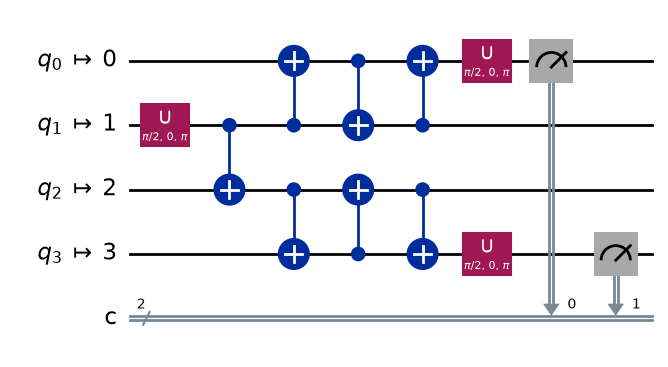

2016-inspired YY native circuit from ideal Case 1


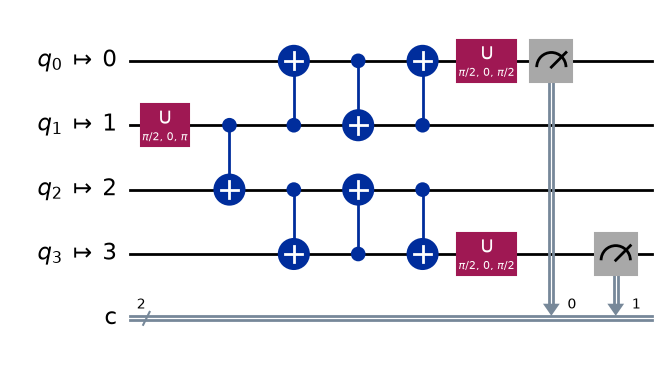

2016-inspired ZZ native circuit from ideal Case 1


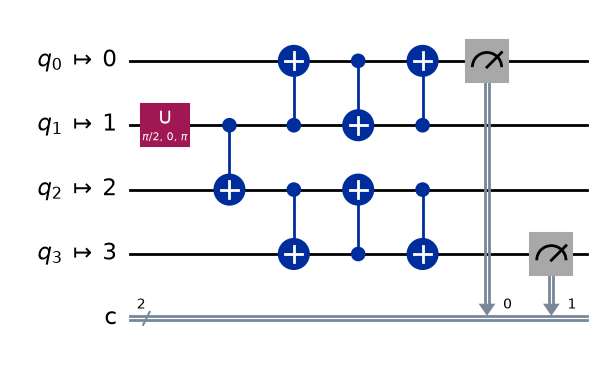

IBM-style today XX native circuit from ideal Case 4


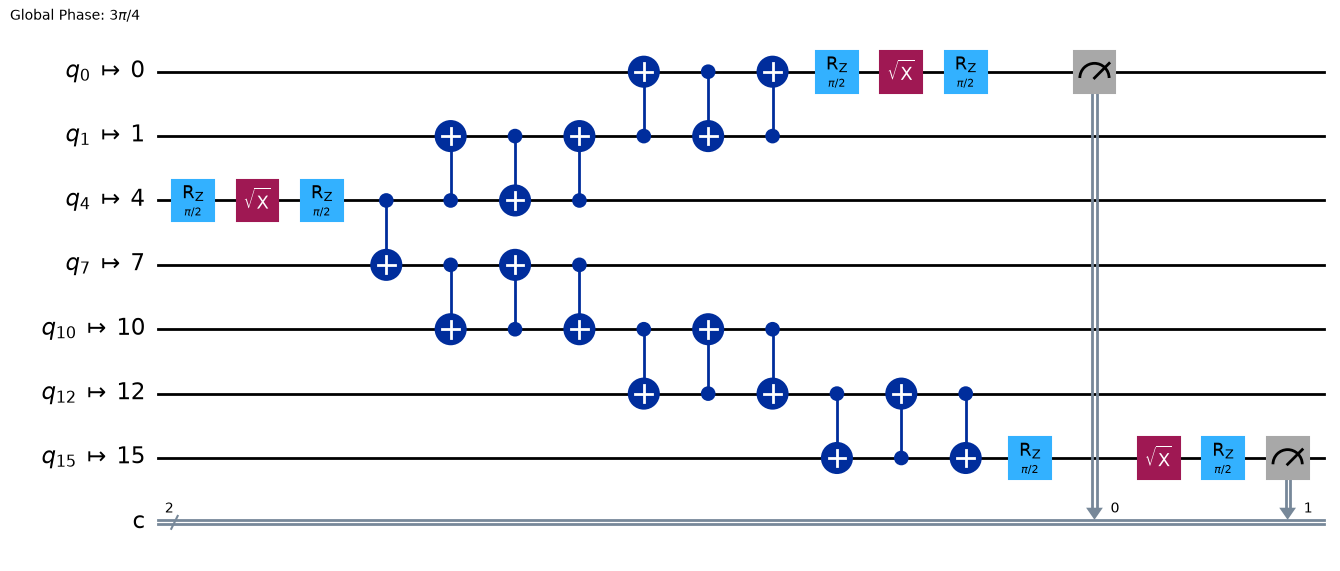

IBM-style today YY native circuit from ideal Case 4


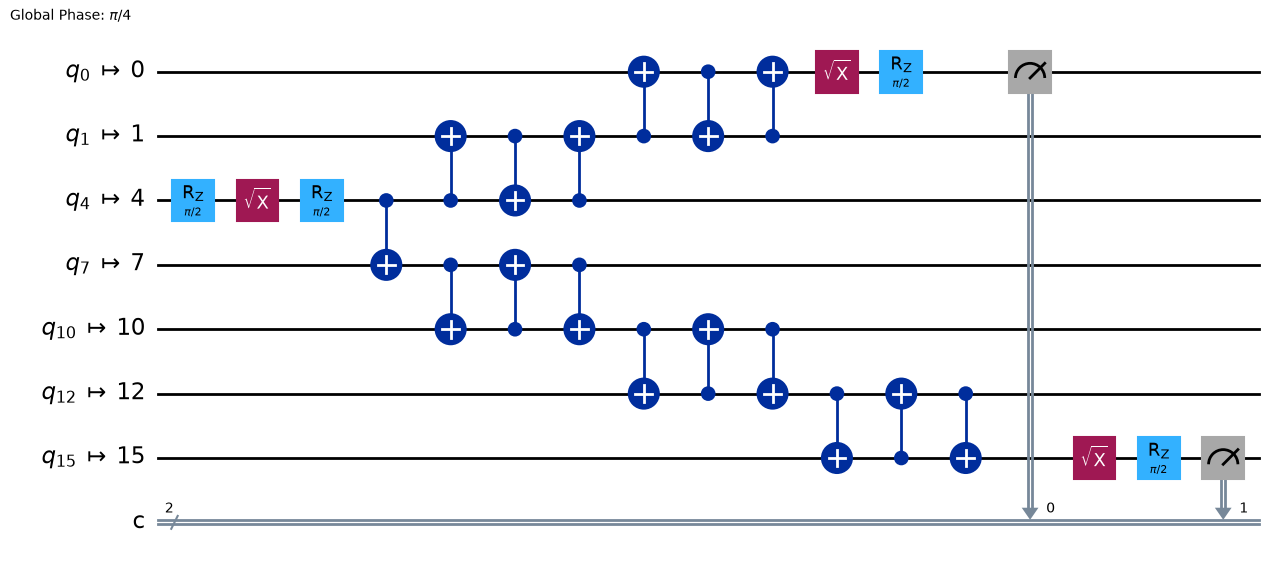

IBM-style today ZZ native circuit from ideal Case 4


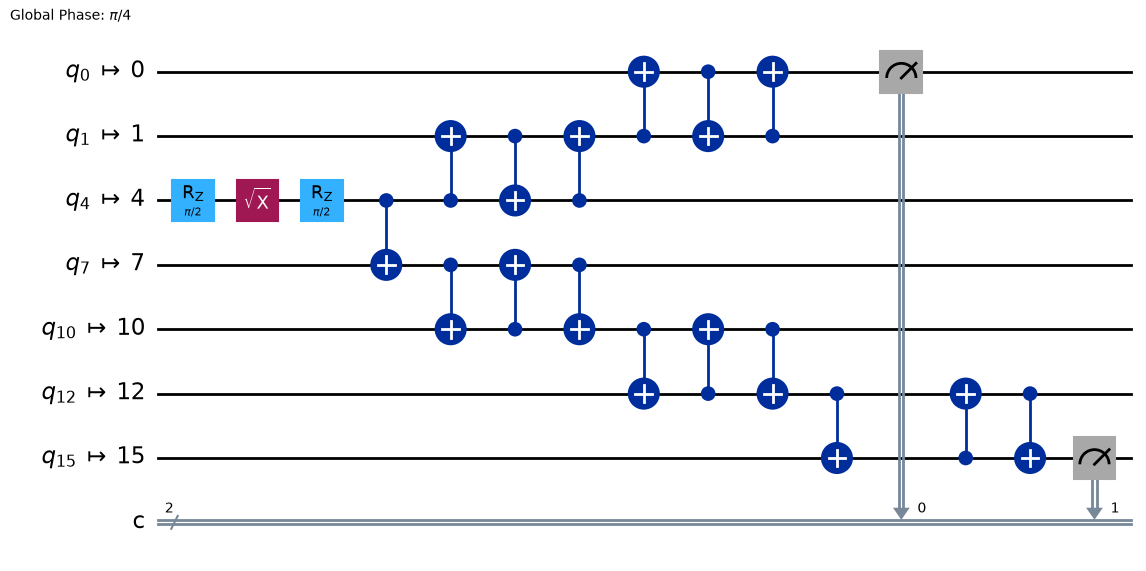

Hyperbolic-inspired XX native circuit from ideal Case 7


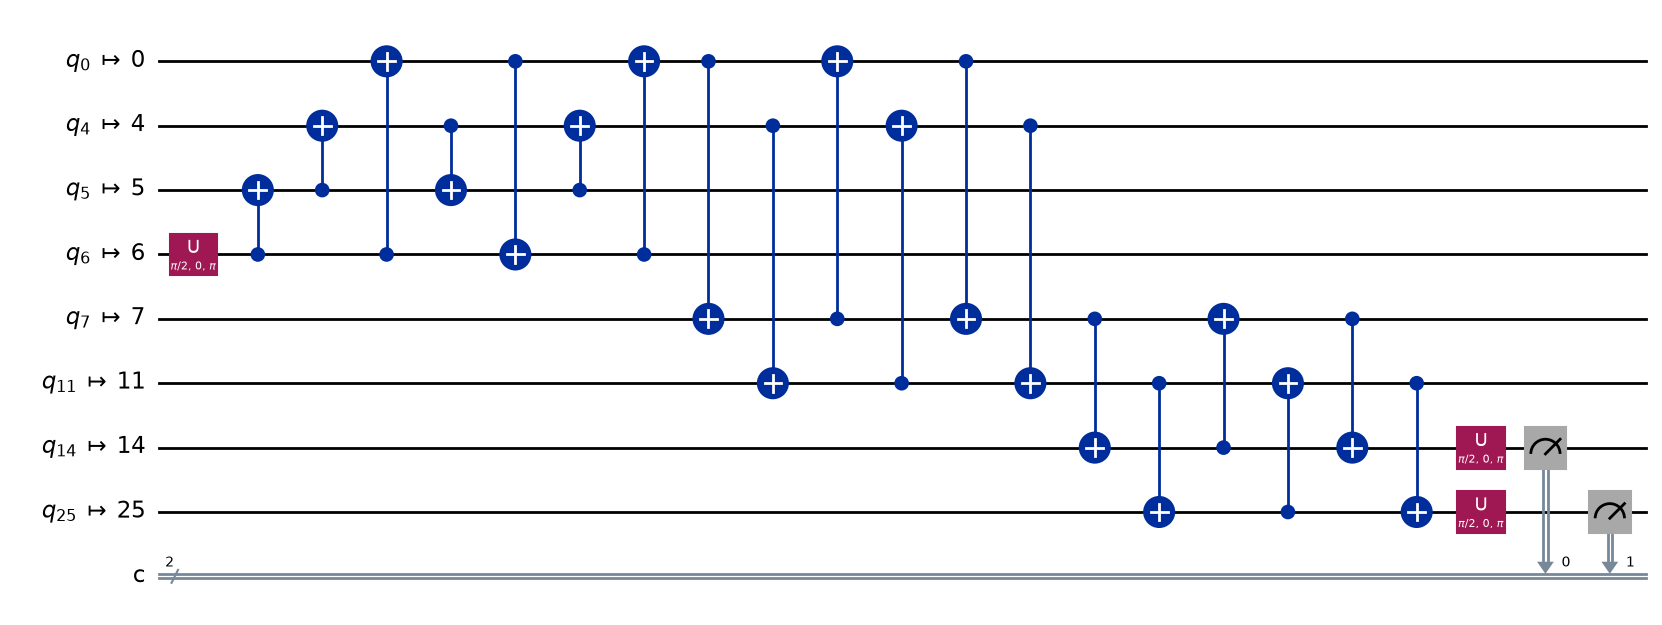

Hyperbolic-inspired YY native circuit from ideal Case 7


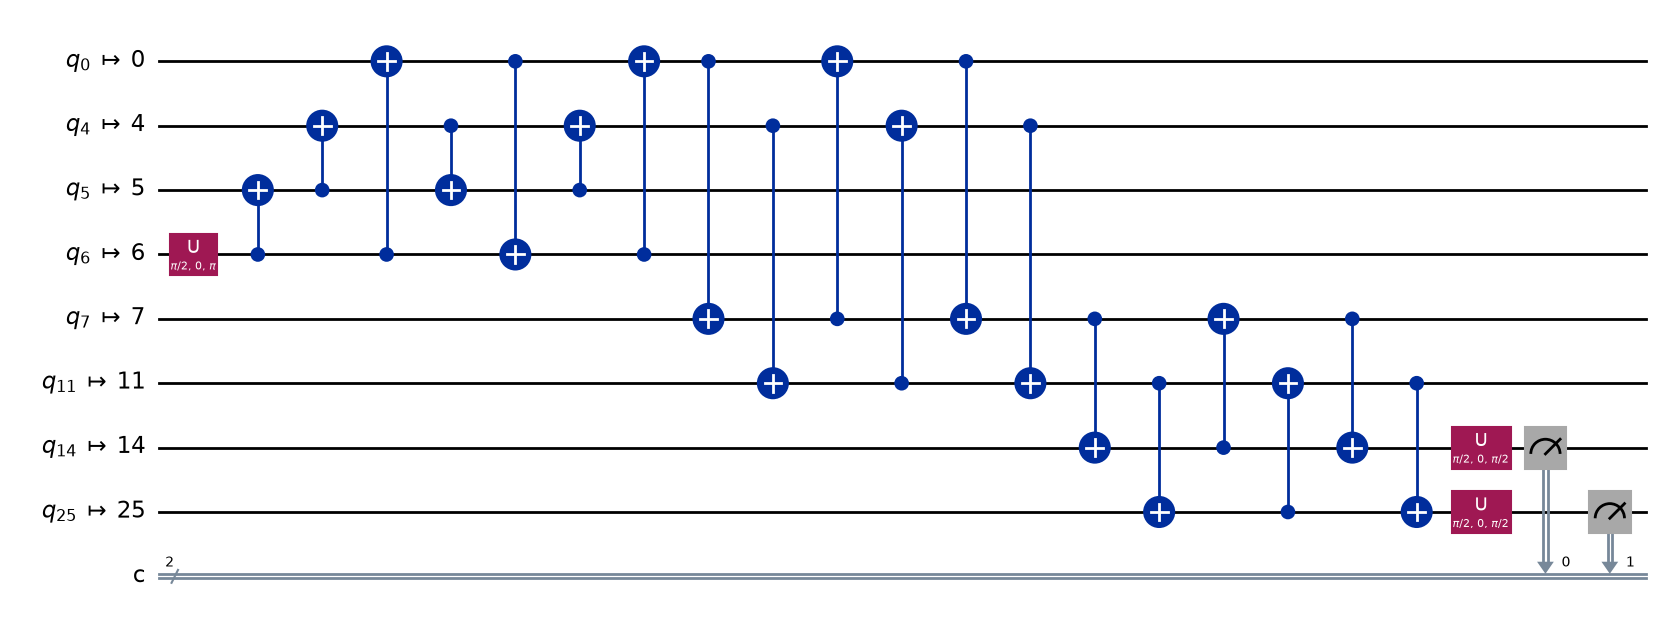

Hyperbolic-inspired ZZ native circuit from ideal Case 7


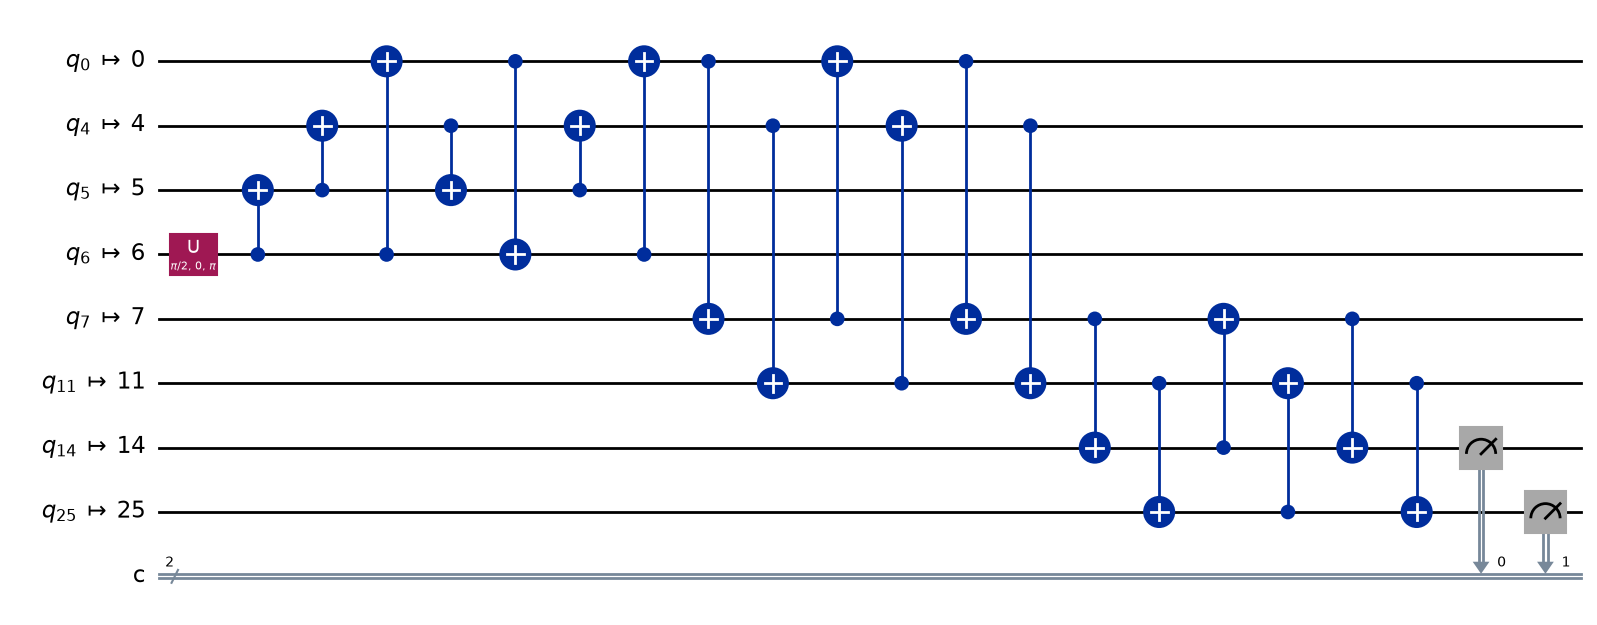

In [8]:
level2_routed_circuits, level2_native_circuits = {}, {}
for _, model_id, _ in LEVEL2_CASES:
    model = PROCESSORS[model_id]
    ideal = LEVEL1[model_id]
    # Levels 1 and 2 share the same routed and native circuit objects.
    routed = {basis: level2_measurement_circuit(model_id, basis) for basis in BASIS_ORDER}
    native = {basis: ideal["runs"][basis]["native"] for basis in BASIS_ORDER}
    for basis, circuit in native.items():
        verify_level2_circuit(circuit, model_id)
        print(model.name, basis, "native circuit from ideal Case", ideal["case"])
        figure = circuit.draw(output="mpl", fold=100, idle_wires=False)
        display(figure)
        plt.close(figure)
    level2_routed_circuits[model_id] = routed
    level2_native_circuits[model_id] = native

In [9]:
level2_results = {}
for case_number, model_id, _ in LEVEL2_CASES:
    model = PROCESSORS[model_id]
    noise = make_noise_model(model_id)
    simulator = AerSimulator(
        method=SIMULATOR_METHODS[model_id], noise_model=noise, **SIMULATOR_OPTIONS[model_id]
    )
    seeds = {basis: aer_seed(SEED + 100 * case_number, basis) for basis in BASIS_ORDER}
    counts, simulation_metadata = {}, {}
    for basis in BASIS_ORDER:
        # Apply the official noise model while sampling the stored native circuit.
        result = simulator.run(
            level2_native_circuits[model_id][basis], shots=SHOTS_PER_BASIS,
            seed_simulator=seeds[basis],
        ).result()
        assert result.success, result.status
        counts[basis] = result.get_counts()
        assert sum(counts[basis].values()) == SHOTS_PER_BASIS
        metadata = result.results[0].metadata
        assert metadata["method"] == SIMULATOR_METHODS[model_id]
        simulation_metadata[basis] = {
            "Method": metadata["method"], "Active simulator qubits": metadata.get("num_qubits"),
        }
    settings = {
        "Case": case_number, "Processor": model_id, "Physical ports": model.ports,
        "Configuration version": CONFIG_VERSION, "Route": LEVEL1[model_id]["path"],
        "Noise": "official model", "Simulator method": SIMULATOR_METHODS[model_id],
        "Simulator options": SIMULATOR_OPTIONS[model_id], "Simulator seeds": seeds,
        "Shots per basis": SHOTS_PER_BASIS,
        "Transpiler seed": transpiler_seed(LEVEL1[model_id]["case"]),
        "Source ideal case": LEVEL1[model_id]["case"],
        "Routed initial layout": LEVEL1[model_id]["path"],
        "Native initial layout": list(range(model.num_qubits)), "Routing method": "none",
        "Routed optimization level": 0, "Native optimization level": TRANSPILE_OPT_LEVEL,
        "Bootstrap resamples": BOOTSTRAP_RESAMPLES,
        "Confidence level": CONFIDENCE_LEVEL, "Bootstrap seed": SEED + 100 * case_number + 10,
    }
    level2_results[case_number] = {
        "settings": settings, "counts": counts, "noise_model": noise,
        "simulation_metadata": simulation_metadata,
        "native_circuits": level2_native_circuits[model_id],
    }
    display(pd.Series(settings, name="Value").to_frame())
    display(noise)
    display(pd.DataFrame([
        {"Basis": basis, "Simulator seed": seeds[basis],
         **{word: counts[basis].get(word, 0) for word in ("00", "01", "10", "11")}}
        for basis in BASIS_ORDER
    ]))

,Value
Case,2
Processor,reference_2016
Physical ports,"(0, 3)"
Configuration version,1.0
Route,"[0, 1, 2, 3]"
Noise,official model
Simulator method,matrix_product_state
Simulator options,{'max_parallel_threads': 1}
Simulator seeds,"{'XX': 1581871202396335, 'YY': 165124889428548..."
Shots per basis,8192


<NoiseModel on ['cx', 'u', 'measure']>

,Basis,Simulator seed,00,01,10,11
0,XX,1581871202396335,3691,414,375,3712
1,YY,1651248894285488,343,3772,3695,382
2,ZZ,2236588451132865,3780,365,374,3673


,Value
Case,5
Processor,ibm_today
Physical ports,"(0, 15)"
Configuration version,1.0
Route,"[0, 1, 4, 7, 10, 12, 15]"
Noise,official model
Simulator method,density_matrix
Simulator options,"{'max_parallel_threads': 1, 'max_parallel_expe..."
Simulator seeds,"{'XX': 2511510835944374, 'YY': 412683445626356..."
Shots per basis,8192


<NoiseModel on ['x', 'cx', 'reset', 'sx', 'measure', 'id']>

,Basis,Simulator seed,00,01,10,11
0,XX,2511510835944374,3683,448,487,3574
1,YY,4126834456263569,434,3591,3688,479
2,ZZ,1277693980872798,3839,512,416,3425


,Value
Case,8
Processor,hyperbolic
Physical ports,"(14, 25)"
Configuration version,1.0
Route,"[14, 7, 0, 6, 5, 4, 11, 25]"
Noise,official model
Simulator method,matrix_product_state
Simulator options,{'max_parallel_threads': 1}
Simulator seeds,"{'XX': 428730849504670, 'YY': 568065746195787,..."
Shots per basis,8192


<NoiseModel on ['cx', 'u', 'measure']>

,Basis,Simulator seed,00,01,10,11
0,XX,428730849504670,3358,763,751,3320
1,YY,568065746195787,811,3307,3337,737
2,ZZ,2844583065748786,3284,756,744,3408


In [10]:
def level2_correlator(counts):
    shots = sum(counts.values())
    if shots <= 0:
        raise ValueError("A correlator needs at least one observed shot.")
    signed_total = 0
    for outcome, count in counts.items():
        # Qiskit prints c1c0. Reverse the string to read the port bits in c0, c1 order.
        bits = outcome.replace(" ", "")[::-1]
        signed_total += count if bits[0] == bits[1] else -count
    return signed_total / shots


def level2_fidelity(correlations):
    # Phi+ has correlations (+1, -1, +1), which fixes the minus sign on YY.
    return (1 + correlations["XX"] - correlations["YY"] + correlations["ZZ"]) / 4


def level2_fidelity_interval(counts_by_basis, resamples, confidence, seed):
    rng = np.random.default_rng(seed)
    resampled_correlations = {}
    for basis in BASIS_ORDER:
        shots = sum(counts_by_basis[basis].values())
        probability_agree = (1 + level2_correlator(counts_by_basis[basis])) / 2
        # Group the four outcomes by whether the two port bits agree.
        # Resample those group counts with a binomial draw.
        agreeing = rng.binomial(shots, probability_agree, size=resamples)
        resampled_correlations[basis] = 2 * agreeing / shots - 1
    # Combine the independently resampled XX, YY, and ZZ correlations into fidelities.
    fidelities = level2_fidelity(resampled_correlations)
    tail = (1 - confidence) / 2
    return tuple(float(bound) for bound in np.quantile(fidelities, [tail, 1 - tail]))


def level2_circuit_costs(native, routed):
    counted = RemoveBarriers()(native)
    touched = {counted.find_bit(qubit).index
               for instruction in counted.data for qubit in instruction.qubits}
    return {
        "Depth": counted.depth(),
        "Two-qubit gates": sum(len(instruction.qubits) == 2 for instruction in counted.data),
        # Count transport SWAPs in the routed circuit.
        # Native compilation expands each of them into three CX gates.
        "SWAPs": int(routed.count_ops().get("swap", 0)),
        "Physical qubits": len(touched),
    }


for case_number, model_id, _ in LEVEL2_CASES:
    result = level2_results[case_number]
    correlations = {basis: level2_correlator(counts) for basis, counts in result["counts"].items()}
    fidelity = level2_fidelity(correlations)
    interval = level2_fidelity_interval(
        result["counts"], BOOTSTRAP_RESAMPLES, CONFIDENCE_LEVEL, result["settings"]["Bootstrap seed"]
    )
    costs = {basis: level2_circuit_costs(
        result["native_circuits"][basis], level2_routed_circuits[model_id][basis]
    ) for basis in BASIS_ORDER}
    accounting = pd.DataFrame([
        {"Case": case_number, "Basis": basis, "Attempted": SHOTS_PER_BASIS,
         "Accepted": sum(result["counts"][basis].values()), "Discarded": 0, "Yield": 1.0}
        for basis in BASIS_ORDER
    ])
    # Level 2 accepts every attempted shot, so its reported yield is 1.
    summary = {
        "Case": case_number, "Processor model": PROCESSORS[model_id].name, "Level": 2,
        "F": fidelity, "95% CI": interval, **costs["ZZ"], "Yield": 1.0, "Discarded shots": 0,
    }
    result.update({"correlations": correlations, "costs": costs,
                   "shot_accounting": accounting, "summary": summary})
    display(pd.DataFrame([
        {"Case": case_number, "Basis": basis, "Correlation": correlations[basis], **costs[basis]}
        for basis in BASIS_ORDER
    ]))
    display(accounting)

level2_results_table = pd.DataFrame([result["summary"] for result in level2_results.values()])
display(level2_results_table)
display(pd.DataFrame([
    {"Case": case, "Fidelity loss from ideal target": 1 - result["summary"]["F"]}
    for case, result in level2_results.items()
]))

,Case,Basis,Correlation,Depth,Two-qubit gates,SWAPs,Physical qubits
0,2,XX,0.807373,7,7,2,4
1,2,YY,-0.822998,7,7,2,4
2,2,ZZ,0.819580,6,7,2,4


,Case,Basis,Attempted,Accepted,Discarded,Yield
0,2,XX,8192,8192,0,1.0
1,2,YY,8192,8192,0,1.0
2,2,ZZ,8192,8192,0,1.0


,Case,Basis,Correlation,Depth,Two-qubit gates,SWAPs,Physical qubits
0,5,XX,0.771729,17,16,5,7
1,5,YY,-0.777100,16,16,5,7
2,5,ZZ,0.773438,14,16,5,7


,Case,Basis,Attempted,Accepted,Discarded,Yield
0,5,XX,8192,8192,0,1.0
1,5,YY,8192,8192,0,1.0
2,5,ZZ,8192,8192,0,1.0


,Case,Basis,Correlation,Depth,Two-qubit gates,SWAPs,Physical qubits
0,8,XX,0.630371,13,19,6,8
1,8,YY,-0.622070,13,19,6,8
2,8,ZZ,0.633789,12,19,6,8


,Case,Basis,Attempted,Accepted,Discarded,Yield
0,8,XX,8192,8192,0,1.0
1,8,YY,8192,8192,0,1.0
2,8,ZZ,8192,8192,0,1.0


,Case,Processor model,Level,F,95% CI,Depth,Two-qubit gates,SWAPs,Physical qubits,Yield,Discarded shots
0,2,2016-inspired,2,0.862488,"(0.856812, 0.867859)",6,7,2,4,1.0,0
1,5,IBM-style today,2,0.830566,"(0.825134, 0.836549)",14,16,5,7,1.0,0
2,8,Hyperbolic-inspired,2,0.721558,"(0.713988, 0.728943)",12,19,6,8,1.0,0


,Case,Fidelity loss from ideal target
0,2,0.137512
1,5,0.169434
2,8,0.278442


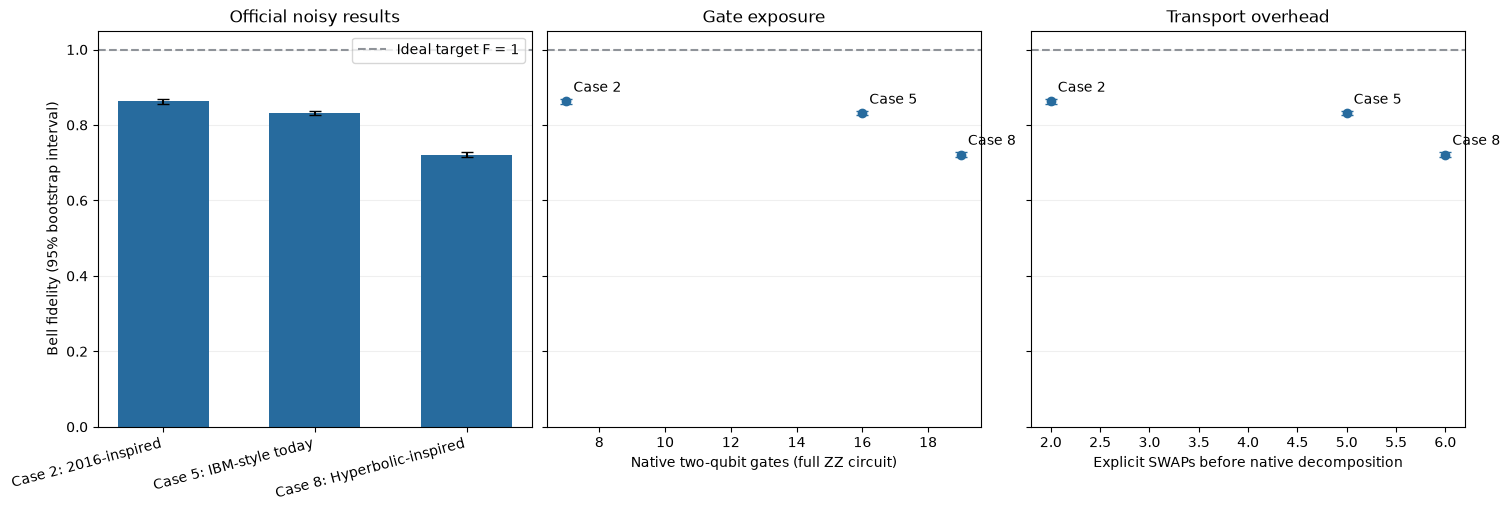

In [11]:
figure, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True, layout="constrained")
for index, result in enumerate(level2_results.values()):
    summary = result["summary"]
    fidelity = summary["F"]
    lower, upper = summary["95% CI"]
    error = [[fidelity - lower], [upper - fidelity]]
    axes[0].bar(index, fidelity, width=0.6, color="#276b9e")
    axes[0].errorbar(index, fidelity, yerr=error, fmt="none", color="black", capsize=4)
    for axis, metric in zip(axes[1:], ("Two-qubit gates", "SWAPs")):
        axis.errorbar(summary[metric], fidelity, yerr=error, fmt="o", color="#276b9e", capsize=4)
        axis.annotate(f"Case {summary['Case']}", (summary[metric], fidelity),
                      xytext=(5, 7), textcoords="offset points")
# Phi+ has unit fidelity, so draw F = 1 as the reference line.
for axis in axes:
    axis.axhline(1, color="#8f9399", linestyle="--", label="Ideal target F = 1")
    axis.set_ylim(0, 1.05)
    axis.grid(axis="y", alpha=0.2)
    axis.set_axisbelow(True)
axes[0].set_xticks(range(len(level2_results)),
                   [f"Case {row['Case']}: {row['Processor model']}"
                    for row in level2_results_table.to_dict("records")], rotation=15, ha="right")
axes[0].set_ylabel("Bell fidelity (95% bootstrap interval)")
axes[0].set_title("Official noisy results")
axes[0].legend()
axes[1].set_xlabel("Native two-qubit gates (full ZZ circuit)")
axes[1].set_title("Gate exposure")
axes[2].set_xlabel("Explicit SWAPs before native decomposition")
axes[2].set_title("Transport overhead")
# Cases 2 and 8 share u/cx noise parameters; each extra SWAP adds three noisy CX gates.
# IBM's points include its calibrated gate errors and qubit-specific readout errors.
display(figure)
plt.close(figure)

## Level 3 — Protect it: detect errors

**Cases 3, 6, 9:** implement one justified protection or error-detection check on each model. Explain which faults it detects, which it misses, ancilla placement and routing, and the acceptance rule. Use the same protection procedure and acceptance rule before the basis rotations in all three bases. Do not postselect using final port outcomes.

Compare conditional fidelity and its 95% interval with Level 2. Report acceptance fraction, accepted and discarded shots (per basis), extra gates, depth and physical qubits including ancillas. Handle zero accepted shots explicitly; do not report a fabricated fidelity. Discuss whether any improvement justifies its overhead and lost shots. An accurately analyzed lack of improvement is a valid result.


In [12]:
LEVEL3_CASES = tuple(case for case in CASES if case[2] == 3)

def level3_preparation(model_id):
    source = level2_routed_circuits[model_id]["ZZ"]
    preparation = QuantumCircuit(PROCESSORS[model_id].num_qubits,
                                 name=f"{model_id}_shared_preparation")
    # Copy the Bell preparation and transport gates from the Level 2 ZZ circuit.
    for instruction in source.data:
        if instruction.operation.name != "measure":
            preparation.append(instruction.operation,
                               [source.find_bit(qubit).index for qubit in instruction.qubits])
    return preparation


def level3_parity_check(model_id, preparation):
    model = PROCESSORS[model_id]
    port_a, port_b = model.ports
    graph = processor_graphs[model_id]
    meter_graph = graph.copy()
    # Route the meter through intermediate qubits while both Bell halves stay at their ports.
    meter_graph.remove_nodes_from(model.ports)
    used = {preparation.find_bit(qubit).index for instruction in preparation.data
            if instruction.operation.name != "barrier" for qubit in instruction.qubits}
    # An unused qubit by the preparation gives the meter's initial |0> state.
    fresh = sorted(set(graph) - used)
    candidates = []
    for ancilla in fresh:
        for contact_a in sorted(set(graph.neighbors(port_a)) - set(model.ports)):
            for contact_b in sorted(set(graph.neighbors(port_b)) - set(model.ports)):
                try:
                    first = nx.shortest_path(meter_graph, ancilla, contact_a)
                    second = nx.shortest_path(meter_graph, contact_a, contact_b)
                except nx.NetworkXNoPath:
                    continue
                route = first + second[1:]
                candidates.append((len(route) - 1, ancilla, tuple(route), len(first) - 1))
    if not candidates:
        raise ValueError("The graph needs a fresh-meter route connecting neighbors of both ports.")
    # Minimize SWAPs for the chosen first-port-then-second-port check order.
    swaps, ancilla, route, first_contact = min(candidates)
    check = QuantumCircuit(model.num_qubits, 1, name=f"{model_id}_ZZ_check")
    for step, location in enumerate(route):
        if step:
            # SWAP exchanges the meter state with the next qubit, carrying its accumulated parity.
            check.swap(route[step - 1], location)
        if step == first_contact:
            check.cx(port_a, location)
    # The two CNOTs write a XOR b into the meter for each port component |a>|b>.
    # Both |00> and |11> write zero, preserving their Bell-state coherence in the ideal check.
    check.cx(port_b, route[-1])
    check.measure(route[-1], 0)
    return check, {
        "ancilla_source": ancilla, "meter_route": list(route), "checker_swaps": swaps,
        "first_contact_index": first_contact, "interaction_order": list(model.ports),
        "selection_policy": "minimum SWAPs, first port checked before second port",
    }

In [13]:
def verify_level3_circuit(circuit, model_id, meter):
    model = PROCESSORS[model_id]
    allowed = (set(ibm_backend.operation_names) | {"barrier"} if model_id == "ibm_today" else
               set(SYNTHETIC_BASIS_GATES) | {"measure", "barrier"})
    measurements = {}
    for instruction in circuit.data:
        name = instruction.operation.name
        assert name in allowed, name
        assert name not in {"reset", "delay"}, name
        if len(instruction.qubits) == 2 and name != "barrier":
            edge = tuple(circuit.find_bit(qubit).index for qubit in instruction.qubits)
            assert edge in model.edges, edge
        if name == "measure":
            measurements[circuit.find_bit(instruction.clbits[0]).index] = (
                circuit.find_bit(instruction.qubits[0]).index
            )
    assert measurements == {0: model.ports[0], 1: model.ports[1], 2: meter}, measurements
    return measurements


def level3_compile(preparation, parity_check, model_id, meter):
    model = PROCESSORS[model_id]
    target = ({"backend": ibm_backend} if model_id == "ibm_today" else
              {"coupling_map": model.coupling_map(),
               "basis_gates": list(SYNTHETIC_BASIS_GATES)})
    routed, native = {}, {}
    for basis in BASIS_ORDER:
        circuit = QuantumCircuit(model.num_qubits, 3, name=f"level3_{model_id}_{basis}")
        circuit.compose(preparation, inplace=True)
        # c2 stores the meter outcome. c0 and c1 store the physical port readings.
        circuit.compose(parity_check, clbits=[2], inplace=True)
        # The barrier places the same parity measurement before every basis rotation.
        circuit.barrier()
        for port in model.ports:
            if basis == "YY":
                circuit.sdg(port)
            if basis in ("XX", "YY"):
                circuit.h(port)
        circuit.measure(list(model.ports), [0, 1])
        routed[basis] = circuit
        native[basis] = transpile(
            circuit, **target, initial_layout=list(range(model.num_qubits)),
            routing_method="none", optimization_level=OPTIMIZATION_LEVEL, seed_transpiler=SEED,
        )
        verify_level3_circuit(native[basis], model_id, meter)
    return routed, native


level3_circuits = {}
for case_number, model_id, _ in LEVEL3_CASES:
    preparation = level3_preparation(model_id)
    check, routing = level3_parity_check(model_id, preparation)
    routed, native = level3_compile(preparation, check, model_id, routing["meter_route"][-1])
    level3_circuits[model_id] = {
        "preparation": preparation, "parity_check": check, "routing": routing,
        "routed": routed, "native": native,
    }
    print(f"Case {case_number} meter routing:", routing)

Case 3 meter routing: {'ancilla_source': 4, 'meter_route': [4, 1, 2], 'checker_swaps': 2, 'first_contact_index': 1, 'interaction_order': [0, 3], 'selection_policy': 'minimum SWAPs, first port checked before second port'}
Case 6 meter routing: {'ancilla_source': 2, 'meter_route': [2, 1, 4, 7, 10, 12], 'checker_swaps': 5, 'first_contact_index': 1, 'interaction_order': [0, 15], 'selection_policy': 'minimum SWAPs, first port checked before second port'}
Case 9 meter routing: {'ancilla_source': 34, 'meter_route': [34, 7, 0, 6, 5, 4, 11], 'checker_swaps': 6, 'first_contact_index': 1, 'interaction_order': [14, 25], 'selection_policy': 'minimum SWAPs, first port checked before second port'}


Case 3, XX, complete native circuit


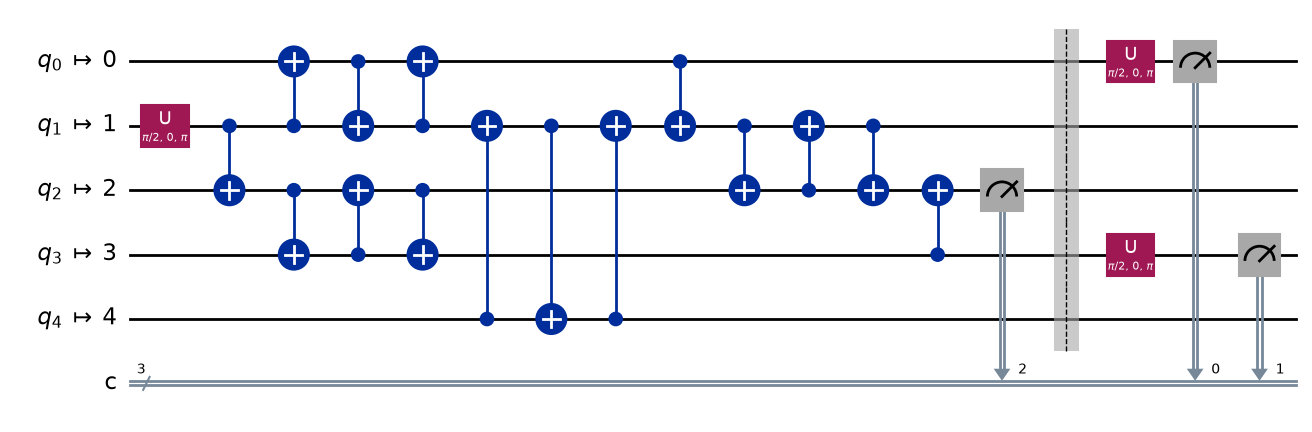

Case 3, YY, complete native circuit


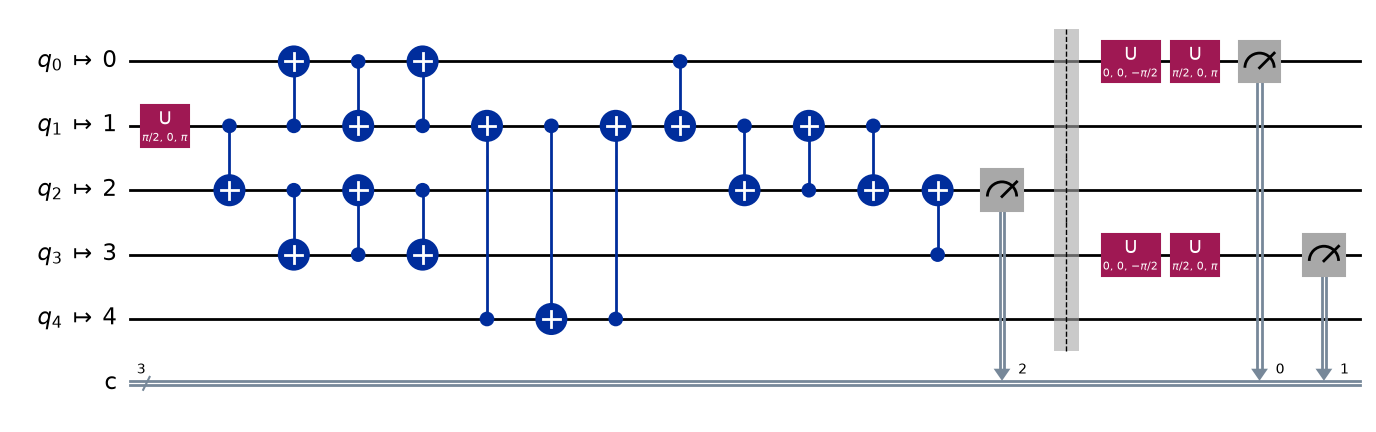

Case 3, ZZ, complete native circuit


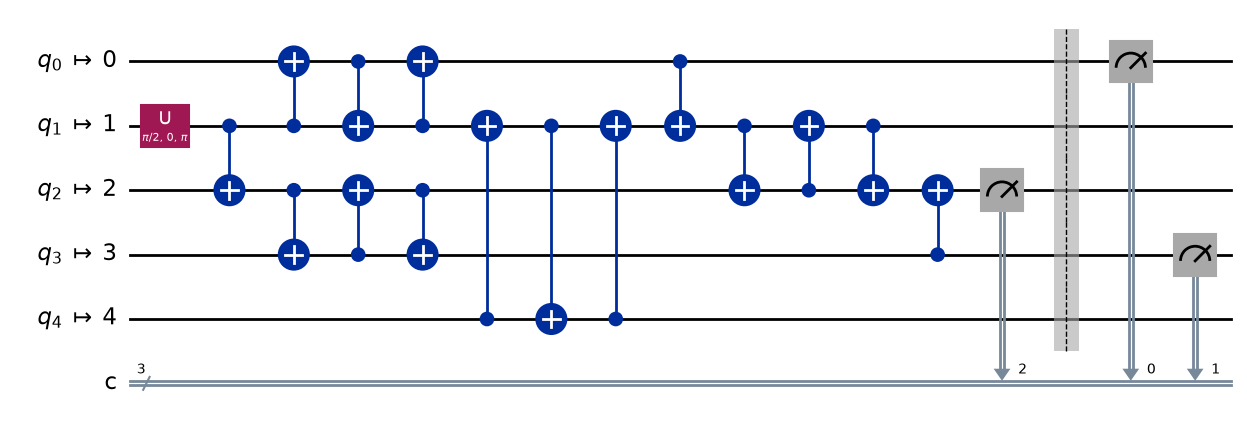

Case 6, XX, complete native circuit


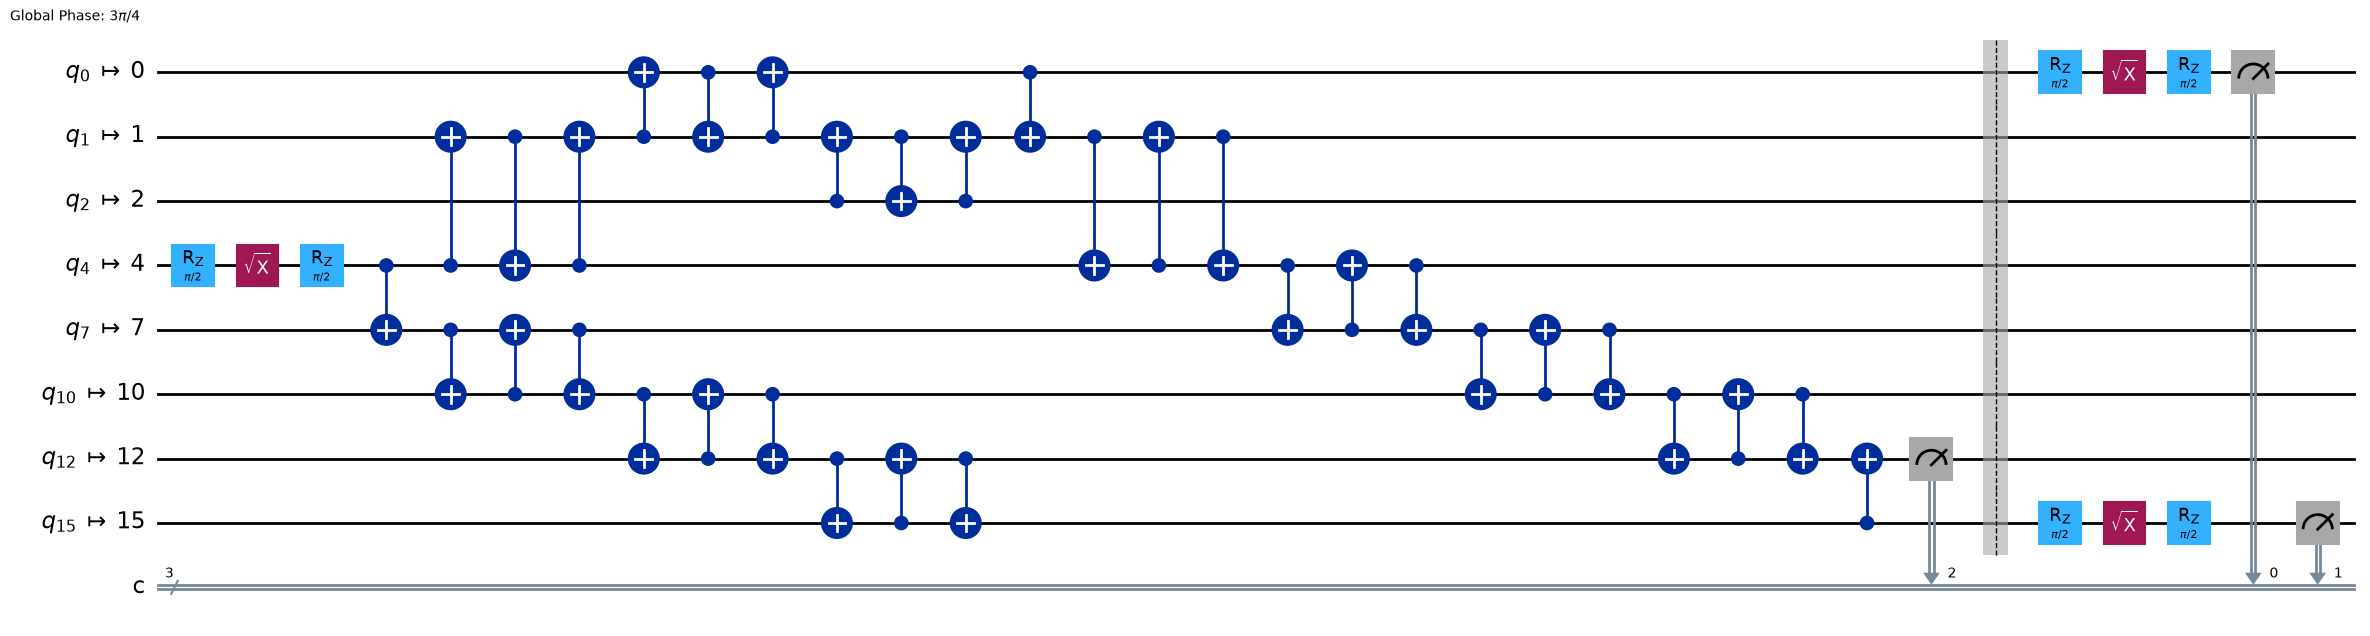

Case 6, YY, complete native circuit


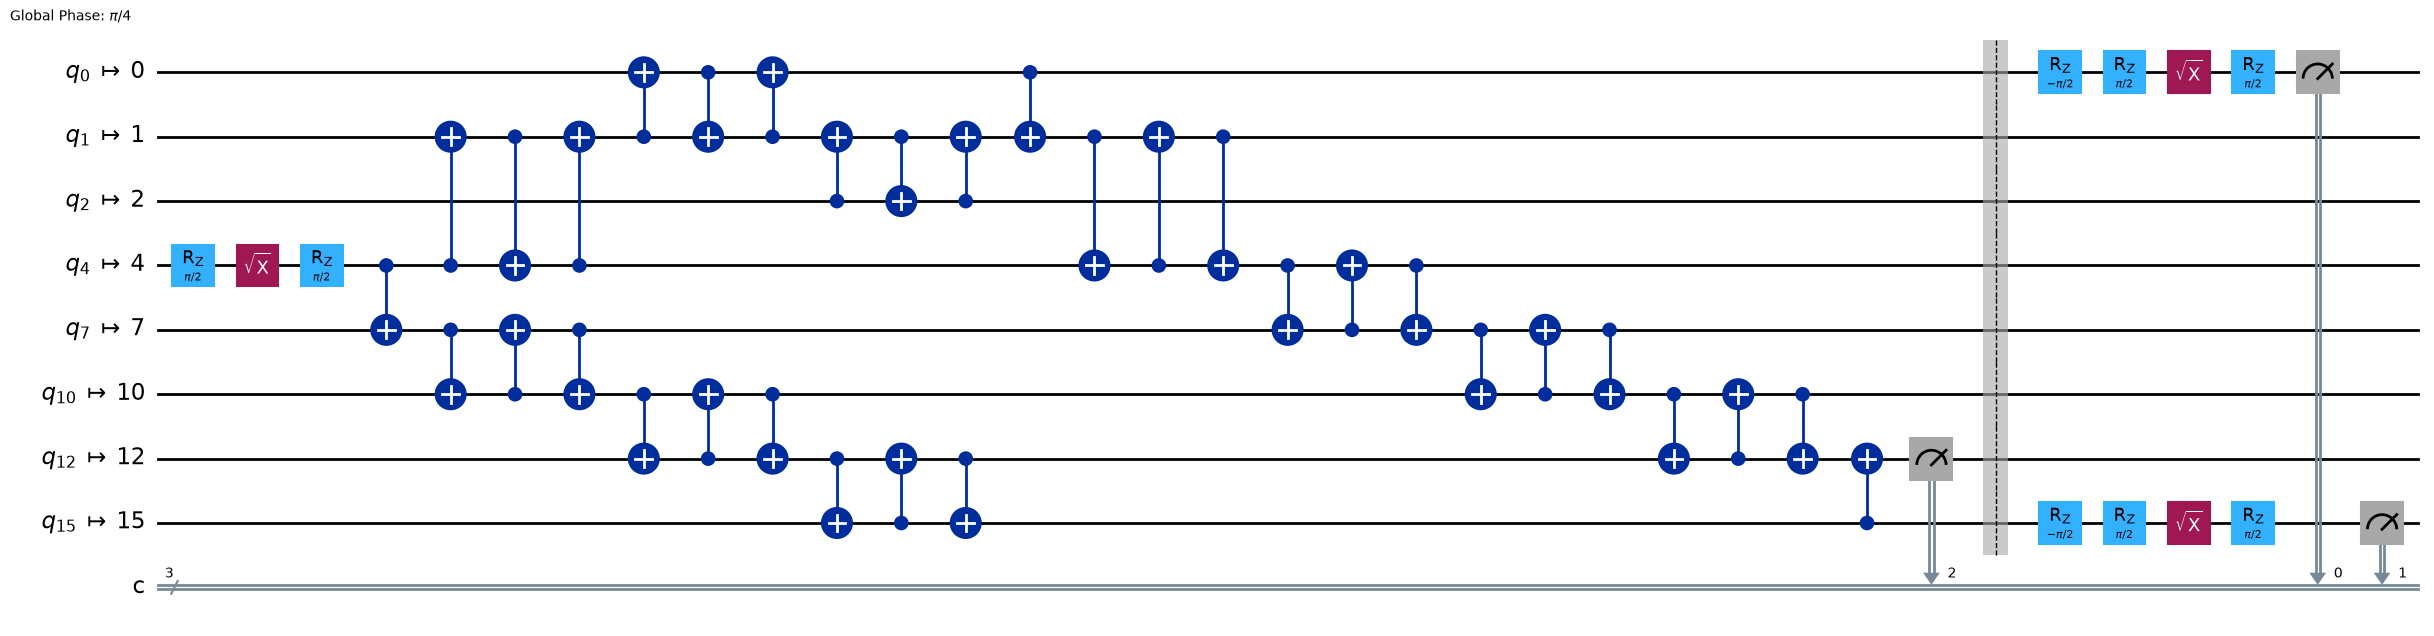

Case 6, ZZ, complete native circuit


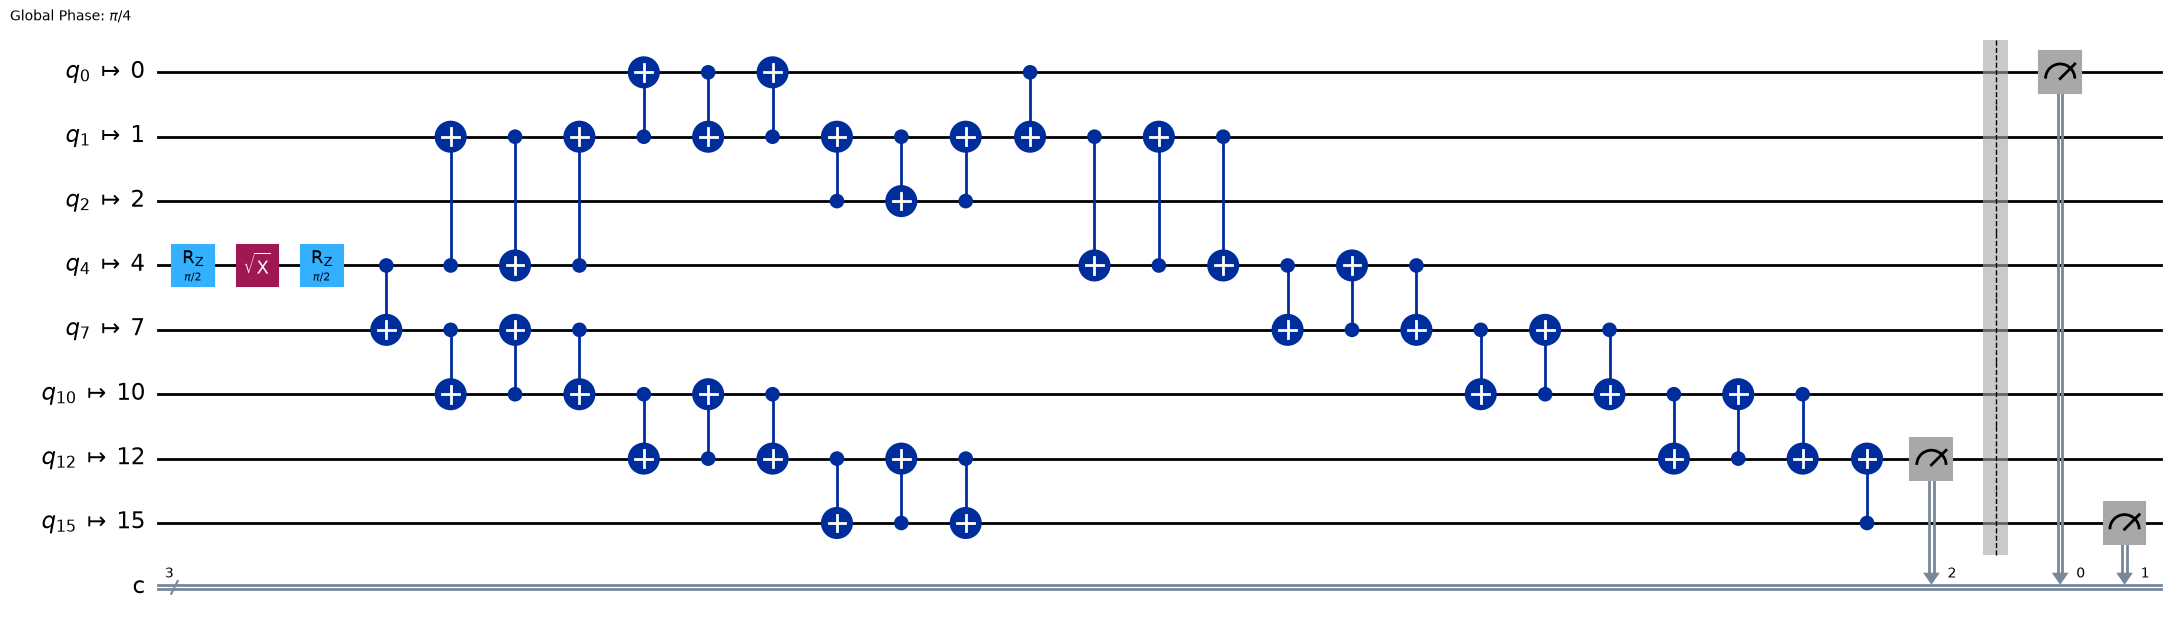

Case 9, XX, complete native circuit


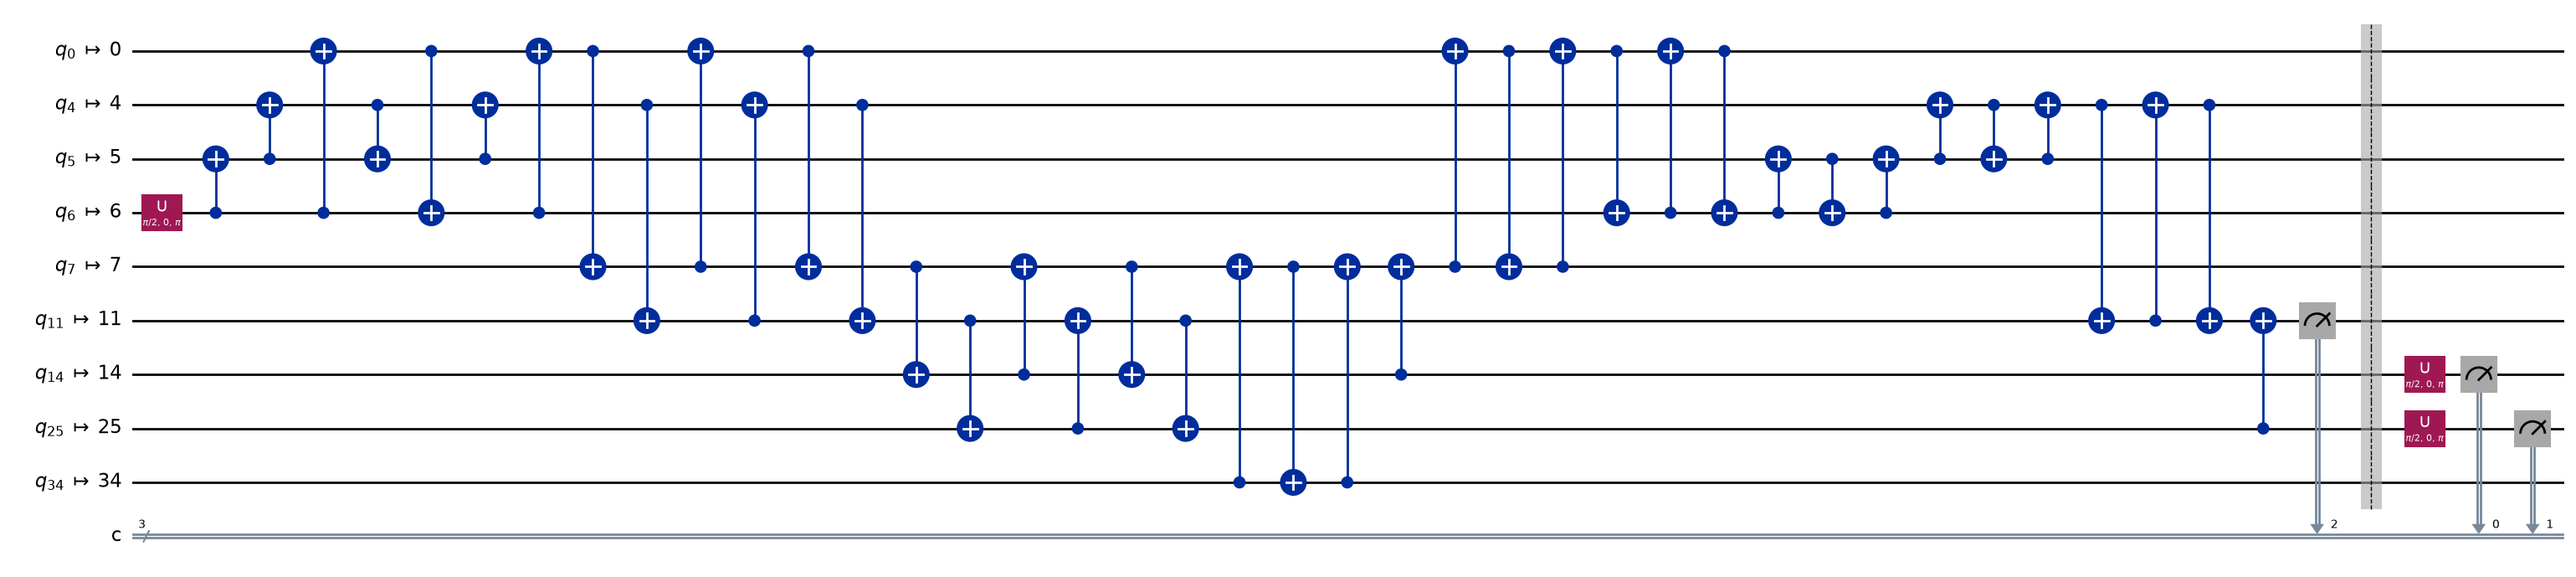

Case 9, YY, complete native circuit


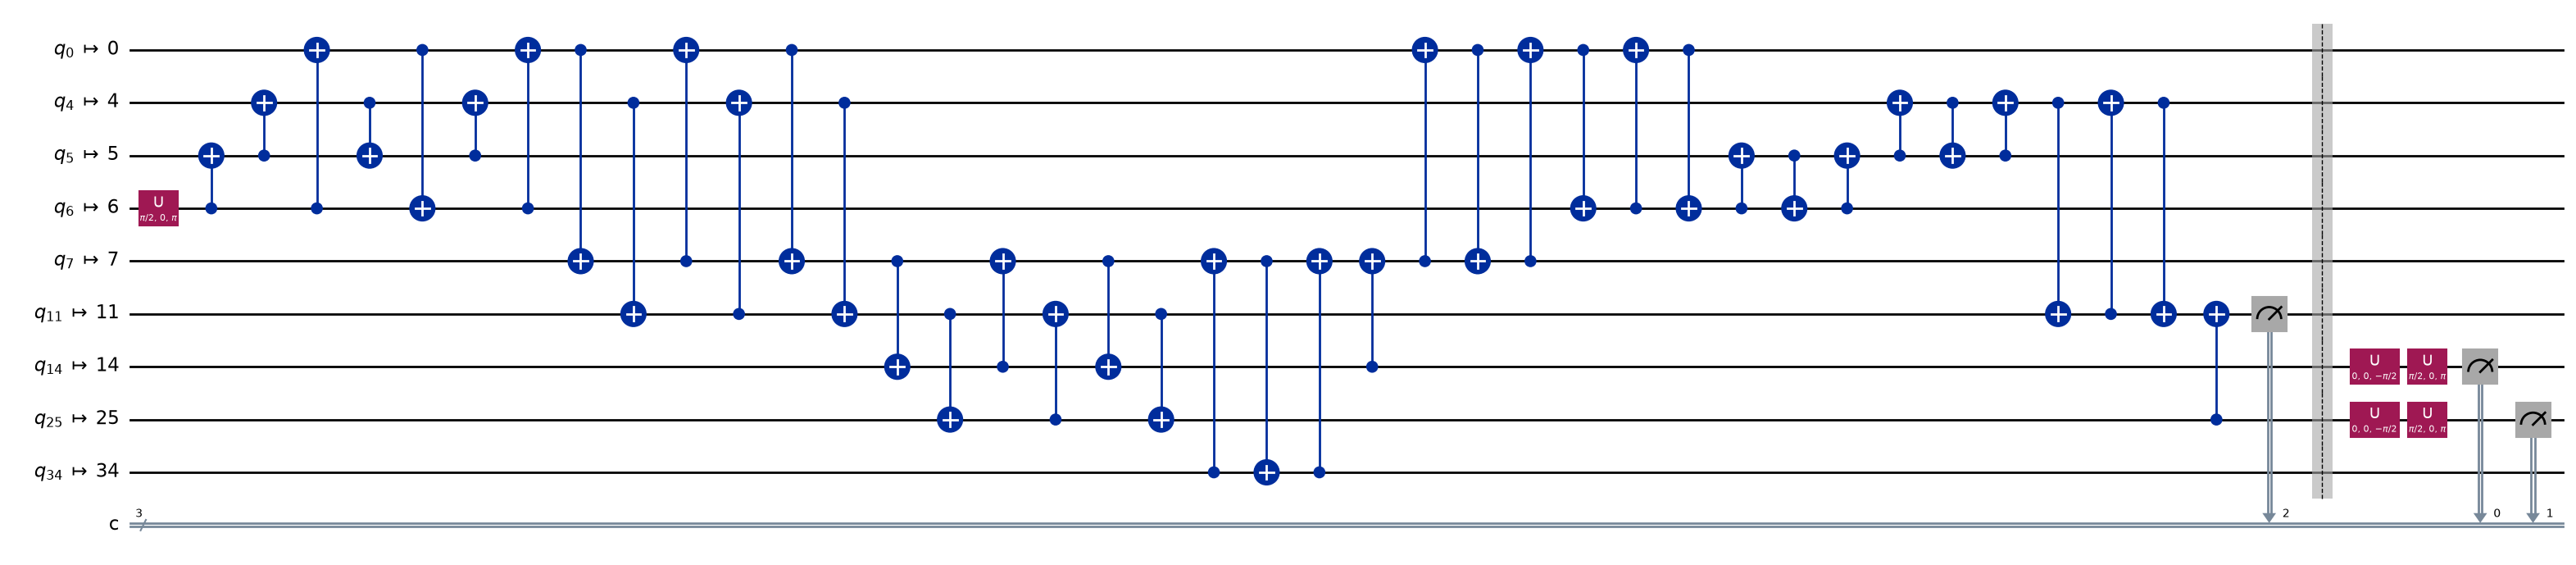

Case 9, ZZ, complete native circuit


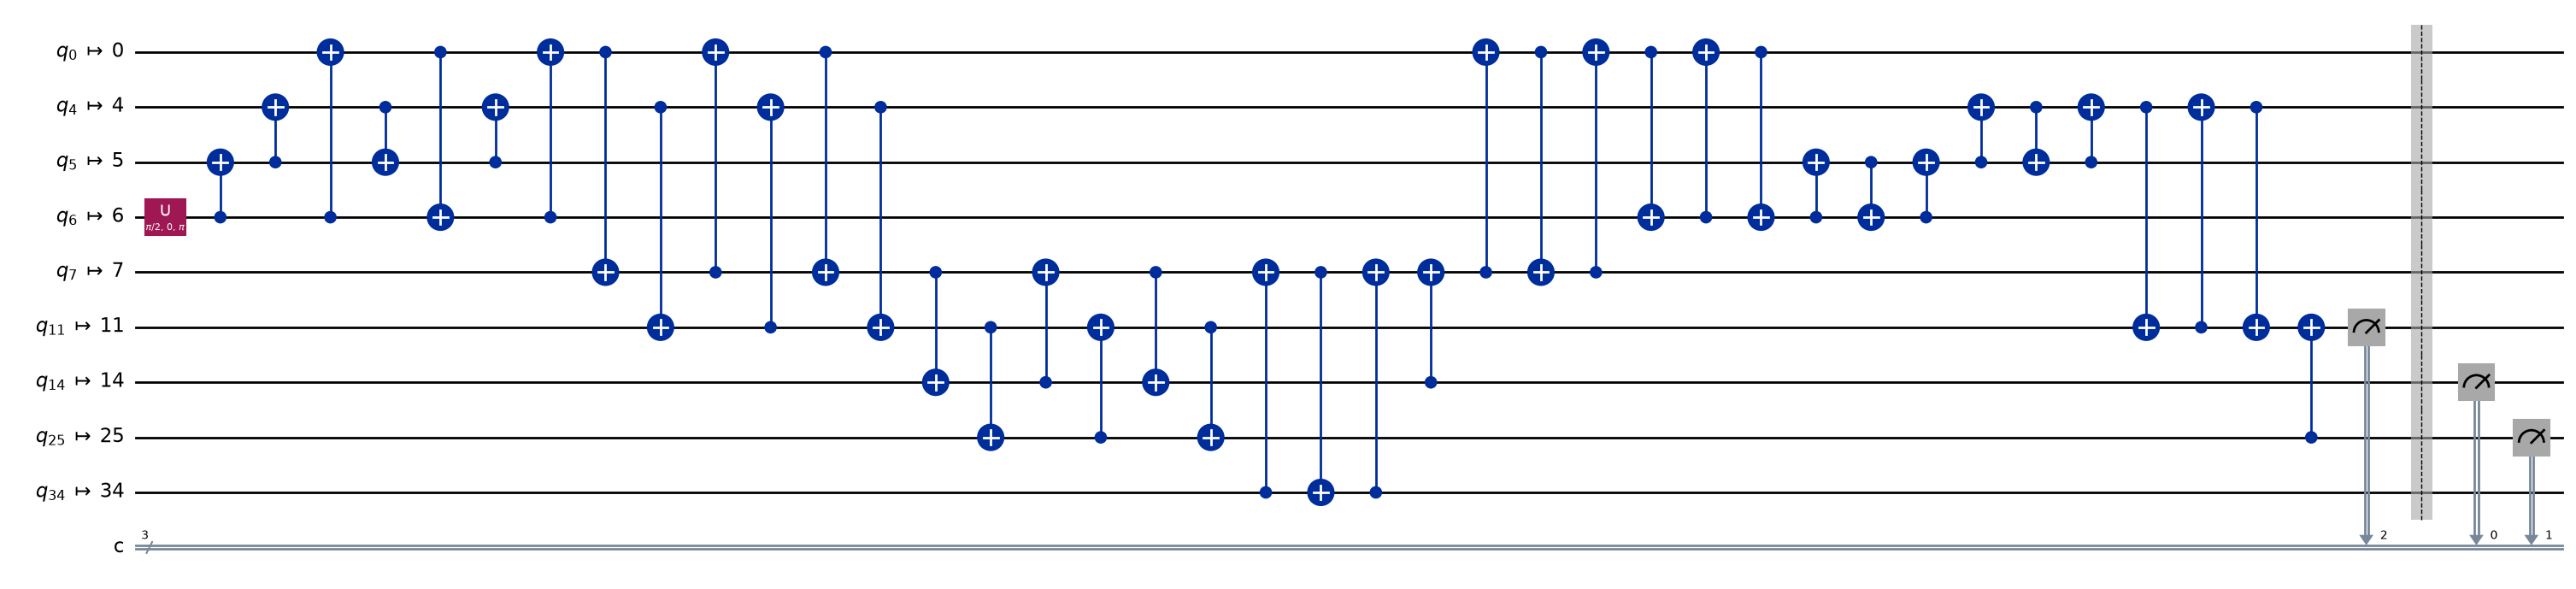

In [14]:
for case_number, model_id, _ in LEVEL3_CASES:
    for basis, circuit in level3_circuits[model_id]["native"].items():
        print(f"Case {case_number}, {basis}, complete native circuit")
        figure = circuit.draw(output="mpl", fold=100, idle_wires=False)
        display(figure)
        plt.close(figure)

In [15]:
def level3_postselect(counts):
    attempted = sum(counts.values())
    if attempted <= 0:
        raise ValueError("Postselection requires at least one attempted shot.")
    # Keep the measured meter-zero branch, using c2 from each outcome.
    # For an ideal check, P_even=(I+ZZ)/2 gives the state P_even*rho*P_even/Tr(P_even*rho).
    accepted = {word: count for word, count in counts.items()
                if word.replace(" ", "")[::-1][2] == "0"}
    kept = sum(accepted.values())
    return accepted, {"Attempted": attempted, "Accepted": kept,
                      "Discarded": attempted - kept, "Yield": kept / attempted}


def level3_statistics(accepted_counts, seed):
    correlations = {
        basis: level2_correlator(accepted_counts[basis])
        if sum(accepted_counts[basis].values()) else None for basis in BASIS_ORDER
    }
    # A conditional estimate requires accepted measurements in all three bases.
    if any(value is None for value in correlations.values()):
        return correlations, None, (None, None)
    # Bootstrap each basis at its accepted count, then combine the resampled correlators.
    interval = level2_fidelity_interval(
        accepted_counts, BOOTSTRAP_RESAMPLES, CONFIDENCE_LEVEL, seed
    )
    return correlations, level2_fidelity(correlations), interval

In [16]:
level3_control_results = {}
control_shots = 256
for case_number, model_id, _ in LEVEL3_CASES:
    model = PROCESSORS[model_id]
    bundle = level3_circuits[model_id]
    simulator = AerSimulator(method=SIMULATOR_METHODS[model_id], **SIMULATOR_OPTIONS[model_id])
    rows = []
    # X and Y flip the ZZ sign. Z preserves even parity and changes Phi+ into Phi-.
    for fault_index, fault in enumerate(("none", "x", "y", "z")):
        preparation = bundle["preparation"].copy()
        if fault != "none":
            # Inject the fault after Bell transport to measure the checker's response.
            getattr(preparation, fault)(model.ports[0])
        _, native = level3_compile(preparation, bundle["parity_check"], model_id,
                                  bundle["routing"]["meter_route"][-1])
        accepted, accepted_total, seeds = {}, 0, {}
        for index, basis in enumerate(BASIS_ORDER):
            seed = aer_seed(SEED + 10000 + 100 * case_number + 10 * fault_index, basis)
            seeds[basis] = seed
            result = simulator.run(native[basis], shots=control_shots, seed_simulator=seed).result()
            assert result.success, result.status
            counts = result.get_counts()
            assert sum(counts.values()) == control_shots
            accepted[basis], totals = level3_postselect(counts)
            accepted_total += totals["Accepted"]
        bootstrap_seed = SEED + 15000 + 100 * case_number + fault_index
        _, fidelity, _ = level3_statistics(accepted, bootstrap_seed)
        rows.append({
            "Injected fault": fault, "Physical port": model.ports[0], "Noise": "off",
            "Shots per basis": control_shots, "Attempted": len(BASIS_ORDER) * control_shots,
            "Accepted": accepted_total, "Discarded": len(BASIS_ORDER) * control_shots - accepted_total,
            "Yield": accepted_total / (len(BASIS_ORDER) * control_shots), "Conditional F": fidelity,
            "Simulator seeds": seeds, "Bootstrap seed": bootstrap_seed,
        })
    # Keep the diagnostic shot accounting in its own table.
    level3_control_results[case_number] = rows
    print(f"Case {case_number}, ideal detector controls")
    display(pd.DataFrame(rows))

Case 3, ideal detector controls


,Injected fault,Physical port,Noise,Shots per basis,Attempted,Accepted,Discarded,Yield,Conditional F,Simulator seeds,Bootstrap seed
0,none,0,off,256,768,768,0,1.0,1.0,"{'XX': 2187601833719461, 'YY': 585358729319203...",17326
1,x,0,off,256,768,0,768,0.0,NaN,"{'XX': 3120342130517639, 'YY': 370391925207061...",17327
2,y,0,off,256,768,0,768,0.0,NaN,"{'XX': 1916366607516980, 'YY': 254574276455405...",17328
3,z,0,off,256,768,768,0,1.0,0.0,"{'XX': 4127189707041817, 'YY': 460648469731506...",17329


Case 6, ideal detector controls


,Injected fault,Physical port,Noise,Shots per basis,Attempted,Accepted,Discarded,Yield,Conditional F,Simulator seeds,Bootstrap seed
0,none,0,off,256,768,768,0,1.0,1.0,"{'XX': 2351755043693189, 'YY': 748164481476226...",17626
1,x,0,off,256,768,0,768,0.0,NaN,"{'XX': 899955468194788, 'YY': 55547141197177, ...",17627
2,y,0,off,256,768,0,768,0.0,NaN,"{'XX': 2768636142416506, 'YY': 945840763693199...",17628
3,z,0,off,256,768,768,0,1.0,0.0,"{'XX': 4085961000434483, 'YY': 389929636543621...",17629


Case 9, ideal detector controls


,Injected fault,Physical port,Noise,Shots per basis,Attempted,Accepted,Discarded,Yield,Conditional F,Simulator seeds,Bootstrap seed
0,none,14,off,256,768,768,0,1.0,1.0,"{'XX': 1754371421460819, 'YY': 280818740679639...",17926
1,x,14,off,256,768,0,768,0.0,NaN,"{'XX': 3272224725683209, 'YY': 432596029914335...",17927
2,y,14,off,256,768,0,768,0.0,NaN,"{'XX': 611449519212744, 'YY': 3920901210984036...",17928
3,z,14,off,256,768,768,0,1.0,0.0,"{'XX': 1329272728549594, 'YY': 418668177496896...",17929


In [17]:
level3_results = {}
for case_number, model_id, _ in LEVEL3_CASES:
    model = PROCESSORS[model_id]
    bundle = level3_circuits[model_id]
    baseline = level2_results[case_number - 1]
    # The same official model supplies noise for the preparation, check gates, and meter readout.
    noise = baseline["noise_model"]
    simulator = AerSimulator(method=SIMULATOR_METHODS[model_id], noise_model=noise, **SIMULATOR_OPTIONS[model_id])
    seeds = {basis: aer_seed(SEED + 100 * case_number, basis) for basis in BASIS_ORDER}
    counts, accepted_counts, accounting_rows, simulation_metadata = {}, {}, [], {}
    for basis in BASIS_ORDER:
        run = simulator.run(bundle["native"][basis], shots=SHOTS_PER_BASIS,
                            seed_simulator=seeds[basis]).result()
        assert run.success, run.status
        counts[basis] = run.get_counts()
        assert sum(counts[basis].values()) == SHOTS_PER_BASIS
        assert run.results[0].metadata["method"] == SIMULATOR_METHODS[model_id]
        simulation_metadata[basis] = {
            "Method": run.results[0].metadata["method"],
            "Active simulator qubits": run.results[0].metadata.get("num_qubits"),
        }
        # Readout flips transfer shots between the reported meter-zero and meter-one branches.
        accepted_counts[basis], accounting = level3_postselect(counts[basis])
        accounting_rows.append({"Case": case_number, "Basis": basis, **accounting})
    accounting = pd.DataFrame(accounting_rows)
    correlations, fidelity, interval = level3_statistics(accepted_counts, SEED + 100 * case_number + 10)
    all_shot_correlations = {basis: level2_correlator(values) for basis, values in counts.items()}
    all_shot_fidelity = level2_fidelity(all_shot_correlations)
    all_shot_interval = level2_fidelity_interval(
        counts, BOOTSTRAP_RESAMPLES, CONFIDENCE_LEVEL, SEED + 100 * case_number + 20
    )
    # Count the full native circuits, including meter transport and all three measurements.
    costs = {basis: level2_circuit_costs(bundle["native"][basis], bundle["routed"][basis])
             for basis in BASIS_ORDER}
    summary = {
        "Case": case_number, "Processor model": model.name, "Level": 3,
        "F": fidelity, "95% CI": interval, **costs["ZZ"],
        "Yield": float(accounting["Accepted"].sum() / accounting["Attempted"].sum()),
        "Discarded shots": int(accounting["Discarded"].sum()),
    }
    settings = {
        "Case": case_number, "Processor": model_id, "Configuration version": CONFIG_VERSION,
        "Physical ports": model.ports, "Preparation route": LEVEL1[model_id]["path"],
        "Source ideal case": LEVEL1[model_id]["case"],
        "Parity check": "ZZ", "Ancilla routing": bundle["routing"], "Acceptance": "reported c2 = 0",
        "Noise": "official Level 2 model", "Simulator method": SIMULATOR_METHODS[model_id],
        "Simulator options": SIMULATOR_OPTIONS[model_id], "Simulator seeds": seeds,
        "Shots per basis": SHOTS_PER_BASIS, "Transpiler seed": SEED,
        "Initial layout": list(range(model.num_qubits)), "Routing method": "none",
        "Optimization level": OPTIMIZATION_LEVEL, "Bootstrap resamples": BOOTSTRAP_RESAMPLES,
        "Confidence level": CONFIDENCE_LEVEL, "Bootstrap seed": SEED + 100 * case_number + 10,
        "All-shot bootstrap seed": SEED + 100 * case_number + 20,
    }
    # The accepted counts form a subset of the all-shot counts from each basis.
    effects = {
        "Added-circuit F change": all_shot_fidelity - baseline["summary"]["F"],
        "Selection F change": None if fidelity is None else fidelity - all_shot_fidelity,
        "Net accepted F change": None if fidelity is None else fidelity - baseline["summary"]["F"],
    }
    level3_results[case_number] = {
        "summary": summary, "settings": settings, "counts": counts, "accepted_counts": accepted_counts,
        "correlations": correlations, "costs": costs, "shot_accounting": accounting,
        "noise_model": noise, "simulation_metadata": simulation_metadata,
        "all_shot_correlations": all_shot_correlations, "all_shot_fidelity": all_shot_fidelity,
        "all_shot_ci": all_shot_interval, "effects": effects,
    }
    display(pd.Series(settings, name="Value").to_frame())
    # ZZ measures port agreement; XX and YY probe the phase coherence.
    display(pd.DataFrame([
        {"Basis": basis, "Level 2 correlation": baseline["correlations"][basis],
         "Check, all-shot correlation": all_shot_correlations[basis],
         "Check, accepted correlation": correlations[basis],
         **{format(value, "03b"): counts[basis].get(format(value, "03b"), 0) for value in range(8)},
         **costs[basis]} for basis in BASIS_ORDER
    ]))
    display(accounting)
    display(pd.DataFrame([baseline["summary"], summary]))
    display(pd.Series(effects, name="Measured fidelity change").to_frame())
    print("Check, all-shot F and 95% CI:", all_shot_fidelity, all_shot_interval)
    if fidelity is None:
        print("Accepted measurements in every basis are required to estimate conditional fidelity.")

level3_results_table = pd.DataFrame([result["summary"] for result in level3_results.values()])
display(level3_results_table)

,Value
Case,3
Processor,reference_2016
Configuration version,1.0
Physical ports,"(0, 3)"
Preparation route,"[0, 1, 2, 3]"
Source ideal case,1
Parity check,ZZ
Ancilla routing,"{'ancilla_source': 4, 'meter_route': [4, 1, 2]..."
Acceptance,reported c2 = 0
Noise,official Level 2 model


,Basis,Level 2 correlation,"Check, all-shot correlation","Check, accepted correlation",000,001,010,011,100,101,110,111,Depth,Two-qubit gates,SWAPs,Physical qubits
0,XX,0.807373,0.724609,0.817587,3192,317,324,3195,328,225,262,349,15,15,4,5
1,YY,-0.822998,-0.728516,-0.816053,316,3175,3183,328,247,374,348,221,16,15,4,5
2,ZZ,0.819580,0.786133,0.907123,3360,158,168,3334,313,270,280,309,14,15,4,5


,Case,Basis,Attempted,Accepted,Discarded,Yield
0,3,XX,8192,7028,1164,0.857910
1,3,YY,8192,7002,1190,0.854736
2,3,ZZ,8192,7020,1172,0.856934


,Case,Processor model,Level,F,95% CI,Depth,Two-qubit gates,SWAPs,Physical qubits,Yield,Discarded shots
0,2,2016-inspired,2,0.862488,"(0.856812, 0.867859)",6,7,2,4,1.000000,0
1,3,2016-inspired,3,0.885190,"(0.879695, 0.890395)",14,15,4,5,0.856527,3526


,Measured fidelity change
Added-circuit F change,-0.052673
Selection F change,0.075376
Net accepted F change,0.022703


...

,Case,Basis,Attempted,Accepted,Discarded,Yield
0,9,XX,8192,5977,2215,0.729614
1,9,YY,8192,5865,2327,0.715942
2,9,ZZ,8192,5922,2270,0.722900


,Case,Processor model,Level,F,95% CI,Depth,Two-qubit gates,SWAPs,Physical qubits,Yield,Discarded shots
0,8,Hyperbolic-inspired,2,0.721558,"(0.713988, 0.728943)",12,19,6,8,1.000000,0
1,9,Hyperbolic-inspired,3,0.763775,"(0.755921, 0.771693)",32,39,12,9,0.722819,6812


,Measured fidelity change
Added-circuit F change,-0.091736
Selection F change,0.133953
Net accepted F change,0.042218


Check, all-shot F and 95% CI: 0.62982177734375 (0.62164306640625, 0.6381851196289062)


,Case,Processor model,Level,F,95% CI,Depth,Two-qubit gates,SWAPs,Physical qubits,Yield,Discarded shots
0,3,2016-inspired,3,0.885190,"(0.879695, 0.890395)",14,15,4,5,0.856527,3526
1,6,IBM-style today,3,0.866458,"(0.860597, 0.8721)",28,33,10,8,0.821655,4383
2,9,Hyperbolic-inspired,3,0.763775,"(0.755921, 0.771693)",32,39,12,9,0.722819,6812


,Case,Basis,Metric,Level 2,Level 3,Added
0,3,XX,Depth,7,15,8
1,3,XX,Two-qubit gates,7,15,8
2,3,XX,SWAPs,2,4,2
3,3,XX,Physical qubits,4,5,1
4,3,YY,Depth,7,16,9
5,3,YY,Two-qubit gates,7,15,8
6,3,YY,SWAPs,2,4,2
7,3,YY,Physical qubits,4,5,1
8,3,ZZ,Depth,6,14,8
9,3,ZZ,Two-qubit gates,7,15,8


,Case,Baseline CX / accepted shot,Protected CX / accepted shot
0,3,7,17.512589
1,6,16,40.162829
2,9,19,53.955415


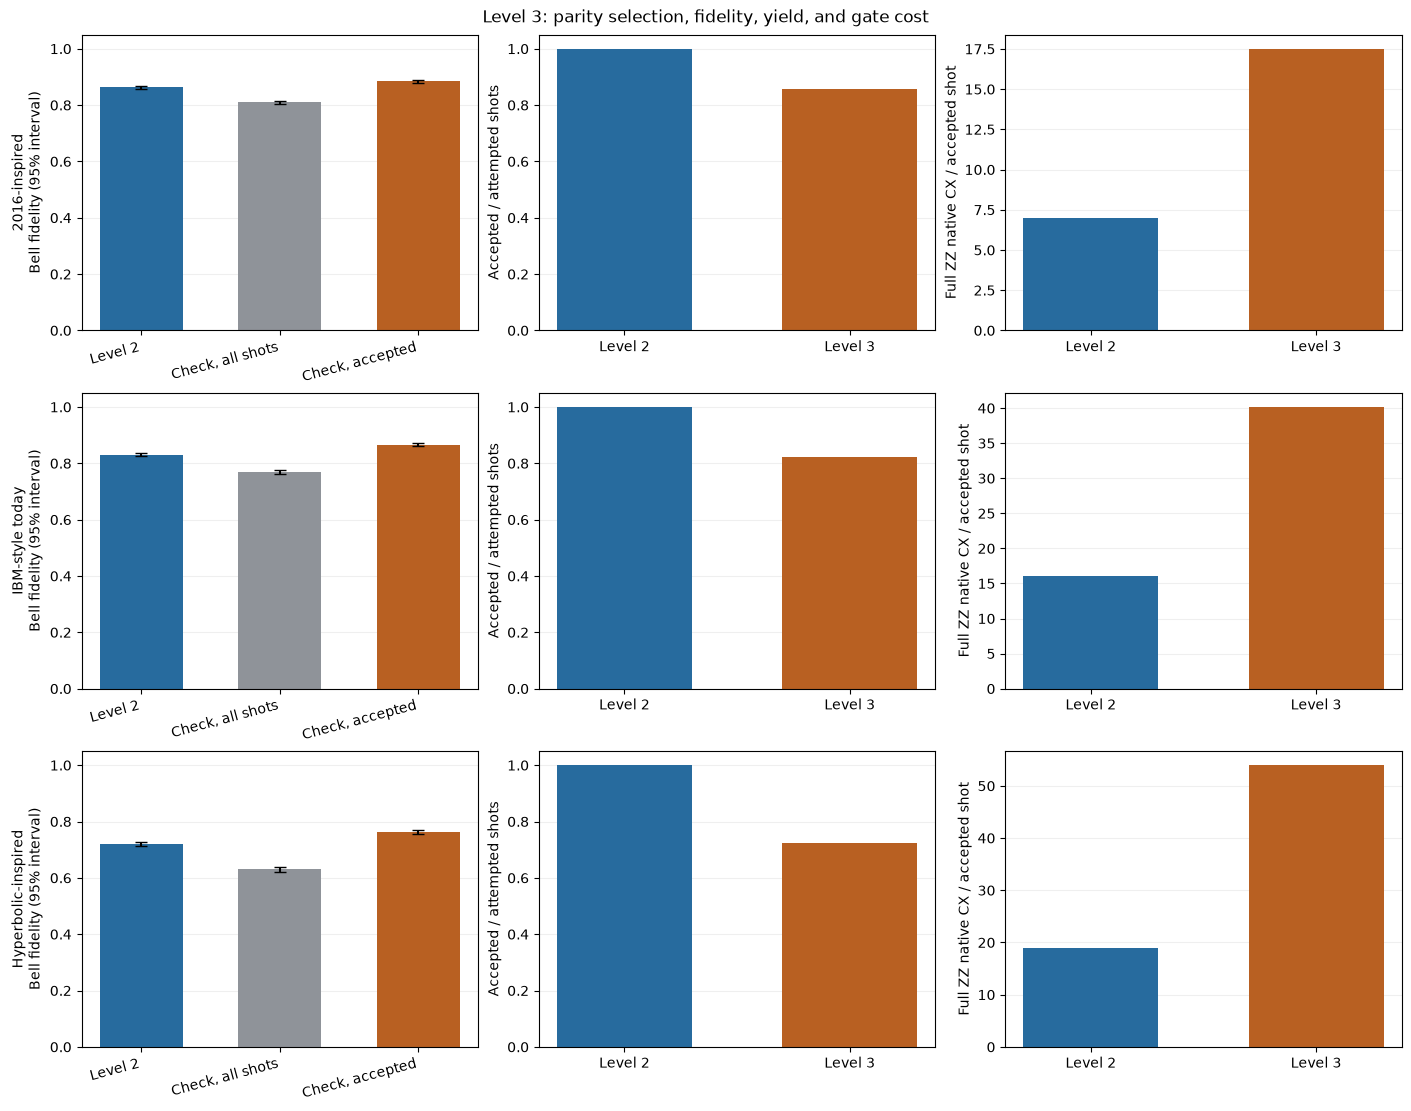

In [18]:
# Depth counts the dependency layers and independent gates on different wires share a layer.
level3_added_costs = pd.DataFrame([
    {"Case": case, "Basis": basis, "Metric": metric,
     "Level 2": level2_results[case - 1]["costs"][basis][metric],
     "Level 3": result["costs"][basis][metric],
     "Added": result["costs"][basis][metric] - level2_results[case - 1]["costs"][basis][metric]}
    for case, result in level3_results.items() for basis in BASIS_ORDER
    for metric in ("Depth", "Two-qubit gates", "SWAPs", "Physical qubits")
])
display(level3_added_costs)

# Divide the full ZZ gate count by pooled yield to include gate work spent on discarded shots.
level3_gate_budget = pd.DataFrame([
    {"Case": case, "Baseline CX / accepted shot": level2_results[case - 1]["summary"]["Two-qubit gates"],
     "Protected CX / accepted shot": result["summary"]["Two-qubit gates"] / result["summary"]["Yield"]
     if result["summary"]["Yield"] else None}
    for case, result in level3_results.items()
])
display(level3_gate_budget)

figure, axes = plt.subplots(3, 3, figsize=(14, 11), layout="constrained")
colors = ("#276b9e", "#8f9399", "#b86022")
for row, (case, result) in enumerate(level3_results.items()):
    baseline = level2_results[case - 1]["summary"]
    protected = result["summary"]
    quality = [("Level 2", baseline["F"], baseline["95% CI"]),
               ("Check, all shots", result["all_shot_fidelity"], result["all_shot_ci"]),
               ("Check, accepted", protected["F"], protected["95% CI"])]
    for index, (_, fidelity, interval) in enumerate(quality):
        if fidelity is not None:
            lower, upper = interval
            axes[row, 0].bar(index, fidelity, color=colors[index], width=0.6)
            axes[row, 0].errorbar(index, fidelity,
                                 yerr=[[max(0, fidelity - lower)], [max(0, upper - fidelity)]],
                                 fmt="none", color="black", capsize=4)
    axes[row, 0].set_xticks(range(3), [entry[0] for entry in quality], rotation=15, ha="right")
    axes[row, 0].set_ylim(0, 1.05)
    axes[row, 0].set_ylabel(f"{protected['Processor model']}\nBell fidelity (95% interval)")
    axes[row, 1].bar(["Level 2", "Level 3"], [1.0, protected["Yield"]],
                     color=[colors[0], colors[2]], width=0.6)
    axes[row, 1].set_ylim(0, 1.05)
    axes[row, 1].set_ylabel("Accepted / attempted shots")
    axes[row, 2].bar(0, baseline["Two-qubit gates"], color=colors[0], width=0.6)
    if protected["Yield"]:
        axes[row, 2].bar(1, protected["Two-qubit gates"] / protected["Yield"],
                         color=colors[2], width=0.6)
    else:
        axes[row, 2].annotate("Zero accepted shots", (0.5, 0.5), xycoords="axes fraction")
    axes[row, 2].set_xticks([0, 1], ["Level 2", "Level 3"])
    axes[row, 2].set_ylabel("Full ZZ native CX / accepted shot")
    for axis in axes[row]:
        axis.grid(axis="y", alpha=0.2)
        axis.set_axisbelow(True)
figure.suptitle("Level 3: parity selection, fidelity, yield, and gate cost")
display(figure)
plt.close(figure)

## Nine-case results

These runs use separate simulator random streams for each basis and experiment.
The physical circuits, noise inputs, and costs retain the merged Level 3 definitions.
Fidelity is conditional for Level 3. Costs cover complete native ZZ circuits.

| Case | Processor model | Level | F | 95% CI | Depth | Two-qubit gates | SWAPs | Physical qubits | Yield | Discarded shots |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 2016-inspired | 1 | 1.000000 | [1.000000, 1.000000] | 6 | 7 | 2 | 4 | 100.0000% | 0 |
| 2 | 2016-inspired | 2 | 0.862488 | [0.856812, 0.867859] | 6 | 7 | 2 | 4 | 100.0000% | 0 |
| 3 | 2016-inspired | 3 | 0.885190 | [0.879695, 0.890395] | 14 | 15 | 4 | 5 | 85.6527% | 3526 |
| 4 | IBM-style today | 1 | 1.000000 | [1.000000, 1.000000] | 14 | 16 | 5 | 7 | 100.0000% | 0 |
| 5 | IBM-style today | 2 | 0.830566 | [0.825134, 0.836549] | 14 | 16 | 5 | 7 | 100.0000% | 0 |
| 6 | IBM-style today | 3 | 0.866458 | [0.860597, 0.872100] | 28 | 33 | 10 | 8 | 82.1655% | 4383 |
| 7 | Hyperbolic-inspired | 1 | 1.000000 | [1.000000, 1.000000] | 12 | 19 | 6 | 8 | 100.0000% | 0 |
| 8 | Hyperbolic-inspired | 2 | 0.721558 | [0.713988, 0.728943] | 12 | 19 | 6 | 8 | 100.0000% | 0 |
| 9 | Hyperbolic-inspired | 3 | 0.763775 | [0.755921, 0.771693] | 32 | 39 | 12 | 9 | 72.2819% | 6812 |

The following cell reports all basis costs and per-basis shot accounting.

In [19]:
official_rows, official_basis_costs, official_shot_rows = [], [], []
for case, pid, level in CASES:
    if level == 1:
        ideal = LEVEL1[pid]
        zz = ideal["runs"]["ZZ"]["costs"]
        summary = {"Case": case, "Processor model": PROCESSORS[pid].name, "Level": level,
                   "F": ideal["F"], "95% CI": ideal["ci"], "Depth": zz["depth"],
                   "Two-qubit gates": zz["two_qubit_gates"], "SWAPs": zz["swaps"],
                   "Physical qubits": zz["physical_qubits"], "Yield": 1.0, "Discarded shots": 0}
        runs = {b: ideal["runs"][b]["counts"] for b in BASIS_ORDER}
    else:
        result = (level2_results if level == 2 else level3_results)[case]
        summary, runs = result["summary"], result["counts"]
    official_rows.append(summary)
    for basis in BASIS_ORDER:
        if level == 1:
            cost = ideal["runs"][basis]["costs"]
            cost = {"Depth": cost["depth"], "Two-qubit gates": cost["two_qubit_gates"],
                    "SWAPs": cost["swaps"], "Physical qubits": cost["physical_qubits"]}
        else:
            cost = result["costs"][basis]
        official_basis_costs.append({"Case": case, "Basis": basis, **cost})
        attempted = sum(runs[basis].values())
        accepted = sum(result["accepted_counts"][basis].values()) if level == 3 else attempted
        official_shot_rows.append({"Case": case, "Basis": basis, "Attempted": attempted,
                                   "Accepted": accepted, "Discarded": attempted - accepted})
official_results_table = pd.DataFrame(official_rows).sort_values("Case").reset_index(drop=True)
official_basis_costs = pd.DataFrame(official_basis_costs)
official_shot_accounting = pd.DataFrame(official_shot_rows)
display(official_results_table, official_basis_costs, official_shot_accounting)

,Case,Processor model,Level,F,95% CI,Depth,Two-qubit gates,SWAPs,Physical qubits,Yield,Discarded shots
0,1,2016-inspired,1,1.000000,"(1.0, 1.0)",6,7,2,4,1.000000,0
1,2,2016-inspired,2,0.862488,"(0.856812, 0.867859)",6,7,2,4,1.000000,0
2,3,2016-inspired,3,0.885190,"(0.879695, 0.890395)",14,15,4,5,0.856527,3526
3,4,IBM-style today,1,1.000000,"(1.0, 1.0)",14,16,5,7,1.000000,0
4,5,IBM-style today,2,0.830566,"(0.825134, 0.836549)",14,16,5,7,1.000000,0
5,6,IBM-style today,3,0.866458,"(0.860597, 0.8721)",28,33,10,8,0.821655,4383
6,7,Hyperbolic-inspired,1,1.000000,"(1.0, 1.0)",12,19,6,8,1.000000,0
7,8,Hyperbolic-inspired,2,0.721558,"(0.713988, 0.728943)",12,19,6,8,1.000000,0
8,9,Hyperbolic-inspired,3,0.763775,"(0.755921, 0.771693)",32,39,12,9,0.722819,6812


,Case,Basis,Depth,Two-qubit gates,SWAPs,Physical qubits
0,1,XX,7,7,2,4
1,1,YY,7,7,2,4
2,1,ZZ,6,7,2,4
3,2,XX,7,7,2,4
4,2,YY,7,7,2,4
5,2,ZZ,6,7,2,4
6,3,XX,15,15,4,5
7,3,YY,16,15,4,5
8,3,ZZ,14,15,4,5
9,4,XX,17,16,5,7


,Case,Basis,Attempted,Accepted,Discarded
0,1,XX,8192,8192,0
1,1,YY,8192,8192,0
2,1,ZZ,8192,8192,0
3,2,XX,8192,8192,0
4,2,YY,8192,8192,0
5,2,ZZ,8192,8192,0
6,3,XX,8192,7028,1164
7,3,YY,8192,7002,1190
8,3,ZZ,8192,7020,1172
9,4,XX,8192,8192,0


## Scientific interpretation and recommendation

The three ideal cases give F=1. The circuit therefore makes the intended Bell
pair at the required output qubits when gates and measurements are perfect.
F is our score for how closely the prepared pair matches that target, estimated
from many measurements. A higher score means a closer match according to those
measurements. The score includes errors in reading the qubits.

Turning on noise lowers the score because the preparation and transport gates
can damage the pair. We then add a check and ask whether the attempts that
pass are good enough to justify the extra work. Comparing the results before
and after throwing away failures separates those two effects:

| Processor | Original noisy circuit F | With check, keeping every attempt F | With check, keeping only passes F | Attempts kept |
|---|---|---|---|---|
| Reference | 0.862488 | 0.809814 | 0.885190 | 85.65% |
| IBM | 0.830566 | 0.768188 | 0.866458 | 82.17% |
| Hyperbolic | 0.721558 | 0.629822 | 0.763775 | 72.28% |

For the reference processor, adding the check first lowers F from about 0.862
to 0.810. Its extra gates introduce more errors. Once we keep only reported
passes, F rises to about 0.885. The check has removed enough damaged attempts
to leave a better sample, even after accounting for the damage it caused.
The same sequence happens on the other two models.

The check uses an extra qubit as a meter. With perfect operations, it reports
a pass for 00 and 11, and a failure for 01 and 10. Both parts of our target
Bell state therefore give the same result, allowing the check to preserve
their superposition. A bit flip on one qubit changes agreement into
disagreement, so the check can flag it. A phase flip changes the relative sign
between 00 and 11 while leaving their agreement intact, so it can pass this
check. An incorrect meter reading can also lead us to keep a damaged attempt.

There is a cost to keeping the better sample. Every attempt uses the checking
gates, including the attempts we throw away. Dividing the gates per attempt
by the fraction kept gives the average gate work per kept result:

| Processor | CNOTs without check | CNOTs in each checked attempt | CNOTs per kept result after checking |
|---|---|---|---|
| Reference | 7 | 15 | 17.51 |
| IBM | 16 | 33 | 40.16 |
| Hyperbolic | 19 | 39 | 53.96 |

On the reference model, the score increases by about 0.023 while the CNOT work
per kept result rises to roughly 2.5 times the original cost. I would pay for
that check when the original pair's quality is insufficient and the higher
score justifies the extra attempts. Level 4 tests whether we can get a similar
improvement more cheaply by changing how we prepare the pair.

The hyperbolic model's lower score also needs context. Its outputs are seven
edges apart, compared with three on the reference model and six on IBM.
Its SWAP circuit therefore needs more CNOTs. The reference and hyperbolic
models use the same synthetic gate and readout noise, while IBM uses different
calibrated gate, relaxation, and readout errors. These results describe the
given routes and noise models; they do not isolate graph shape as the sole
cause of the differences.

For reproducibility, each basis and experiment now uses a separate simulator
random stream. Aer 0.17.2 starts noisy shot j at circuit_seed+j; the earlier
nearby starts reused random trajectories and could make sampling error bars
too small. We reran the same physical circuits with separated starts.
The earlier counts remain in the experiment's history.


## Optional extensions: Levels 4 and 5

Level 4 tries to make the required Bell pair with fewer noisy gates. Level 5
starts with a Bell pair and asks whether extra qubits help one half survive
storage. We record the two studies separately because their output locations
and noise assumptions differ. Level 4 keeps the official graphs, ports, and
noise models. Level 5 uses adjacent output qubits on the hyperbolic graph and
adds a separate model of storage errors.

### Level 4: GHZ-assisted transport

Consider the reference path 0-1-2-3, with outputs required at 0 and 3. The
SWAP method prepares a Bell pair and moves its halves into place. Preparation
uses one CNOT and the two SWAPs use three CNOTs each, giving seven in total.

GHZ transport uses three CNOTs to prepare a shared state across the whole path.
That state contains an all-zero part and an all-one part with a definite phase
relationship. We measure the two middle qubits in X. The endpoints remain
entangled, and the two recorded bits tell us the relative sign of their state.

If the two bits agree, the endpoints already have the desired sign. If they
differ, applying Z to one endpoint changes the sign to the one we want.
For a longer path, we apply Z when the interior results contain an odd number
of ones. Computing that odd-or-even result is the XOR operation in the code.
These measurement results can be random in an ideal experiment; they tell us
which correction to apply, rather than whether the attempt suffered an error.
We keep every corrected attempt and measure how much quality remains after
gate and readout noise.

The three routes need 3, 6, and 7 CNOTs with GHZ transport, compared with 7,
16, and 19 for SWAP transport on the reference, IBM, and hyperbolic models.
We compare growth from one end with growth from the middle to see how the
order and physical location of the gates affect the result. Another version
keeps only even measurement parity and applies no Z correction. With perfect
operations, that rule discards about half the attempts; correcting the phase
lets us keep both branches.

Bell-link swapping tests a second way to connect the endpoints. It prepares
short Bell pairs on separate neighboring edges, then joins them by measuring
their meeting qubits. The recorded results tell us the X and Z corrections
for the final pair. When the path has an unpaired final vertex, a CNOT and
an X measurement extend the last Bell half across that edge. That step is
one-bit teleportation.

We test stronger verification by adding XX to the original ZZ check, so it
checks both bit agreement and the Bell phase. It reuses the meter, whose first
result contributes to the second reading; requiring both recorded bits to be
zero selects both passing checks with ideal operations. SABRE supplies the
software router comparison. We include the SWAPs needed to return every
logical output to its required physical qubit when counting its cost.

The IBM tests run the same circuits with selected error sources enabled.
They let us see whether fewer gates help, and whether extra readout errors
undo that help. We report gates per kept result as well as the score, so
discarding attempts carries a cost. Circuit depth counts dependent layers,
including measurements and taken correction branches. Turning that into
elapsed time would require gate, measurement, and controller durations.


In [20]:
import hashlib
import json
from collections import Counter
from pathlib import Path
import optional_extensions as extensions

EXTENSION_SEED = SEED + 100_000
FIGURE_DIR = Path("docs/assets/levels45")
DATA_DIR = Path("docs/data")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
extension_settings = {
    "Base code": "1dfe9fc", "Shots per basis": SHOTS_PER_BASIS,
    "Bootstrap draws": BOOTSTRAP_RESAMPLES, "Confidence": CONFIDENCE_LEVEL,
    "Native optimization": 0, "Layout": "identity", "Routing": "explicit physical edges",
    "Level 4 run-base rule": "2026 + 100000 + 1000*processor_index + 100*strategy_index",
    "Level 5 bit-flip run-base rule": "2026 + 200000 + 100*experiment_index",
    "Phase run-base rule": "2026 + 400000 + 100*experiment_index",
    "Confirmation run-base rule": "2026 + 500000 + 1000*replicate + 100*strategy_index",
    "Simulator seed rule": "aer_seed(run_base, basis); SHA256 qccr-aer-v1, 52 bits",
    "Basis index": "XX=0, YY=1, ZZ=2", "Transpiler seed": "run base seed",
    "Bootstrap seed": "run base seed + 10",
    "Helper SHA256": hashlib.sha256(Path("optional_extensions.py").read_text(encoding="utf-8").encode()).hexdigest(),
    "Seed policy SHA256": hashlib.sha256(Path("simulation_seeds.py").read_text(encoding="utf-8").encode()).hexdigest(),
    "Official input SHA256": hashlib.sha256(Path("challenge_config.py").read_text(encoding="utf-8").encode()).hexdigest(),
    "Hash convention": "UTF-8 text with normalized LF newlines",
}
display(pd.Series(extension_settings, name="Value").to_frame())

,Value
Base code,1dfe9fc
Shots per basis,8192
Bootstrap draws,2000
Confidence,0.95
Native optimization,0
Layout,identity
Routing,explicit physical edges
Level 4 run-base rule,2026 + 100000 + 1000*processor_index + 100*str...
Level 5 bit-flip run-base rule,2026 + 200000 + 100*experiment_index
Phase run-base rule,2026 + 400000 + 100*experiment_index


In [21]:
level4_results = {}
sabre_rows, level4_sabre_sources = [], {}
for _, pid, _ in LEVEL2_CASES:
    candidates = []
    for routing_seed in (2026, 2033, 2040):
        sources = {b: extensions.sabre_transport(pid, b, seed=routing_seed) for b in BASIS_ORDER}
        native = extensions.compile_optional(sources["ZZ"], pid, seed=routing_seed)
        cost = extensions.resource_costs(native, sources["ZZ"])
        sabre_rows.append({"Processor": pid, "Routing seed": routing_seed,
                           "Routing trials": extensions.SABRE_TRIALS, "Heuristic": "decay", **cost})
        candidates.append((cost["Two-qubit gates"], cost["Depth max"], routing_seed, sources))
    # Choose by structural cost before sampling any noisy candidate.
    best = min(candidates, key=lambda row: row[:3])
    level4_sabre_sources[pid] = {"Routing seed": best[2], "Sources": best[3]}
level4_sabre_candidates = pd.DataFrame(sabre_rows)
display(level4_sabre_candidates)
level4_strategies = (
    ("GHZ left + correction", "left", "feedforward", "all"),
    ("GHZ balanced + correction", "balanced", "feedforward", "all"),
    ("GHZ balanced + even branch", "balanced", "select_even", "even"),
    ("Bell links + correction", "parallel", "bell_links", "all"),
    ("Routed ZZ + XX check", "routed", "two_stabilizers", "zero"),
    ("SABRE CX + full restore", "sabre", "sabre", "all"),
)
for processor_index, (_, pid, _) in enumerate(LEVEL2_CASES):
    route = LEVEL1[pid]["path"]
    case = LEVEL1[pid]["case"] + 1
    for strategy_index, (label, growth, mode, acceptance) in enumerate(level4_strategies):
        if mode == "sabre":
            sources = level4_sabre_sources[pid]["Sources"]
        elif mode == "bell_links":
            sources = {b: extensions.bell_link_transport(pid, route, b) for b in BASIS_ORDER}
        elif mode == "two_stabilizers":
            core = level3_circuits[pid]
            sources = {b: extensions.two_stabilizer_check(
                pid, core["preparation"], core["parity_check"], b) for b in BASIS_ORDER}
        else:
            sources = {b: extensions.ghz_transport(pid, route, b, growth=growth, mode=mode)
                       for b in BASIS_ORDER}
        seed = EXTENSION_SEED + 1000 * processor_index + 100 * strategy_index
        result = extensions.sample_experiment(
            sources, pid, noise_model=level2_results[case]["noise_model"], seed=seed,
            acceptance=acceptance, simulator_options=SIMULATOR_OPTIONS[pid],
        )
        result["parameters"] = {"Study": "Level 4", "Strategy": label,
                                "Route": route, "Growth": growth,
                                "Noise": "official model", "Protocol": mode,
                                "Physical correction": mode in ("feedforward", "bell_links")}
        if mode == "sabre":
            result["parameters"]["Baseline path"] = result["parameters"].pop("Route")
            result["parameters"]["Routing seed"] = level4_sabre_sources[pid]["Routing seed"]
            result["parameters"]["Routing trials"] = extensions.SABRE_TRIALS
            result["parameters"]["Routing heuristic"] = "decay"
            result["parameters"]["Mapping restoration"] = "inverse of all routing SWAPs"
            result["parameters"]["Routing SWAP trace"] = [
                [sources["ZZ"].find_bit(q).index for q in inst.qubits]
                for inst in sources["ZZ"].data if inst.operation.name == "swap"]
        level4_results[f"{pid}: {label}"] = result

level4_rows = []
for _, pid, _ in LEVEL2_CASES:
    case = LEVEL1[pid]["case"] + 1
    for label, original in (("SWAP baseline", level2_results[case]),
                             ("Routed ZZ check", level3_results[case + 1])):
        summary = original["summary"]
        if label == "SWAP baseline":
            native_zz, routed_zz = level2_native_circuits[pid]["ZZ"], level2_routed_circuits[pid]["ZZ"]
        else:
            native_zz = level3_circuits[pid]["native"]["ZZ"]
            routed_zz = level3_circuits[pid]["routed"]["ZZ"]
        # Use the optional fence-aware convention for every comparison row.
        # The original nine-case table retains its recorded core depths.
        comparison_depth = extensions.resource_costs(native_zz, routed_zz)["Depth max"]
        level4_rows.append({"Processor": pid, "Strategy": label, "F": summary["F"],
                            "95% CI": summary["95% CI"], "Yield": summary["Yield"],
                            "Depth max": comparison_depth,
                            "Two-qubit gates": summary["Two-qubit gates"],
                            "Physical qubits": summary["Physical qubits"],
                            "CX / accepted shot": summary["Two-qubit gates"] / summary["Yield"]})
    for label, _, _, _ in level4_strategies:
        result = level4_results[f"{pid}: {label}"]
        cost = result["costs"]["ZZ"]
        level4_rows.append({"Processor": pid, "Strategy": label, "F": result["F"],
                            "95% CI": result["95% CI"], "Yield": result["Yield"],
                            "Depth max": cost["Depth max"],
                            "Two-qubit gates": cost["Two-qubit gates"],
                            "Physical qubits": cost["Physical qubits"],
                            "CX / accepted shot": result["CX / accepted shot"]})
level4_table = pd.DataFrame(level4_rows)
display(level4_table)

,Processor,Routing seed,Routing trials,Heuristic,Depth max,Two-qubit gates,SWAPs,Physical qubits,Measurements,Conditional operations,u gates max,Storage markers
0,reference_2016,2026,4,decay,9,13,4,4,2,0,1,0
1,reference_2016,2033,4,decay,9,13,4,4,2,0,1,0
2,reference_2016,2040,4,decay,9,13,4,4,2,0,1,0
3,ibm_today,2026,4,decay,29,31,10,7,2,0,0,0
4,ibm_today,2033,4,decay,23,31,10,7,2,0,0,0
5,ibm_today,2040,4,decay,23,31,10,7,2,0,0,0
6,hyperbolic,2026,4,decay,27,37,12,8,2,0,1,0
7,hyperbolic,2033,4,decay,27,37,12,8,2,0,1,0
8,hyperbolic,2040,4,decay,21,37,12,8,2,0,1,0


,Processor,Strategy,F,95% CI,Yield,Depth max,Two-qubit gates,Physical qubits,CX / accepted shot
0,reference_2016,SWAP baseline,0.862488,"(0.856812, 0.867859)",1.000000,6,7,4,7.000000
1,reference_2016,Routed ZZ check,0.885190,"(0.879695, 0.890395)",0.856527,15,15,5,17.512589
2,reference_2016,GHZ left + correction,0.885010,"(0.879942, 0.890076)",1.000000,8,3,4,3.000000
3,reference_2016,GHZ balanced + correction,0.882263,"(0.877136, 0.88739)",1.000000,7,3,4,3.000000
4,reference_2016,GHZ balanced + even branch,0.888543,"(0.881643, 0.895506)",0.501587,6,3,4,5.981017
5,reference_2016,Bell links + correction,0.885071,"(0.879944, 0.890016)",1.000000,7,3,4,3.000000
6,reference_2016,Routed ZZ + XX check,0.902442,"(0.897178, 0.907914)",0.701782,30,29,5,41.323361
7,reference_2016,SABRE CX + full restore,0.814880,"(0.808714, 0.821046)",1.000000,9,13,4,13.000000
8,ibm_today,SWAP baseline,0.830566,"(0.825134, 0.836549)",1.000000,14,16,7,16.000000
9,ibm_today,Routed ZZ check,0.866458,"(0.860597, 0.8721)",0.821655,29,33,8,40.162829


,Noise components,Strategy,F,95% CI,Yield
0,Ideal,SWAP baseline,1.000000,"(1.0, 1.0)",1.0
1,Ideal,GHZ balanced + correction,1.000000,"(1.0, 1.0)",1.0
2,Gate + relaxation only,SWAP baseline,0.866089,"(0.860838, 0.871521)",1.0
3,Gate + relaxation only,GHZ balanced + correction,0.930725,"(0.926697, 0.934509)",1.0
4,Readout only,SWAP baseline,0.963806,"(0.960754, 0.966553)",1.0
5,Readout only,GHZ balanced + correction,0.886963,"(0.882199, 0.891724)",1.0
6,Full calibration,SWAP baseline,0.835205,"(0.829407, 0.841005)",1.0
7,Full calibration,GHZ balanced + correction,0.826111,"(0.820312, 0.831787)",1.0


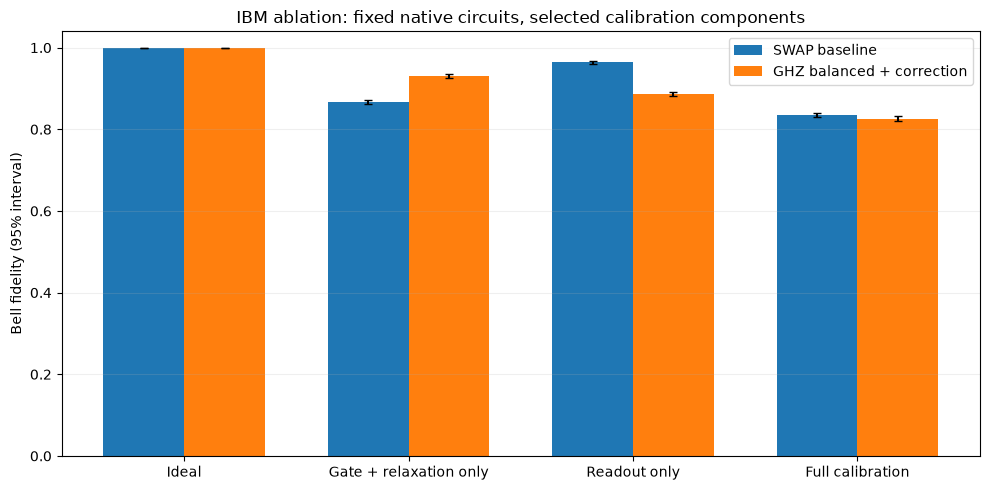

In [22]:
from qiskit_aer.noise import NoiseModel
calibration_models = {
    "Ideal": None,
    "Gate + relaxation only": NoiseModel.from_backend(
        ibm_backend, gate_error=True, readout_error=False, thermal_relaxation=True, temperature=0),
    "Readout only": NoiseModel.from_backend(
        ibm_backend, gate_error=False, readout_error=True, thermal_relaxation=False, temperature=0),
    "Full calibration": level2_results[5]["noise_model"],
}
level4_ablation, ablation_rows = {}, []
for factor_index, (factor, noise) in enumerate(calibration_models.items()):
    for strategy_index, label in enumerate(("SWAP baseline", "GHZ balanced + correction")):
        if strategy_index == 0:
            sources = level2_routed_circuits["ibm_today"]
            native = level2_native_circuits["ibm_today"]
            setting_keys = ("Source ideal case", "Transpiler seed", "Routed initial layout",
                            "Native initial layout", "Routed optimization level", "Native optimization level")
            source_settings = {k: level2_results[5]["settings"][k] for k in setting_keys}
        else:
            sources = {b: extensions.ghz_transport("ibm_today", LEVEL1["ibm_today"]["path"], b)
                       for b in BASIS_ORDER}
            original = level4_results["ibm_today: GHZ balanced + correction"]
            native = original["native_circuits"]
            source_settings = {k: original["settings"][k] for k in
                               ("Transpiler seed", "Optimization level", "Initial layout", "Routing")}
        # Keep each protocol's exact native circuit while switching the
        # calibrated error components. This isolates the source of the loss.
        result = extensions.sample_experiment(
            sources, "ibm_today", seed=SEED + 600_000 + 1000 * factor_index + 100 * strategy_index,
            noise_model=noise, native_circuits=native, source_compilation=source_settings,
            simulator_options=SIMULATOR_OPTIONS["ibm_today"],
        )
        result["parameters"] = {"Study": "IBM noise ablation", "Strategy": label,
                                "Noise components": factor, "Temperature mK": 0}
        level4_ablation[f"{factor}: {label}"] = result
        ablation_rows.append({"Noise components": factor, "Strategy": label,
                               "F": result["F"], "95% CI": result["95% CI"], "Yield": result["Yield"]})
level4_ablation_table = pd.DataFrame(ablation_rows)
display(level4_ablation_table)
fig, ax = plt.subplots(figsize=(10, 5))
for strategy_index, label in enumerate(("SWAP baseline", "GHZ balanced + correction")):
    subset = level4_ablation_table[level4_ablation_table["Strategy"] == label]
    positions = np.arange(4) + (strategy_index - 0.5) * 0.36
    errors = np.array([[max(0, f - ci[0]), max(0, ci[1] - f)]
                       for f, ci in zip(subset["F"], subset["95% CI"])]).T
    ax.bar(positions, subset["F"], width=0.36, yerr=errors, capsize=3, label=label)
ax.set_xticks(np.arange(4), list(calibration_models))
ax.set_ylim(0, 1.04); ax.set_ylabel("Bell fidelity (95% interval)")
ax.set_title("IBM ablation: fixed native circuits, selected calibration components")
ax.legend(); ax.grid(axis="y", alpha=0.2)
fig.tight_layout(); fig.savefig(FIGURE_DIR / "level4_ibm_noise_ablation.png", dpi=150)
display(fig); plt.close(fig)

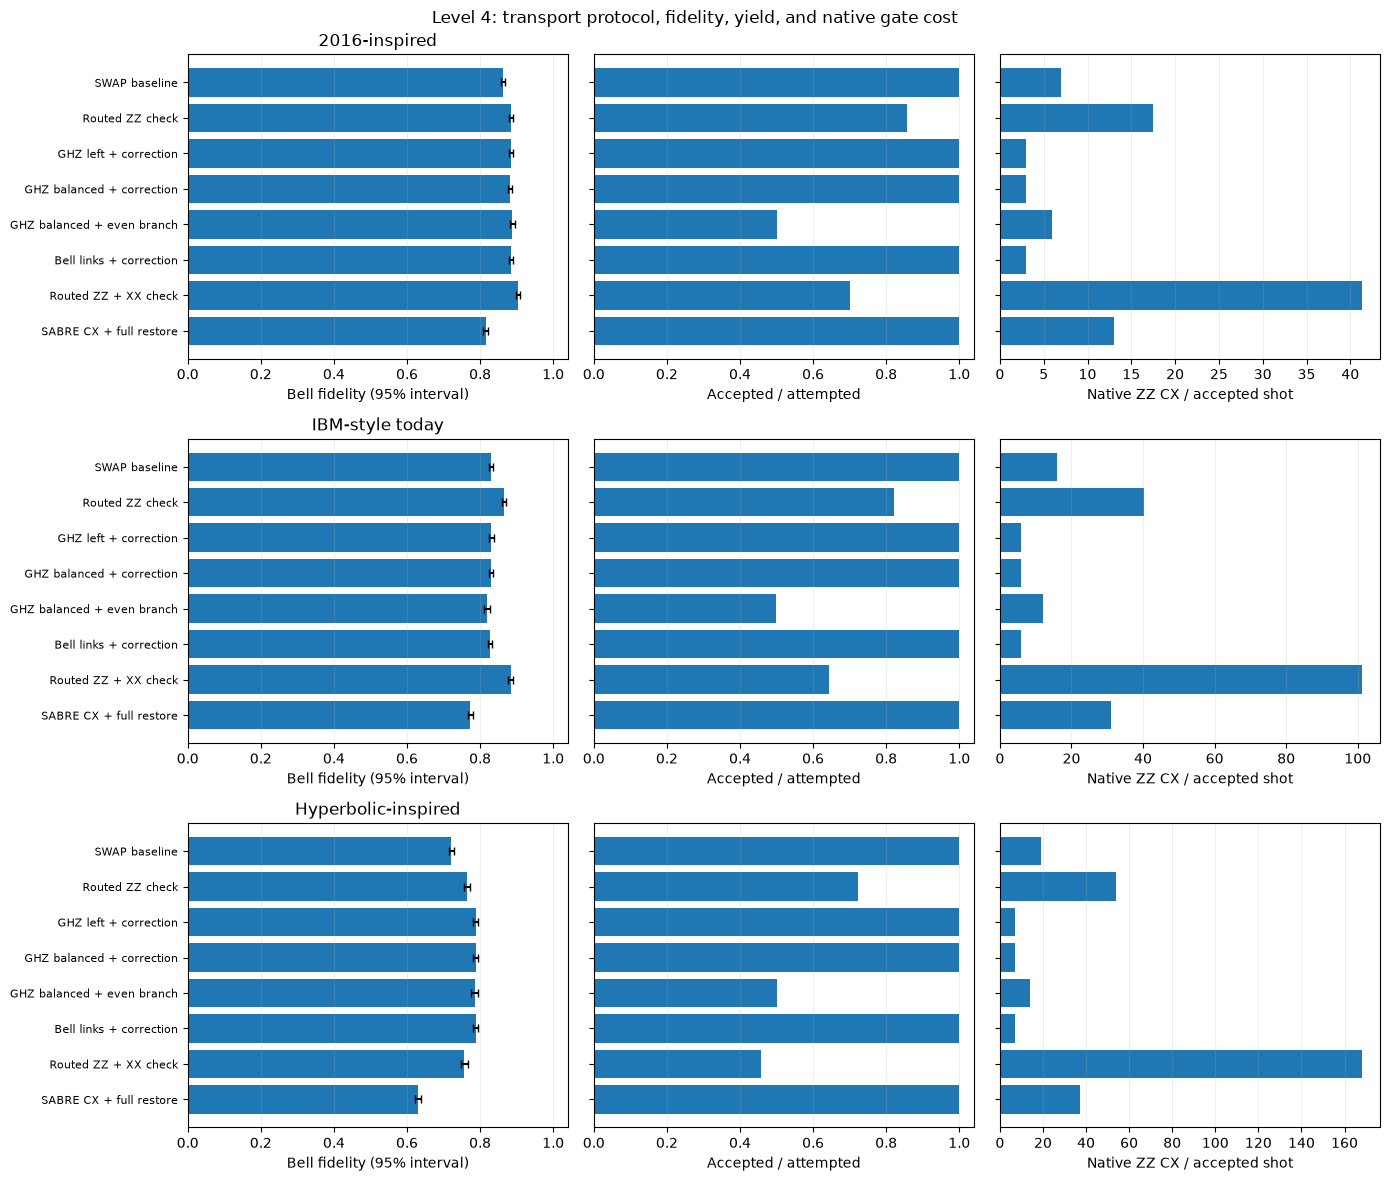

In [23]:
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for row, (_, pid, _) in enumerate(LEVEL2_CASES):
    subset = level4_table[level4_table["Processor"] == pid]
    labels = subset["Strategy"].tolist()
    positions = np.arange(len(labels))
    errors = np.array([[max(0, f - ci[0]), max(0, ci[1] - f)]
                       for f, ci in zip(subset["F"], subset["95% CI"])]).T
    axes[row, 0].barh(positions, subset["F"], xerr=errors, capsize=3)
    axes[row, 1].barh(positions, subset["Yield"])
    axes[row, 2].barh(positions, subset["CX / accepted shot"])
    axes[row, 0].set_xlim(0, 1.04)
    axes[row, 1].set_xlim(0, 1.04)
    for col, ylabel in enumerate(("Bell fidelity (95% interval)", "Accepted / attempted",
                                  "Native ZZ CX / accepted shot")):
        axes[row, col].set_yticks(positions, labels if col == 0 else [""] * len(labels), fontsize=8)
        axes[row, col].invert_yaxis()
        axes[row, col].set_xlabel(ylabel)
        axes[row, col].grid(axis="x", alpha=0.2)
    axes[row, 0].set_title(PROCESSORS[pid].name)
fig.suptitle("Level 4: transport protocol, fidelity, yield, and native gate cost")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "level4_transport_comparison.png", dpi=150, bbox_inches="tight")
display(fig)
plt.close(fig)

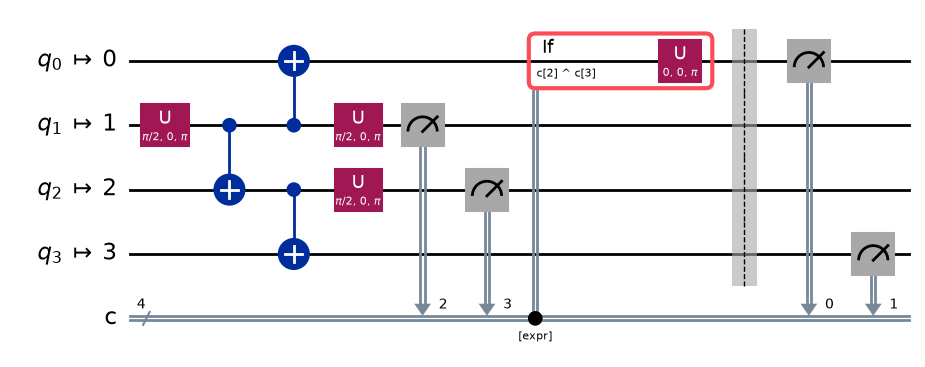

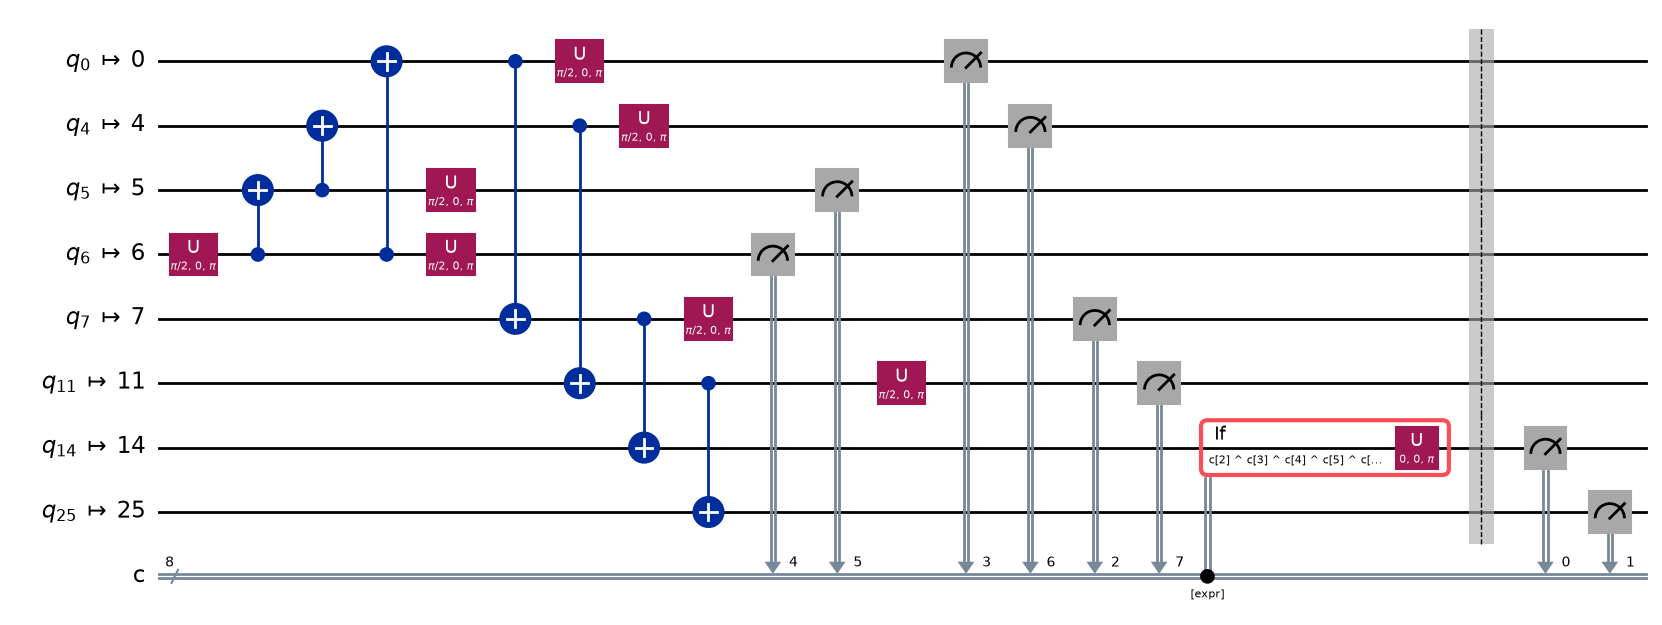

In [24]:
for pid in ("reference_2016", "hyperbolic"):
    circuit = level4_results[f"{pid}: GHZ balanced + correction"]["native_circuits"]["ZZ"]
    figure = circuit.draw(output="mpl", idle_wires=False, fold=90)
    figure.savefig(FIGURE_DIR / f"level4_{pid}_dynamic.png", dpi=150, bbox_inches="tight")
    display(figure)
    plt.close(figure)

### Level 5: a stabilizer network fitted to a cycle

Level 5 asks whether extra data qubits help preserve a Bell half while it is
stored. We use the cycle 0-1-8-16-15-14-7-0. Qubit 6 holds the other Bell half
and is our reference; qubit 0 is where the stored half returns after decoding.
Both the encoded and unencoded experiments use those same output locations.

With three data qubits, encoding represents logical 0 as 000 and logical 1 as
111. It preserves the superposition connecting those two parts to the reference
qubit. More generally, the two encoded states are $|0\rangle^{\otimes n}$ and
$|1\rangle^{\otimes n}$. Here n counts data qubits; the reference is extra.

We check whether neighboring data bits agree. Both 000 and 111 pass, so an
ideal check can preserve the superposition between them. A bit flip can change
000 into 010, which makes neighbors disagree. The code reads each neighboring
ZZ check by applying CNOT, measuring its target, then applying CNOT again to
restore the data representation. We decode every attempt and keep only those
whose recorded check bits are all zero. The decoding gates on rejected attempts
still count toward the cost.

The check can miss an error that flips the whole group: 000 becomes 111 and
all neighbors still agree. With independent 20% storage bit-flip probability
on each of three data qubits, that pattern occurs with probability 0.2 cubed,
or 0.008. No bit flips occur with probability 0.8 cubed, or 0.512. With ideal
operations and no phase errors, these are the two passing patterns. We keep
52% of attempts, and 0.512 divided by 0.520 gives fidelity about 0.9846 in
this particular mixture. This count explains why the selected sample improves.

For general n, independent storage bit flips with probability $p_X$ give
acceptance $y=(1-p_X)^n+p_X^n$. The undetected whole-group flip has probability
$p_X^n$. Increasing n makes that error rarer over the storage probabilities
we test, but also reduces the fraction of attempts we keep.

A phase flip creates a different failure. It changes the relative sign of
the stored state while the neighbors still agree, so every ideal ZZ check
can pass. An odd number of phase flips leaves the wrong sign; an even number
cancels. With independent phase-flip probability $p_Z$, the ideal decoded
fidelity is

$$
F=\frac{(1-p_X)^n[1+(1-2p_Z)^n]}{2y}.
$$

We test data sizes from one through seven, and also add the closing edge
for the seven-data block. That extra check adds two CNOTs but leaves the
ideal code space unchanged: the path already forces all neighboring bits
to agree. Its extra operations can introduce errors, while the extra check
can detect some errors introduced during the checking sequence. We measure
both effects instead of assuming the loop improves protection.

Each data `id` marks the added storage interval. The reference receives no
storage errors, while its preparation and readout still receive operation
noise. The gate and readout parameters scale together by $g$: $p_1=0.002g$,
$p_2=0.02g$, and $r=0.015g$. At g=0.1 these parameters are one-tenth of their
values at g=1. We vary storage errors separately, then include noise in
encoding, checking, decoding, and readout to find when protection repays
its added cost.

We use a faster simulator for the gates in this storage experiment. Its
Clifford method applies the same gate-by-gate noise model: at native
optimization 0, each source H/Sdg/Pauli becomes one noisy `u`. Tests compare
that calculation with a second method, MPS, running the native gate circuit.


,Value
Cycle vertices,"[0, 1, 8, 16, 15, 14, 7]"
Reference,6
Output ports,"(6, 0)"
Data sizes,"[1, 2, 3, 4, 5, 6, 7]"
Acceptance,all reported check bits zero


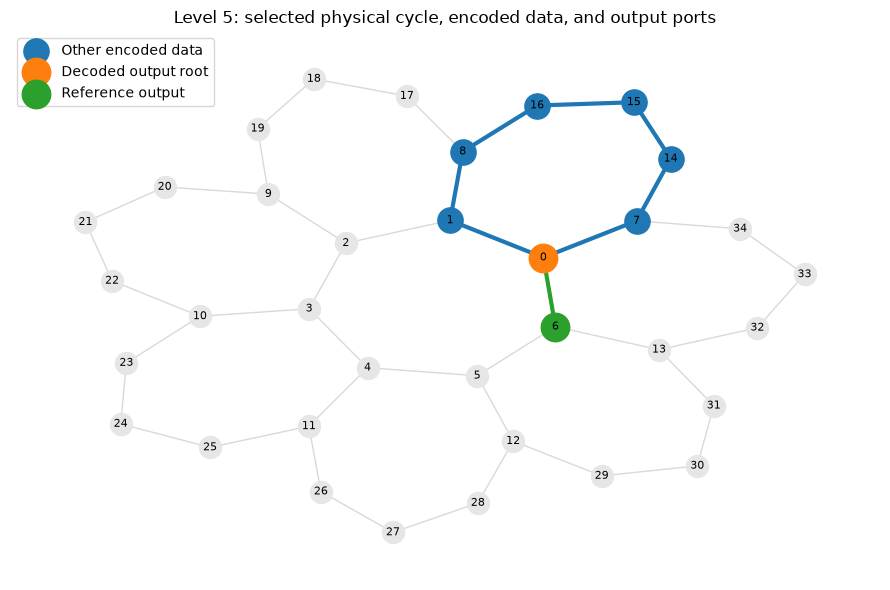

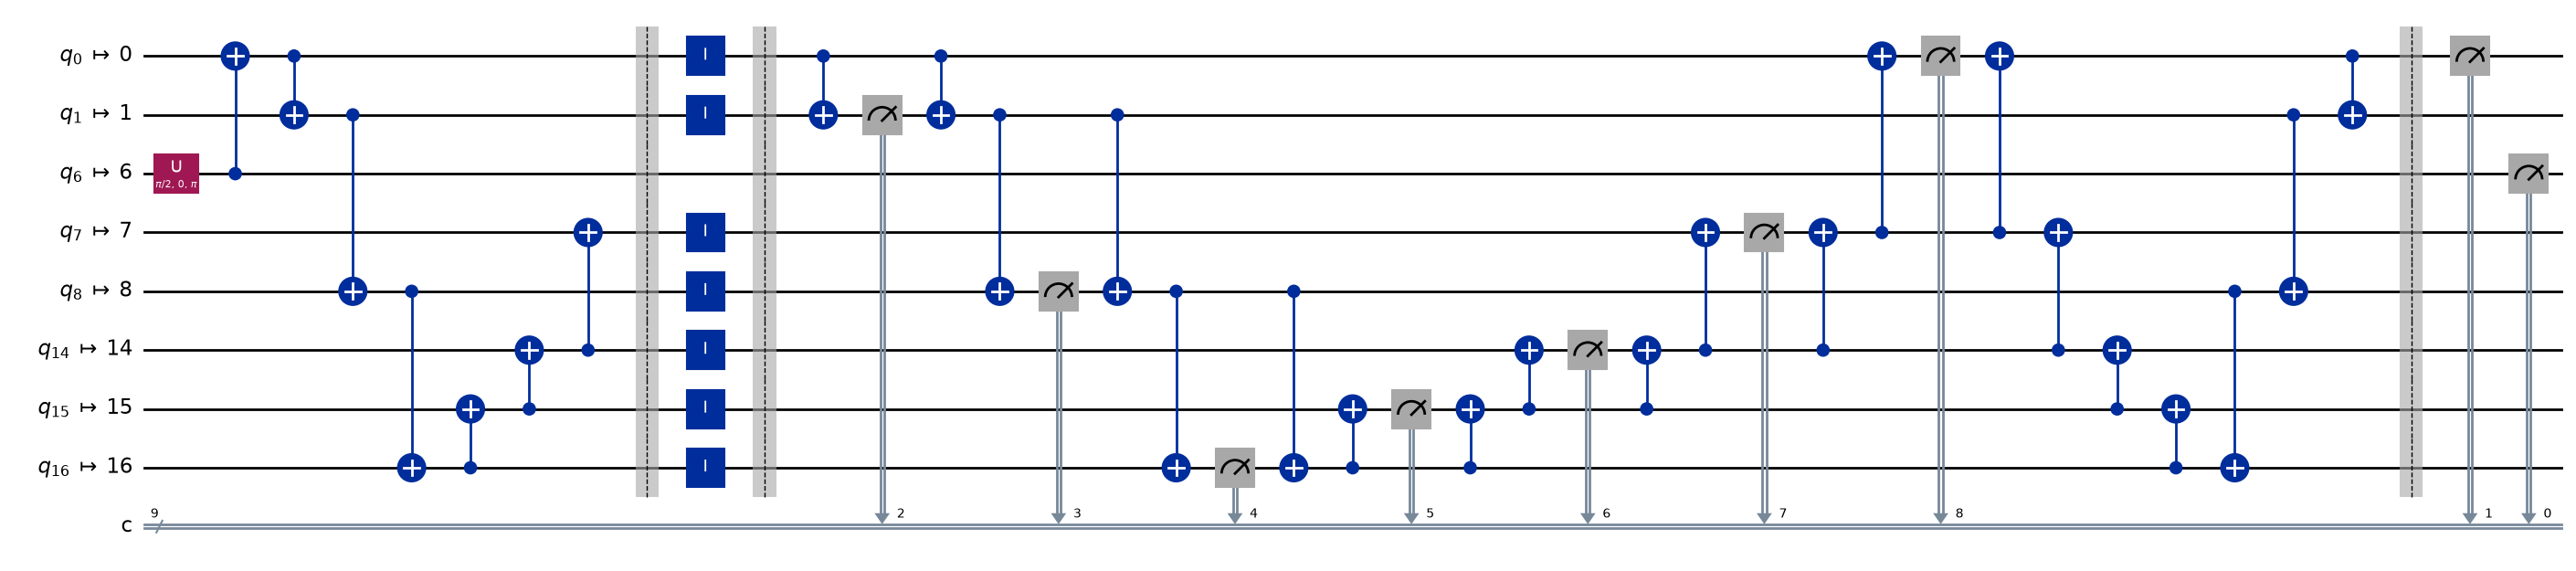

In [25]:
cycle, cycle_reference = extensions.cycle_layout()
storage_ports = (cycle_reference, cycle[0])
level5_designs = (("Unencoded", 1, False),) + tuple(
    (f"{n}-data path", n, False) for n in range(2, 8)
) + (("7-data cycle", 7, True),)
level5_sources = {
    label: {b: extensions.cycle_memory_circuit(cycle[:n], cycle_reference, b, close_cycle=closed)
            for b in BASIS_ORDER} for label, n, closed in level5_designs
}
display(pd.Series({"Cycle vertices": cycle, "Reference": cycle_reference,
                   "Output ports": storage_ports, "Data sizes": list(range(1, 8)),
                   "Acceptance": "all reported check bits zero"}, name="Value").to_frame())
graph = nx.Graph(PROCESSORS["hyperbolic"].edges)
positions = nx.kamada_kawai_layout(graph)
fig, ax = plt.subplots(figsize=(9, 6))
nx.draw_networkx_edges(graph, positions, ax=ax, edge_color="0.85")
nx.draw_networkx_nodes(graph, positions, ax=ax, node_color="0.9", node_size=250)
cycle_edges = list(zip(cycle, cycle[1:] + cycle[:1]))
nx.draw_networkx_edges(graph, positions, edgelist=cycle_edges, width=3, edge_color="tab:blue", ax=ax)
nx.draw_networkx_nodes(graph, positions, nodelist=cycle[1:], node_color="tab:blue", ax=ax,
                       label="Other encoded data", node_size=330)
nx.draw_networkx_nodes(graph, positions, nodelist=[cycle[0]], node_color="tab:orange", ax=ax,
                       label="Decoded output root", node_size=420)
nx.draw_networkx_nodes(graph, positions, nodelist=[cycle_reference], node_color="tab:green", ax=ax,
                       label="Reference output", node_size=420)
nx.draw_networkx_edges(graph, positions, edgelist=[storage_ports], edge_color="tab:green", width=3, ax=ax)
nx.draw_networkx_labels(graph, positions, font_size=8, ax=ax)
ax.set_title("Level 5: selected physical cycle, encoded data, and output ports")
ax.legend(loc="upper left"); ax.axis("off")
fig.tight_layout(); fig.savefig(FIGURE_DIR / "level5_cycle_layout.png", dpi=150)
display(fig); plt.close(fig)
circuit = extensions.compile_optional(level5_sources["7-data cycle"]["ZZ"], "hyperbolic",
                                       seed=SEED + 200_000)
figure = circuit.draw(output="mpl", idle_wires=False, fold=100)
figure.savefig(FIGURE_DIR / "level5_cycle_native_zz.png", dpi=150, bbox_inches="tight")
display(figure); plt.close(figure)

In [26]:
level5_results, level5_rows = {}, []
gate_scales = (0.0, 0.1, 1.0)
storage_bitflip_rates = (0.0, 0.05, 0.1, 0.2, 0.3)
experiment_index = 0
for gate_scale in gate_scales:
    for p_x in storage_bitflip_rates:
        for label, n, closed in level5_designs:
            seed = SEED + 200_000 + 100 * experiment_index
            result = extensions.sample_experiment(
                level5_sources[label], "hyperbolic", seed=seed, acceptance="zero",
                ports=storage_ports, noise_model=extensions.storage_noise(gate_scale, p_x, clifford=True),
                clifford_simulation=True,
            )
            result["parameters"] = {"Study": "Level 5 bit-flip sweep", "Design": label,
                                    "Data vertices": cycle[:n], "Reference": cycle_reference,
                                    "Closed cycle": closed, "Gate scale": gate_scale,
                                    "p_X": p_x, "p_Z": 0.0,
                                    "Storage markers": "one id per data qubit"}
            prediction = extensions.ideal_storage_prediction(n, p_x)
            level5_results[f"run-{experiment_index:03d}"] = result
            level5_rows.append({"Design": label, "n": n, "g": gate_scale, "p_X": p_x,
                                "F": result["F"], "95% CI": result["95% CI"], "Yield": result["Yield"],
                                "Ideal F": prediction["F"], "Ideal yield": prediction["Yield"],
                                "CX / accepted shot": result["CX / accepted shot"],
                                **result["costs"]["ZZ"]})
            experiment_index += 1
level5_table = pd.DataFrame(level5_rows)
display(level5_table.pivot(index=["g", "p_X"], columns="Design", values="F"))
display(level5_table.pivot(index=["g", "p_X"], columns="Design", values="Yield"))
display(level5_table[(level5_table["g"] == 0) & (level5_table["p_X"] == 0)]
        [["Design", "Depth max", "Two-qubit gates", "Physical qubits", "Measurements", "SWAPs"]])

Design    2-data path  3-data path  4-data path  5-data path  6-data path  \
g   p_X                                                                     
0.0 0.00     1.000000     1.000000     1.000000     1.000000     1.000000   
    0.05     0.996767     0.999573     1.000000     1.000000     1.000000   
    0.10     0.988081     0.998062     0.999905     1.000000     1.000000   
    0.20     0.940488     0.985426     0.995094     0.998365     0.999771   
    0.30     0.849172     0.924555     0.968414     0.985712     0.993956   
0.1 0.00     0.989709     0.987256     0.987062     0.984692     0.980920   
    0.05     0.986934     0.987638     0.986266     0.984649     0.983390   
    0.10     0.976799     0.985745     0.984275     0.984440     0.980750   
    0.20     0.928642     0.971938     0.981113     0.978836     0.979482   
    0.30     0.834784     0.919330     0.946438     0.969199     0.971224   
1.0 0.00     0.900025     0.881590     0.868789     0.848493     0.839379   
    0.05     0.891430     0.883970     0.865197     0.846950     0.836470   
    0.10     0.882571     0.868312     0.863572     0.840299     0.831745   
    0.20     0.841278     0.857891     0.850095     0.836730     0.823930   
    0.30     0.754413     0.800014     0.821034     0.811530     0.781646   

Design    7-data cycle  7-data path  Unencoded  
g   p_X                                         
0.0 0.00      1.000000     1.000000   1.000000  
    0.05      1.000000     1.000000   0.946228  
    0.10      1.000000     1.000000   0.898621  
    0.20      1.000000     1.000000   0.799988  
    0.30      0.992517     0.999254   0.696838  
0.1 0.00      0.978016     0.981893   0.993286  
    0.05      0.979652     0.978792   0.941528  
    0.10      0.976054     0.981391   0.892273  
    0.20      0.975117     0.977681   0.793884  
    0.30      0.979637     0.966913   0.691223  
1.0 0.00      0.806137     0.825410   0.937073  
    0.05      0.814838     0.812958   0.895264  
    0.10      0.816216     0.816780   0.849060  
    0.20      0.798251     0.820109   0.755066  
    0.30      0.773030     0.789121   0.666260

Design    2-data path  3-data path  4-data path  5-data path  6-data path  \
g   p_X                                                                     
0.0 0.00     1.000000     1.000000     1.000000     1.000000     1.000000   
    0.05     0.906535     0.857625     0.815470     0.774007     0.732544   
    0.10     0.818197     0.725627     0.652547     0.590698     0.530273   
    0.20     0.680827     0.520874     0.409261     0.333862     0.261353   
    0.30     0.575968     0.371419     0.247721     0.170369     0.118205   
0.1 0.00     0.996419     0.991577     0.986165     0.981283     0.975749   
    0.05     0.901774     0.849365     0.800171     0.760620     0.712484   
    0.10     0.817098     0.723145     0.648031     0.576131     0.521200   
    0.20     0.677368     0.516602     0.407674     0.326009     0.258341   
    0.30     0.582804     0.371501     0.249959     0.166300     0.114705   
1.0 0.00     0.967082     0.917033     0.863241     0.820760     0.780192   
    0.05     0.877441     0.790365     0.710205     0.637817     0.576335   
    0.10     0.800496     0.679606     0.577677     0.496541     0.424154   
    0.20     0.671183     0.485758     0.366618     0.278605     0.212769   
    0.30     0.579346     0.357829     0.233398     0.148804     0.102743   

Design    7-data cycle  7-data path  Unencoded  
g   p_X                                         
0.0 0.00      1.000000     1.000000        1.0  
    0.05      0.698649     0.697428        1.0  
    0.10      0.480062     0.481689        1.0  
    0.20      0.207479     0.210653        1.0  
    0.30      0.081787     0.081706        1.0  
0.1 0.00      0.965454     0.970093        1.0  
    0.05      0.672038     0.677816        1.0  
    0.10      0.461833     0.464518        1.0  
    0.20      0.208049     0.204915        1.0  
    0.30      0.080485     0.079631        1.0  
1.0 0.00      0.703613     0.736125        1.0  
    0.05      0.499146     0.520101        1.0  
    0.10      0.342936     0.354899        1.0  
    0.20      0.151896     0.163005        1.0  
    0.30      0.060018     0.064941        1.0

,Design,Depth max,Two-qubit gates,Physical qubits,Measurements,SWAPs
0,Unencoded,4,1,2,2,0
1,2-data path,9,5,3,3,0
2,3-data path,14,9,4,4,0
3,4-data path,19,13,5,5,0
4,5-data path,24,17,6,6,0
5,6-data path,29,21,7,7,0
6,7-data path,34,25,8,8,0
7,7-data cycle,37,27,8,9,0


In [27]:
level5_phase_results, phase_rows = {}, []
phase_designs = [design for design in level5_designs
                 if design[0] in ("Unencoded", "3-data path", "5-data path", "7-data cycle")]
for experiment_index, (p_z, design) in enumerate(
        (p_z, design) for p_z in (0.0, 0.02, 0.05, 0.1, 0.2) for design in phase_designs):
    label, n, closed = design
    seed = SEED + 400_000 + 100 * experiment_index
    result = extensions.sample_experiment(
        level5_sources[label], "hyperbolic", seed=seed, acceptance="zero", ports=storage_ports,
        noise_model=extensions.storage_noise(0.0, 0.0, p_z, clifford=True),
        clifford_simulation=True,
    )
    result["parameters"] = {"Study": "Phase control", "Design": label, "n": n,
                            "Gate scale": 0.0, "p_X": 0.0, "p_Z": p_z,
                            "Data vertices": cycle[:n], "Reference": cycle_reference}
    level5_phase_results[f"phase-{experiment_index:03d}"] = result
    prediction = extensions.ideal_storage_prediction(n, 0.0, p_z)
    phase_rows.append({"Design": label, "n": n, "p_Z": p_z, "F": result["F"],
                       "95% CI": result["95% CI"], "Yield": result["Yield"],
                       "Ideal F": prediction["F"]})
level5_phase_table = pd.DataFrame(phase_rows)
display(level5_phase_table)

,Design,n,p_Z,F,95% CI,Yield,Ideal F
0,Unencoded,1,0.00,1.000000,"(1.0, 1.0)",1.0,1.000000
1,3-data path,3,0.00,1.000000,"(1.0, 1.0)",1.0,1.000000
2,5-data path,5,0.00,1.000000,"(1.0, 1.0)",1.0,1.000000
3,7-data cycle,7,0.00,1.000000,"(1.0, 1.0)",1.0,1.000000
4,Unencoded,1,0.02,0.978516,"(0.976257, 0.980652)",1.0,0.980000
5,3-data path,3,0.02,0.940308,"(0.936768, 0.943848)",1.0,0.942368
6,5-data path,5,0.02,0.909790,"(0.905333, 0.914062)",1.0,0.907686
7,7-data cycle,7,0.02,0.879211,"(0.87439, 0.884155)",1.0,0.875724
8,Unencoded,1,0.05,0.948181,"(0.944763, 0.951599)",1.0,0.950000
9,3-data path,3,0.05,0.868713,"(0.863342, 0.873962)",1.0,0.864500


In [28]:
# This storage point was fixed before the sweep: p_X=0.2, p_Z=0, g=0.1.
# Four new seeds test the bit-flip gain of this prespecified block.
level5_confirmation, level5_confirmation_pooled = {}, {}
for replicate in range(4):
    for strategy_index, label in enumerate(("Unencoded", "3-data path")):
        seed = SEED + 500_000 + 1000 * replicate + 100 * strategy_index
        result = extensions.sample_experiment(
            level5_sources[label], "hyperbolic", seed=seed, acceptance="zero", ports=storage_ports,
            noise_model=extensions.storage_noise(0.1, 0.2, clifford=True), clifford_simulation=True,
        )
        result["parameters"] = {"Study": "Independent confirmation", "Replicate": replicate,
                                "Design": label, "Gate scale": 0.1, "p_X": 0.2, "p_Z": 0.0}
        level5_confirmation[f"{replicate}: {label}"] = result
for strategy_index, label in enumerate(("Unencoded", "3-data path")):
    counts = {b: Counter() for b in BASIS_ORDER}
    for result in level5_confirmation.values():
        if result["parameters"]["Design"] == label:
            for basis in BASIS_ORDER:
                counts[basis].update(result["counts"][basis])
    pooled = extensions.count_statistics(counts, "zero", seed=SEED + 590_000 + 100 * strategy_index)
    pooled["settings"] = {"Independent replicates": 4, "Shots per basis": 4 * SHOTS_PER_BASIS,
                          "Bootstrap seed": SEED + 590_000 + 100 * strategy_index,
                          "Bootstrap draws": BOOTSTRAP_RESAMPLES}
    level5_confirmation_pooled[label] = pooled
level5_confirmed_gain = extensions.fidelity_gain(
    level5_confirmation_pooled["3-data path"], level5_confirmation_pooled["Unencoded"],
    seed=SEED + 599_000,
)
display(pd.DataFrame([{"Design": label, "F": result["F"], "95% CI": result["95% CI"],
                       "Yield": result["Yield"]} for label, result in level5_confirmation_pooled.items()]))
display(pd.Series(level5_confirmed_gain, name="Fidelity gain").to_frame())

,Design,F,95% CI,Yield
0,Unencoded,0.794769,"(0.791763, 0.797837)",1.000000
1,3-data path,0.971821,"(0.970111, 0.973532)",0.517944


,Fidelity gain
Gain,0.177052
95% CI,"(0.173591, 0.18052)"


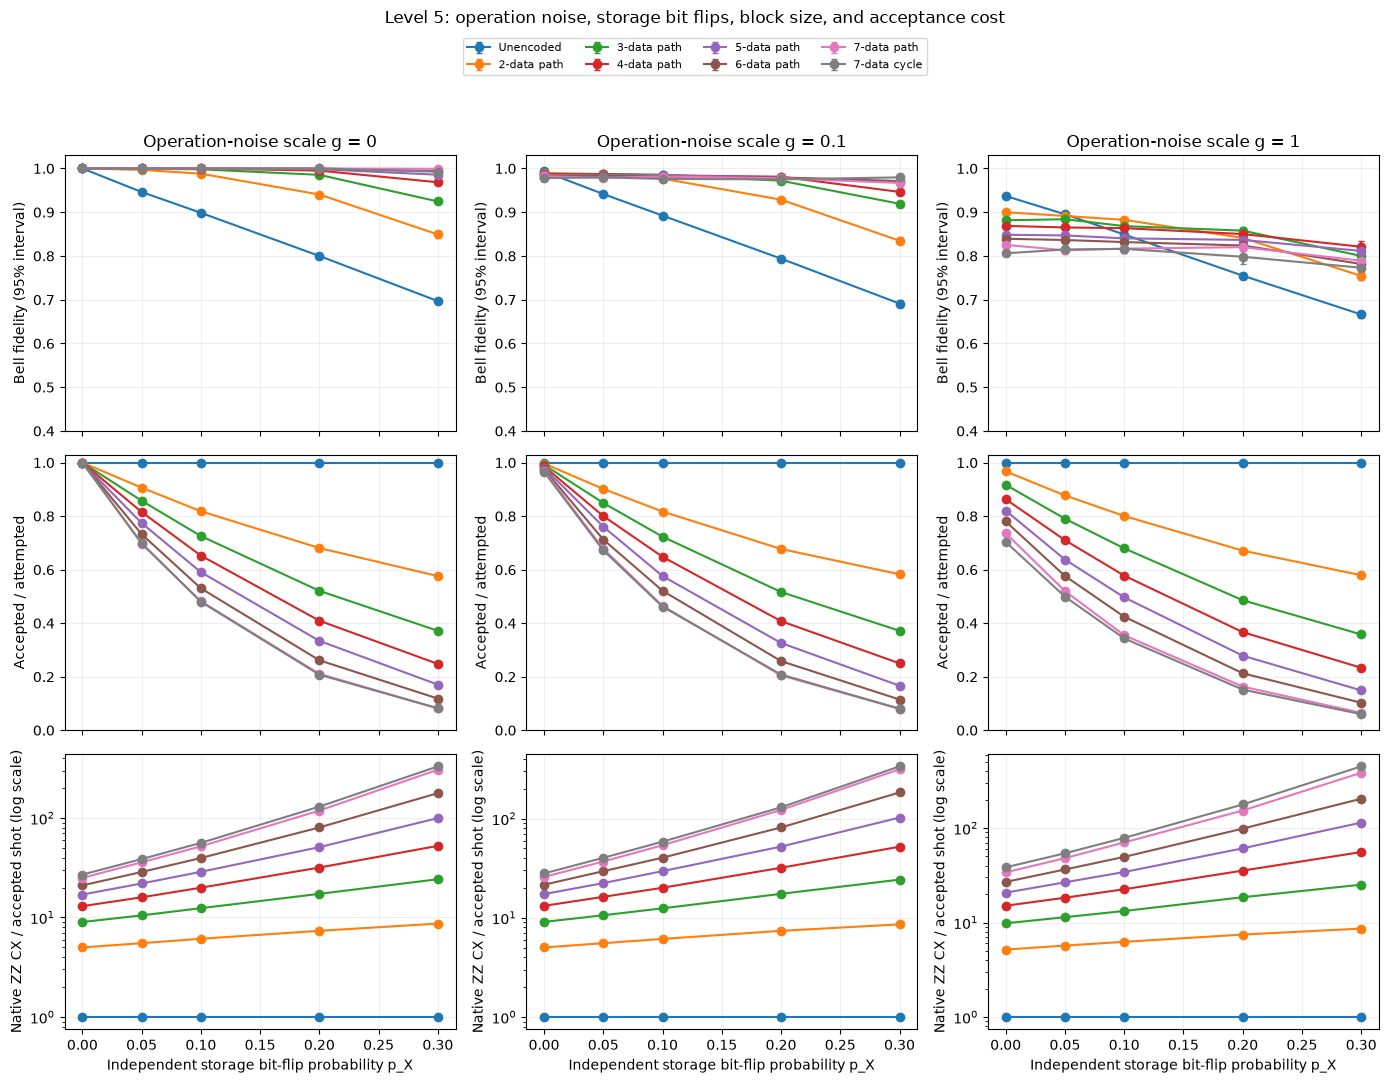

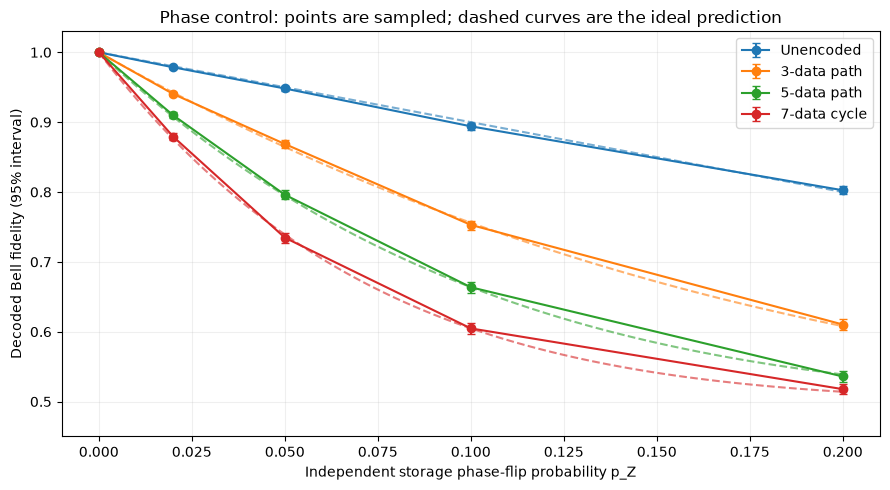

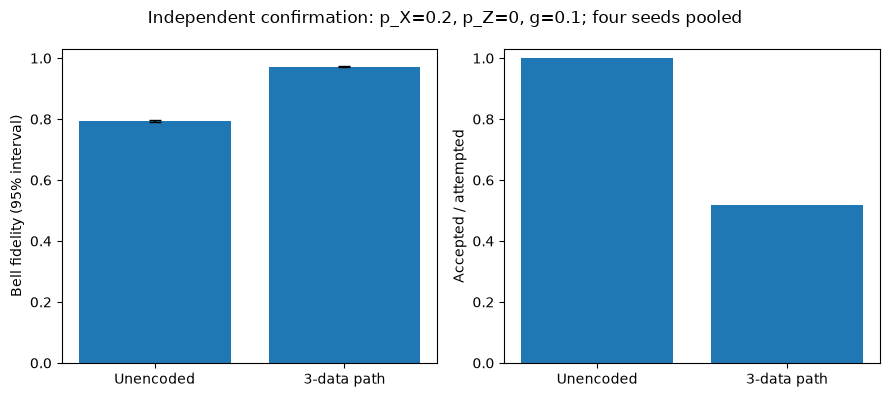

In [29]:
fig, axes = plt.subplots(3, 3, figsize=(14, 11), sharex="col")
for col, g in enumerate(gate_scales):
    for label, _, _ in level5_designs:
        subset = level5_table[(level5_table["g"] == g) & (level5_table["Design"] == label)]
        errors = np.array([[max(0, f - ci[0]), max(0, ci[1] - f)]
                           for f, ci in zip(subset["F"], subset["95% CI"])]).T
        axes[0, col].errorbar(subset["p_X"], subset["F"], yerr=errors, marker="o", capsize=2, label=label)
        axes[1, col].plot(subset["p_X"], subset["Yield"], marker="o", label=label)
        axes[2, col].plot(subset["p_X"], subset["CX / accepted shot"], marker="o", label=label)
    axes[0, col].set_title(f"Operation-noise scale g = {g:g}")
    axes[0, col].set_ylim(0.4, 1.03); axes[1, col].set_ylim(0, 1.03)
    axes[2, col].set_yscale("log")
    for row, ylabel in enumerate(("Bell fidelity (95% interval)", "Accepted / attempted",
                                  "Native ZZ CX / accepted shot (log scale)")):
        axes[row, col].set_ylabel(ylabel)
        axes[row, col].grid(alpha=0.2)
    axes[2, col].set_xlabel("Independent storage bit-flip probability p_X")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.96), ncol=4, fontsize=8)
fig.suptitle("Level 5: operation noise, storage bit flips, block size, and acceptance cost")
fig.tight_layout(rect=[0, 0, 1, 0.91]); fig.savefig(FIGURE_DIR / "level5_bitflip_sweep.png", dpi=150, bbox_inches="tight")
display(fig); plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 5))
for label, n, _ in phase_designs:
    subset = level5_phase_table[level5_phase_table["Design"] == label]
    errors = np.array([[max(0, f - ci[0]), max(0, ci[1] - f)]
                       for f, ci in zip(subset["F"], subset["95% CI"])]).T
    series = ax.errorbar(subset["p_Z"], subset["F"], yerr=errors, marker="o", capsize=3, label=label)
    fine = np.linspace(0, 0.2, 101)
    ax.plot(fine, (1 + (1 - 2 * fine)**n) / 2, linestyle="--", alpha=0.6,
            color=series.lines[0].get_color())
ax.set_xlabel("Independent storage phase-flip probability p_Z")
ax.set_ylabel("Decoded Bell fidelity (95% interval)")
ax.set_title("Phase control: points are sampled; dashed curves are the ideal prediction")
ax.set_ylim(0.45, 1.03); ax.legend(); ax.grid(alpha=0.2)
fig.tight_layout(); fig.savefig(FIGURE_DIR / "level5_phase_sweep.png", dpi=150)
display(fig); plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
labels = list(level5_confirmation_pooled)
for col, metric in enumerate(("F", "Yield")):
    values = [level5_confirmation_pooled[label][metric] for label in labels]
    errors = None
    if metric == "F":
        errors = np.array([[value - level5_confirmation_pooled[label]["95% CI"][0],
                            level5_confirmation_pooled[label]["95% CI"][1] - value]
                           for label, value in zip(labels, values)]).T
    axes[col].bar(labels, values, yerr=errors, capsize=4)
    axes[col].set_ylabel("Bell fidelity (95% interval)" if metric == "F" else "Accepted / attempted")
    axes[col].set_ylim(0, 1.03)
fig.suptitle("Independent confirmation: p_X=0.2, p_Z=0, g=0.1; four seeds pooled")
fig.tight_layout(); fig.savefig(FIGURE_DIR / "level5_confirmation.png", dpi=150)
display(fig); plt.close(fig)

In [30]:
extension_data = {
    "settings": extension_settings,
    "level4": {key: extensions.serializable_result(value) for key, value in level4_results.items()},
    "level4_table": level4_table.to_dict("records"),
    "sabre_candidates": level4_sabre_candidates.to_dict("records"),
    "ibm_ablation": {key: extensions.serializable_result(value) for key, value in level4_ablation.items()},
    "ibm_ablation_table": level4_ablation_table.to_dict("records"),
    "level5": {key: extensions.serializable_result(value) for key, value in level5_results.items()},
    "level5_table": level5_table.to_dict("records"),
    "phase_controls": {key: extensions.serializable_result(value) for key, value in level5_phase_results.items()},
    "phase_table": level5_phase_table.to_dict("records"),
    "confirmation": {key: extensions.serializable_result(value) for key, value in level5_confirmation.items()},
    "confirmation_pooled": level5_confirmation_pooled, "confirmed_gain": level5_confirmed_gain,
    "official_results_table": official_results_table.to_dict("records"),
    "official_counts": {str(case): (
        {b: LEVEL1[pid]["runs"][b]["counts"] for b in BASIS_ORDER} if level == 1
        else (level2_results if level == 2 else level3_results)[case]["counts"])
        for case, pid, level in CASES},
    "official_settings": {str(case): (
        {"Simulator seeds": {b: case_seed(case, b, 0) for b in BASIS_ORDER},
         "Shots per basis": SHOTS_PER_BASIS, "Transpiler seed": transpiler_seed(case)} if level == 1
        else (level2_results if level == 2 else level3_results)[case]["settings"])
        for case, pid, level in CASES},
    "ideal_detector_controls": level3_control_results,
}
(DATA_DIR / "optional_extension_results.json").write_text(
    json.dumps(extension_data, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)
print("Saved", len(level4_results), "transport runs,", len(level5_results), "bit-flip sweep runs,",
      len(level5_phase_results), "phase controls, and", len(level5_confirmation), "confirmation runs.")

Saved 18 transport runs, 120 bit-flip sweep runs, 20 phase controls, and 8 confirmation runs.


### Optional-study interpretation and recommendation

I would use corrected GHZ transport for the reference and hyperbolic routes
in this experiment. It raises the measured fidelity while using fewer CNOTs,
and it keeps every attempt. The IBM result needs a different explanation:

| Processor | SWAP CNOTs | GHZ CNOTs | SWAP F | Balanced GHZ F |
|---|---|---|---|---|
| Reference | 7 | 3 | 0.862488 | 0.882263 |
| IBM | 16 | 6 | 0.830566 | 0.829468 |
| Hyperbolic | 19 | 7 | 0.721558 | 0.788818 |

On the reference model we remove four noisy CNOTs; on the hyperbolic model
we remove twelve. Their higher scores fit the expectation that fewer noisy
operations leave the pair less damaged. The interior measurement results
tell us which phase correction to make, so those ideal random branches don't
have to be discarded. Left-growth and balanced-growth intervals overlap;
these samples give little reason to favor one order on fidelity alone.

IBM uses ten fewer CNOTs with GHZ, yet both methods score about 0.83.
To understand why, we kept the circuits fixed and switched error sources:

| IBM error sources | SWAP F | GHZ F |
|---|---|---|
| Gate and relaxation errors only | 0.866089 | 0.930725 |
| Readout errors only | 0.963806 | 0.886963 |
| Full calibration | 0.835205 | 0.826111 |

These component tests use fresh shots, so their full-calibration estimates
differ slightly from the first comparison table.

With gate and relaxation errors alone, GHZ benefits from its smaller circuit.
Readout reverses that advantage. GHZ uses the interior readings to decide
whether to apply Z; a wrong reading can therefore cause a wrong correction
and spoil the Bell phase. Together, the two effects largely cancel in the
full calibrated model. I would improve intermediate readout accuracy before
expecting this gate reduction to deliver higher-fidelity pairs on IBM.
The CNOT saving is already present, but we haven't measured whether it saves
elapsed time once measurements and classical correction are included.

Checking both ZZ and XX gives higher accepted scores on the reference and IBM
models, at a much higher gate cost. With ideal operations, it rejects a bit
flip, a phase flip, or both on one port qubit. These are the Pauli faults
used in the controls. With noise, reference gives F=0.902442 using
29 CNOTs per attempt; IBM gives 0.883970 using 65; hyperbolic gives 0.756993
using 77. Some attempts also fail the checks. On the hyperbolic model, GHZ
both scores higher and uses fewer gates, so I would choose GHZ. On the other
two models, I would pay for the stronger check only if the cheaper methods'
scores weren't sufficient for the application.

The SABRE comparison uses 13 CNOTs on the reference model, 31 on IBM, and 37
on the hyperbolic model. We counted the gates that return every logical
output to its required physical qubit. Under that rule, the circuit
built specifically for the known Bell-state preparation is cheaper. Other
choices of layout or allowed output mapping would need their own comparison.

For storage, I would choose three data qubits for the tested setting when
the required measured fidelity is 0.95. The setting is p_X=0.2, p_Z=0, and
g=0.1: a 20% storage bit-flip probability per data qubit, no storage phase
flips, and one-tenth of the standard operation-noise parameters. In the size
sweep, three data qubits are the least expensive tested choice whose
pointwise 95% lower fidelity bound exceeds 0.95. They cost 17.42 CNOTs per
kept ZZ result. If the requirement is only 0.90, two data qubits suffice
in that sweep and cost 7.38 CNOTs per kept result.

We also repeated the unencoded-versus-three-data comparison using fresh
random streams at the condition chosen before the sweep:

| Storage design | F | Attempts kept |
|---|---|---|
| Unencoded | 0.794769 | 100% |
| Three data qubits | 0.971821 | 51.7944% |

The improvement is 0.177052 on the fidelity scale, with a 95% interval of
[0.173591, 0.180520]. About half the attempts survive, and those kept attempts
give a score near 0.972 instead of 0.795. This supports the three-data choice
at that condition. The two-data choice came from exploring the size sweep
and needs a separate confirmation before we rely on it.

I wouldn't choose a larger block for the same 0.95 requirement simply because
it has more qubits. Three already meet that requirement here. Larger blocks
spend more gates and discard more attempts for a smaller additional gain.
At g=1 and the same storage rate, no tested block has a 0.95 lower bound.
The phase-error runs show a further limit: more data qubits give phase faults
more places to occur, while these ZZ checks still pass. Storage with substantial
Z noise needs an encoding that also checks phase errors. The closing edge's
two extra CNOTs add no independent ideal constraint or extra code distance.

For a cloud system, I recommend offering different delivery and storage
choices, with the required measured fidelity specified before comparing their
costs. On these synthetic routes, corrected GHZ is the delivery choice I would
start with. For this bit-flip storage test, three data qubits are enough for
the 0.95 requirement at g=0.1. These are separate experiments with different
ports and noise assumptions. Before combining them in a service, I would test
delivery followed by storage on the same ports and include gate durations,
measurement waits, classical correction time, and idle noise.

### Theory references

- [Zhou, Leung, and Chuang (2000)](https://doi.org/10.1103/PhysRevA.62.052316): one-bit teleportation and measurement-dependent corrections.
- [Żukowski and colleagues (1993)](https://doi.org/10.1103/PhysRevLett.71.4287): joining Bell links through entanglement swapping.
- [Gottesman (1997)](https://arxiv.org/abs/quant-ph/9705052): stabilizer checks and logical operators.


## Submission checklist

- Complete all nine cases with reproducible code and saved outputs.
- Include the three labeled coupling graphs, fixed ports and transpiled circuits.
- Report fidelity with uncertainty, circuit costs, physical qubits and postselection statistics.
- Record assumptions, package versions, shots, seeds and compilation/bootstrap settings.
- Include scientific interpretation and an evidence-backed design recommendation.
- Restart the kernel and run all cells from top to bottom before saving.
- Commit and push the notebook, supporting files and any dependency changes to your fork.
- Open a pull request to the main challenge repository by Sunday 4:00 PM, titled `Submission: <team name>`. Include team members, the notebook path, the results commit hash and reproduction steps, following the README submission instructions. Leave it open for organizer review.
